# 06 — Robustness and Reliability Analysis

## Research Objectives

This notebook investigates the robustness and
reliability of the selected LightGBM intrusion
detection model using the CICIDS2017 dataset.

The analysis focuses on:

- Minority-class detection performance
- Prediction confidence and uncertainty
- Probability calibration
- Feature perturbation sensitivity
- Model robustness under simulated disturbances
- Research limitations and generalizability

The trained model and development-only preprocessing
parameters will remain unchanged throughout the
independent evaluation.

In [1]:
import sys
import importlib
from pathlib import Path

PROJECT_ROOT = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

RESULTS_DIR = PROJECT_ROOT / "results"
CONFIG_DIR = PROJECT_ROOT / "config"

RANDOM_STATE = 42
EXPECTED_FEATURES = 69
EXPECTED_CLASSES = 15
EXPECTED_TEST_RECORDS = 504160
BATCH_SIZE = 100000

print("ROBUSTNESS AND RELIABILITY ENVIRONMENT")
print("-" * 65)

print("Python version:", sys.version.split()[0])
print("Project root:", PROJECT_ROOT)
print("Project exists:", PROJECT_ROOT.exists())
print("Results directory:", RESULTS_DIR.exists())
print("Configuration directory:", CONFIG_DIR.exists())

required_packages = [
    "numpy",
    "pandas",
    "sklearn",
    "lightgbm",
    "matplotlib",
    "seaborn",
    "joblib",
    "pyarrow",
    "scipy"
]

missing_packages = []

for package in required_packages:
    try:
        importlib.import_module(package)
        print(f"{package}: AVAILABLE")
    except ImportError:
        missing_packages.append(package)
        print(f"{package}: MISSING")

assert PROJECT_ROOT.is_dir()
assert RESULTS_DIR.is_dir()
assert CONFIG_DIR.is_dir()
assert not missing_packages, missing_packages

print("-" * 65)
print("Expected features:", EXPECTED_FEATURES)
print("Expected classes:", EXPECTED_CLASSES)
print("Expected test records:", EXPECTED_TEST_RECORDS)
print("Random state:", RANDOM_STATE)
print("Batch size:", BATCH_SIZE)
print("-" * 65)
print("Environment verification: PASS")
print("Notebook 06 initialization completed.")

ROBUSTNESS AND RELIABILITY ENVIRONMENT
-----------------------------------------------------------------
Python version: 3.12.10
Project root: C:\Users\pc\XAI-Intrusion-Detection
Project exists: True
Results directory: True
Configuration directory: True
numpy: AVAILABLE
pandas: AVAILABLE
sklearn: AVAILABLE
lightgbm: AVAILABLE
matplotlib: AVAILABLE
seaborn: AVAILABLE
joblib: AVAILABLE
pyarrow: AVAILABLE
scipy: AVAILABLE
-----------------------------------------------------------------
Expected features: 69
Expected classes: 15
Expected test records: 504160
Random state: 42
Batch size: 100000
-----------------------------------------------------------------
Environment verification: PASS
Notebook 06 initialization completed.


In [2]:
# STEP 3: RESEARCH ARTIFACT LOADING

import json
import joblib
import numpy as np
import pandas as pd

from time import perf_counter

start_time = perf_counter()

print("ROBUSTNESS RESEARCH ARTIFACT LOADING")
print("-" * 65)

required_artifacts = {
    "model": "03_lightgbm.joblib",
    "feature_names": "03_development_feature_names.joblib",
    "scaler": "03_development_scaler.joblib",
    "replacement_values": "03_development_replacement_values.joblib",
    "sentinel_features": "03_development_sentinel_features.joblib",
    "transform_replacements": "03_development_transform_replacements.joblib",
    "label_encoder": "02_label_encoder.joblib",
    "test_indices": "02_test_indices.npy",
    "development_indices": "03_development_indices.npy",
    "validation_indices": "03_validation_indices.npy",
    "reference_predictions": "04_independent_predictions.npy",
    "reference_targets": "04_independent_targets.npy",
    "evaluation_summary": "04_independent_evaluation_summary.json",
    "selected_model": "03_selected_model.json",
    "processed_data": "CICIDS2017_cleaned.parquet"
}

artifact_paths = {}

for name, filename in required_artifacts.items():

    matches = list(PROJECT_ROOT.rglob(filename))

    assert len(matches) == 1, (
        f"{filename}: Expected one file, found {len(matches)}"
    )

    artifact_paths[name] = matches[0]

    print(f"{name}: FOUND")

print("-" * 65)

model = joblib.load(artifact_paths["model"])

feature_names = list(
    joblib.load(artifact_paths["feature_names"])
)

scaler = joblib.load(artifact_paths["scaler"])

replacement_values = joblib.load(
    artifact_paths["replacement_values"]
)

sentinel_features = joblib.load(
    artifact_paths["sentinel_features"]
)

transform_replacements = joblib.load(
    artifact_paths["transform_replacements"]
)

label_encoder = joblib.load(
    artifact_paths["label_encoder"]
)

test_indices = np.load(
    artifact_paths["test_indices"]
)

development_indices = np.load(
    artifact_paths["development_indices"]
)

validation_indices = np.load(
    artifact_paths["validation_indices"]
)

reference_predictions = np.load(
    artifact_paths["reference_predictions"]
)

reference_targets = np.load(
    artifact_paths["reference_targets"]
)

with open(artifact_paths["evaluation_summary"], "r") as f:
    evaluation_summary = json.load(f)

with open(artifact_paths["selected_model"], "r") as f:
    selected_model = json.load(f)

DATA_PATH = artifact_paths["processed_data"]

print("ARTIFACT LOADING SUMMARY")
print("-" * 65)

print("Model:", type(model).__name__)
print("Features:", len(feature_names))
print("Classes:", len(label_encoder.classes_))
print("Independent test records:", len(test_indices))
print("Development records:", len(development_indices))
print("Validation records:", len(validation_indices))
print("Reference predictions:", len(reference_predictions))
print("Reference targets:", len(reference_targets))
print("Required artifacts:", len(required_artifacts))
print("Located artifacts:", len(artifact_paths))
print("Dataset size:", round(
    DATA_PATH.stat().st_size / (1024 ** 2), 2
), "MB")

print(
    f"Execution time: {perf_counter() - start_time:.2f} seconds"
)

print("-" * 65)
print("Research artifact loading completed successfully.")

ROBUSTNESS RESEARCH ARTIFACT LOADING
-----------------------------------------------------------------
model: FOUND
feature_names: FOUND
scaler: FOUND
replacement_values: FOUND
sentinel_features: FOUND
transform_replacements: FOUND
label_encoder: FOUND
test_indices: FOUND
development_indices: FOUND
validation_indices: FOUND
reference_predictions: FOUND
reference_targets: FOUND
evaluation_summary: FOUND
selected_model: FOUND
processed_data: FOUND
-----------------------------------------------------------------
ARTIFACT LOADING SUMMARY
-----------------------------------------------------------------
Model: LGBMClassifier
Features: 69
Classes: 15
Independent test records: 504160
Development records: 1613310
Validation records: 403328
Reference predictions: 504160
Reference targets: 504160
Required artifacts: 15
Located artifacts: 15
Dataset size: 305.04 MB
Execution time: 18.00 seconds
-----------------------------------------------------------------
Research artifact loading completed 

In [3]:
# STEP 4: ARTIFACT INTEGRITY VERIFICATION

import pyarrow.parquet as pq

start_time = perf_counter()

print("ROBUSTNESS ARTIFACT INTEGRITY VERIFICATION")
print("-" * 65)

source_records = pq.ParquetFile(DATA_PATH).metadata.num_rows

all_indices = np.concatenate([
    development_indices,
    validation_indices,
    test_indices
])

expected_classes = np.arange(15)

integrity_checks = {
    "Correct model type":
        type(model).__name__ == "LGBMClassifier",

    "Correct feature count":
        len(feature_names) == 69,

    "Unique feature names":
        len(set(feature_names)) == 69,

    "Model feature compatibility":
        model.n_features_in_ == len(feature_names),

    "Scaler feature compatibility":
        scaler.n_features_in_ == len(feature_names),

    "Correct class count":
        len(label_encoder.classes_) == 15,

    "Correct model classes":
        np.array_equal(model.classes_, expected_classes),

    "Correct test record count":
        len(test_indices) == 504160,

    "Unique test indices":
        len(np.unique(test_indices)) == len(test_indices),

    "No development-test overlap":
        np.intersect1d(
            development_indices, test_indices
        ).size == 0,

    "No validation-test overlap":
        np.intersect1d(
            validation_indices, test_indices
        ).size == 0,

    "No development-validation overlap":
        np.intersect1d(
            development_indices, validation_indices
        ).size == 0,

    "Valid dataset indices":
        bool(
            np.issubdtype(all_indices.dtype, np.integer)
            and all_indices.min() >= 0
            and all_indices.max() < source_records
        ),

    "Complete dataset partition":
        len(all_indices) == source_records
        and len(np.unique(all_indices)) == source_records,

    "Correct prediction dimensions":
        reference_predictions.shape == (len(test_indices),),

    "Correct target dimensions":
        reference_targets.shape == (len(test_indices),),

    "Valid prediction labels":
        np.isin(
            reference_predictions, expected_classes
        ).all(),

    "Valid target labels":
        np.isin(
            reference_targets, expected_classes
        ).all(),

    "All target classes represented":
        np.array_equal(
            np.unique(reference_targets), expected_classes
        ),

    "All required artifacts loaded":
        len(artifact_paths) == len(required_artifacts)
}

integrity_df = pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if status else "FAIL"
    }
    for name, status in integrity_checks.items()
])

display(integrity_df)

artifact_integrity_passed = all(integrity_checks.values())

print("-" * 65)
print("ARTIFACT INTEGRITY SUMMARY")
print("-" * 65)

print("Source records:", source_records)
print("Development records:", len(development_indices))
print("Validation records:", len(validation_indices))
print("Independent test records:", len(test_indices))
print("Total partition records:", len(all_indices))
print("Features:", len(feature_names))
print("Classes:", len(label_encoder.classes_))
print("Total checks:", len(integrity_checks))
print("Passed checks:", sum(integrity_checks.values()))

print(
    f"Execution time: {perf_counter() - start_time:.2f} seconds"
)

assert artifact_integrity_passed, (
    "Artifact integrity verification failed."
)

print("-" * 65)
print("Artifact integrity verification: PASS")
print("Research artifacts ready for robustness analysis.")

ROBUSTNESS ARTIFACT INTEGRITY VERIFICATION
-----------------------------------------------------------------


,Verification_Check,Status
0,Correct model type,PASS
1,Correct feature count,PASS
2,Unique feature names,PASS
3,Model feature compatibility,PASS
4,Scaler feature compatibility,PASS
5,Correct class count,PASS
6,Correct model classes,PASS
7,Correct test record count,PASS
8,Unique test indices,PASS
9,No development-test overlap,PASS


-----------------------------------------------------------------
ARTIFACT INTEGRITY SUMMARY
-----------------------------------------------------------------
Source records: 2520798
Development records: 1613310
Validation records: 403328
Independent test records: 504160
Total partition records: 2520798
Features: 69
Classes: 15
Total checks: 20
Passed checks: 20
Execution time: 8.74 seconds
-----------------------------------------------------------------
Artifact integrity verification: PASS
Research artifacts ready for robustness analysis.


In [4]:
# STEP 5: BASELINE PERFORMANCE VERIFICATION

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

start_time = perf_counter()

print("BASELINE PERFORMANCE VERIFICATION")
print("-" * 65)

y_true = np.asarray(reference_targets)
y_pred = np.asarray(reference_predictions)

assert y_true.shape == y_pred.shape
assert len(y_true) == 504160

baseline_metrics = {
    "Accuracy": accuracy_score(y_true, y_pred),

    "Balanced Accuracy":
        balanced_accuracy_score(y_true, y_pred),

    "Macro Precision":
        precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

    "Macro Recall":
        recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

    "Macro F1":
        f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

    "Weighted F1":
        f1_score(
            y_true, y_pred,
            average="weighted",
            zero_division=0
        ),

    "Matthews Correlation Coefficient":
        matthews_corrcoef(y_true, y_pred)
}

baseline_metrics_df = pd.DataFrame([
    {"Metric": name, "Value": value}
    for name, value in baseline_metrics.items()
])

display(baseline_metrics_df)

correct_predictions = int(np.sum(y_true == y_pred))
incorrect_predictions = int(np.sum(y_true != y_pred))

baseline_checks = {
    "Correct test record count":
        len(y_true) == 504160,

    "Prediction and target alignment":
        y_true.shape == y_pred.shape,

    "All 15 target classes represented":
        len(np.unique(y_true)) == 15,

    "Finite performance metrics":
        np.isfinite(list(baseline_metrics.values())).all(),

    "Complete prediction accounting":
        correct_predictions + incorrect_predictions
        == len(y_true),

    "Accuracy consistency":
        np.isclose(
            baseline_metrics["Accuracy"],
            correct_predictions / len(y_true)
        )
}

baseline_verification_df = pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if status else "FAIL"
    }
    for name, status in baseline_checks.items()
])

display(baseline_verification_df)

baseline_verification_passed = all(
    baseline_checks.values()
)

assert baseline_verification_passed

baseline_metrics_df.to_csv(
    RESULTS_DIR / "06_baseline_performance.csv",
    index=False
)

print("-" * 65)
print("BASELINE PERFORMANCE SUMMARY")
print("-" * 65)

print("Model:", type(model).__name__)
print("Test records:", len(y_true))
print("Correct predictions:", correct_predictions)
print("Incorrect predictions:", incorrect_predictions)

print(f"Accuracy: {baseline_metrics['Accuracy']:.6f}")
print(f"Macro F1: {baseline_metrics['Macro F1']:.6f}")

print("Total checks:", len(baseline_checks))
print("Passed checks:", sum(baseline_checks.values()))

print(
    f"Execution time: {perf_counter() - start_time:.2f} seconds"
)

print("-" * 65)
print("Baseline performance verification: PASS")
print("Baseline performance metrics saved.")

BASELINE PERFORMANCE VERIFICATION
-----------------------------------------------------------------


,Metric,Value
0,Accuracy,0.998675
1,Balanced Accuracy,0.934008
2,Macro Precision,0.894500
3,Macro Recall,0.934008
4,Macro F1,0.910832
5,Weighted F1,0.998732
6,Matthews Correlation Coefficient,0.995609


,Verification_Check,Status
0,Correct test record count,PASS
1,Prediction and target alignment,PASS
2,All 15 target classes represented,PASS
3,Finite performance metrics,PASS
4,Complete prediction accounting,PASS
5,Accuracy consistency,PASS


-----------------------------------------------------------------
BASELINE PERFORMANCE SUMMARY
-----------------------------------------------------------------
Model: LGBMClassifier
Test records: 504160
Correct predictions: 503492
Incorrect predictions: 668
Accuracy: 0.998675
Macro F1: 0.910832
Total checks: 6
Passed checks: 6
Execution time: 0.91 seconds
-----------------------------------------------------------------
Baseline performance verification: PASS
Baseline performance metrics saved.


In [5]:
# STEP 6: CLASS-LEVEL BASELINE RELIABILITY

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

start_time = perf_counter()

print("CLASS-LEVEL BASELINE RELIABILITY ANALYSIS")
print("-" * 65)

class_names = list(label_encoder.classes_)
class_ids = np.arange(len(class_names))

class_report = classification_report(
    y_true,
    y_pred,
    labels=class_ids,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

class_reliability_df = pd.DataFrame([
    {
        "Class": name,
        "Precision": class_report[name]["precision"],
        "Recall": class_report[name]["recall"],
        "F1_Score": class_report[name]["f1-score"],
        "Support": int(class_report[name]["support"])
    }
    for name in class_names
])

class_cm = confusion_matrix(
    y_true,
    y_pred,
    labels=class_ids
)

class_reliability_df["Correct_Predictions"] = (
    np.diag(class_cm)
)

class_reliability_df["Incorrect_Predictions"] = (
    class_cm.sum(axis=1) - np.diag(class_cm)
)

class_reliability_df["Error_Rate"] = (
    class_reliability_df["Incorrect_Predictions"]
    / class_reliability_df["Support"]
)

class_reliability_df = (
    class_reliability_df
    .sort_values("F1_Score")
    .reset_index(drop=True)
)

display(class_reliability_df.round(6))

reliability_checks = {
    "All 15 classes analysed":
        len(class_reliability_df) == 15,

    "Complete support accounting":
        class_reliability_df["Support"].sum()
        == len(y_true),

    "Correct prediction accounting":
        class_reliability_df["Correct_Predictions"].sum()
        == correct_predictions,

    "Incorrect prediction accounting":
        class_reliability_df["Incorrect_Predictions"].sum()
        == incorrect_predictions,

    "Finite reliability metrics":
        np.isfinite(
            class_reliability_df.select_dtypes(
                include=np.number
            ).to_numpy()
        ).all(),

    "Macro F1 consistency":
        np.isclose(
            class_reliability_df["F1_Score"].mean(),
            baseline_metrics["Macro F1"]
        ),

    "All classes have positive support":
        (class_reliability_df["Support"] > 0).all()
}

reliability_verification_df = pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if status else "FAIL"
    }
    for name, status in reliability_checks.items()
])

display(reliability_verification_df)

class_reliability_passed = all(
    reliability_checks.values()
)

assert class_reliability_passed

output_path = (
    RESULTS_DIR / "06_class_baseline_reliability.csv"
)

class_reliability_df.to_csv(
    output_path,
    index=False
)

print("-" * 65)
print("CLASS-LEVEL RELIABILITY SUMMARY")
print("-" * 65)

print("Classes analysed:", len(class_reliability_df))
print("Total test records:", len(y_true))

print(
    "Lowest F1 class:",
    class_reliability_df.iloc[0]["Class"]
)

print(
    "Lowest F1 score:",
    round(class_reliability_df.iloc[0]["F1_Score"], 6)
)

print(
    "Highest F1 class:",
    class_reliability_df.iloc[-1]["Class"]
)

print(
    "Highest F1 score:",
    round(class_reliability_df.iloc[-1]["F1_Score"], 6)
)

print("Total checks:", len(reliability_checks))
print("Passed checks:", sum(reliability_checks.values()))

print(
    f"Execution time: {perf_counter() - start_time:.2f} seconds"
)

print("-" * 65)
print("Class-level baseline reliability: PASS")
print("Class-level reliability results saved.")

CLASS-LEVEL BASELINE RELIABILITY ANALYSIS
-----------------------------------------------------------------


,Class,Precision,Recall,F1_Score,Support,Correct_Predictions,Incorrect_Predictions,Error_Rate
0,Web Attack - XSS,0.414773,0.561538,0.477124,130,73,57,0.438462
1,Web Attack - SQL Injection,0.600000,0.750000,0.666667,4,3,1,0.250000
2,Web Attack - Brute Force,0.776557,0.721088,0.747795,294,212,82,0.278912
3,Bot,0.671875,0.992308,0.801242,390,387,3,0.007692
4,DoS Slowhttptest,0.982092,0.996176,0.989084,1046,1042,4,0.003824
5,PortScan,0.989196,0.999394,0.994268,18139,18128,11,0.000606
6,DoS slowloris,0.995349,0.993500,0.994424,1077,1070,7,0.006500
7,DoS GoldenEye,0.990357,0.998542,0.994432,2057,2054,3,0.001458
8,DoS Hulk,0.998324,0.999566,0.998945,34569,34554,15,0.000434
9,FTP-Patator,0.999157,0.999157,0.999157,1186,1185,1,0.000843


,Verification_Check,Status
0,All 15 classes analysed,PASS
1,Complete support accounting,PASS
2,Correct prediction accounting,PASS
3,Incorrect prediction accounting,PASS
4,Finite reliability metrics,PASS
5,Macro F1 consistency,PASS
6,All classes have positive support,PASS


-----------------------------------------------------------------
CLASS-LEVEL RELIABILITY SUMMARY
-----------------------------------------------------------------
Classes analysed: 15
Total test records: 504160
Lowest F1 class: Web Attack - XSS
Lowest F1 score: 0.477124
Highest F1 class: Heartbleed
Highest F1 score: 1.0
Total checks: 7
Passed checks: 7
Execution time: 0.47 seconds
-----------------------------------------------------------------
Class-level baseline reliability: PASS
Class-level reliability results saved.


In [6]:
# STEP 7: ROBUSTNESS SAMPLE PREPARATION

start_time = perf_counter()

print("ROBUSTNESS SAMPLE PREPARATION")
print("-" * 65)

ROBUSTNESS_RANDOM_STATE = 42
MAX_SAMPLES_PER_CLASS = 1000

rng = np.random.default_rng(
    ROBUSTNESS_RANDOM_STATE
)

sample_positions = []
sample_distribution = []

for class_id, class_name in enumerate(
    label_encoder.classes_
):

    available_positions = np.flatnonzero(
        reference_targets == class_id
    )

    sample_count = min(
        MAX_SAMPLES_PER_CLASS,
        len(available_positions)
    )

    selected_positions = rng.choice(
        available_positions,
        size=sample_count,
        replace=False
    )

    sample_positions.extend(selected_positions)

    sample_distribution.append({
        "Class_ID": class_id,
        "Class": class_name,
        "Available_Records": len(
            available_positions
        ),
        "Selected_Records": sample_count
    })

robustness_sample_positions = np.sort(
    np.asarray(sample_positions, dtype=np.int64)
)

robustness_sample_indices = np.asarray(
    test_indices
)[robustness_sample_positions]

y_robustness_sample = np.asarray(
    reference_targets
)[robustness_sample_positions]

robustness_reference_predictions = np.asarray(
    reference_predictions
)[robustness_sample_positions]

robustness_distribution_df = pd.DataFrame(
    sample_distribution
)

display(robustness_distribution_df)

sample_checks = {
    "All 15 classes represented":
        len(np.unique(y_robustness_sample)) == 15,

    "No duplicate sample indices":
        len(np.unique(robustness_sample_indices))
        == len(robustness_sample_indices),

    "Independent test membership":
        np.isin(
            robustness_sample_indices,
            test_indices
        ).all(),

    "No development overlap":
        np.intersect1d(
            robustness_sample_indices,
            development_indices
        ).size == 0,

    "No validation overlap":
        np.intersect1d(
            robustness_sample_indices,
            validation_indices
        ).size == 0,

    "Target and prediction alignment":
        len(y_robustness_sample)
        == len(robustness_reference_predictions)
        == len(robustness_sample_indices),

    "Maximum class sample respected":
        (
            robustness_distribution_df[
                "Selected_Records"
            ] <= MAX_SAMPLES_PER_CLASS
        ).all(),

    "Complete sample accounting":
        robustness_distribution_df[
            "Selected_Records"
        ].sum() == len(robustness_sample_indices)
}

sample_verification_df = pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if status else "FAIL"
    }
    for name, status in sample_checks.items()
])

display(sample_verification_df)

robustness_sample_passed = all(
    sample_checks.values()
)

assert robustness_sample_passed

robustness_distribution_df.to_csv(
    RESULTS_DIR / "06_robustness_sample_distribution.csv",
    index=False
)

np.save(
    RESULTS_DIR / "06_robustness_sample_indices.npy",
    robustness_sample_indices
)

print("-" * 65)
print("ROBUSTNESS SAMPLE SUMMARY")
print("-" * 65)

print("Random state:", ROBUSTNESS_RANDOM_STATE)
print("Maximum samples per class:", MAX_SAMPLES_PER_CLASS)
print("Total sample records:", len(robustness_sample_indices))
print("Classes represented:", len(np.unique(y_robustness_sample)))
print("Total checks:", len(sample_checks))
print("Passed checks:", sum(sample_checks.values()))

print(
    f"Execution time: {perf_counter() - start_time:.2f} seconds"
)

print("-" * 65)
print("Robustness sample verification: PASS")
print("Robustness sample preparation completed.")

ROBUSTNESS SAMPLE PREPARATION
-----------------------------------------------------------------


,Class_ID,Class,Available_Records,Selected_Records
0,0,BENIGN,419012,1000
1,1,Bot,390,390
2,2,DDoS,25603,1000
3,3,DoS GoldenEye,2057,1000
4,4,DoS Hulk,34569,1000
5,5,DoS Slowhttptest,1046,1000
6,6,DoS slowloris,1077,1000
7,7,FTP-Patator,1186,1000
8,8,Heartbleed,2,2
9,9,Infiltration,7,7


,Verification_Check,Status
0,All 15 classes represented,PASS
1,No duplicate sample indices,PASS
2,Independent test membership,PASS
3,No development overlap,PASS
4,No validation overlap,PASS
5,Target and prediction alignment,PASS
6,Maximum class sample respected,PASS
7,Complete sample accounting,PASS


-----------------------------------------------------------------
ROBUSTNESS SAMPLE SUMMARY
-----------------------------------------------------------------
Random state: 42
Maximum samples per class: 1000
Total sample records: 9471
Classes represented: 15
Total checks: 8
Passed checks: 8
Execution time: 2.25 seconds
-----------------------------------------------------------------
Robustness sample verification: PASS
Robustness sample preparation completed.


In [7]:
# STEP 8A: PREPROCESSING VARIABLE VERIFICATION

print("AVAILABLE PREPROCESSING VARIABLES")
print("-" * 65)

keywords = [
    "feature",
    "scaler",
    "replacement",
    "sentinel",
    "transform",
    "path",
    "encoder"
]

for name, value in sorted(list(globals().items())):

    if name.startswith("_"):
        continue

    if any(word in name.lower() for word in keywords):

        print(
            f"{name:<45} "
            f"{type(value).__name__}"
        )

print("-" * 65)

print("Robustness sample records:",
      len(robustness_sample_indices))

print("Expected feature dimensions:",
      (len(robustness_sample_indices), 69))

print("Preprocessing variable inspection completed.")

AVAILABLE PREPROCESSING VARIABLES
-----------------------------------------------------------------
DATA_PATH                                     WindowsPath
EXPECTED_FEATURES                             int
Path                                          type
artifact_paths                                dict
feature_names                                 list
label_encoder                                 LabelEncoder
output_path                                   WindowsPath
replacement_values                            dict
scaler                                        StandardScaler
sentinel_features                             list
transform_replacements                        dict
-----------------------------------------------------------------
Robustness sample records: 9471
Expected feature dimensions: (9471, 69)
Preprocessing variable inspection completed.


In [8]:
# STEP 8B: VERIFY PREPROCESSING CONFIGURATION

import numpy as np

print("PREPROCESSING CONFIGURATION")
print("-" * 65)

print("Dataset path:", DATA_PATH)
print("Feature count:", len(feature_names))
print("Scaler feature count:", scaler.n_features_in_)

print("\nSentinel features:")
print(sentinel_features)

print("\nReplacement values:")
print(replacement_values)

print("\nTransform replacements:")
print(transform_replacements)

print("\nSample indices:")
print(np.asarray(robustness_sample_indices)[:10])

print("\nSample index dimensions:")
print(np.asarray(robustness_sample_indices).shape)

assert len(feature_names) == 69
assert scaler.n_features_in_ == 69
assert len(robustness_sample_indices) == 9471

print("-" * 65)
print("Preprocessing configuration verification: PASS")

PREPROCESSING CONFIGURATION
-----------------------------------------------------------------
Dataset path: C:\Users\pc\XAI-Intrusion-Detection\processed_data\CICIDS2017_cleaned.parquet
Feature count: 69
Scaler feature count: 69

Sentinel features:
['Init_Win_bytes_forward', 'Init_Win_bytes_backward']

Replacement values:
{'Flow IAT Min': 4.0, 'Flow Duration': 50651.0, 'Flow Packets/s': 69.4419184487, 'Flow IAT Mean': 20452.3333333333, 'Flow IAT Max': 46610.0, 'Flow Bytes/s': 3720.383787, 'min_seg_size_forward': 20.0, 'Fwd Header Length': 64.0, 'Bwd Header Length': 40.0, 'Fwd IAT Min': 3.0}

Transform replacements:
{'Flow IAT Min': 1847, 'Flow Duration': 77, 'Flow Packets/s': 77, 'Flow IAT Mean': 77, 'Flow IAT Max': 77, 'Flow Bytes/s': 57, 'min_seg_size_forward': 25, 'Fwd Header Length': 25, 'Bwd Header Length': 17, 'Fwd IAT Min': 13}

Sample indices:
[1687458 1958136 1998851 1683059 2442928 1581446 1400779 1994200  153175
 2431614]

Sample index dimensions:
(9471,)
-------------------

In [10]:
# STEP 8C: RETRIEVE VERIFIED FEATURE RECONSTRUCTION CODE

import json
from pathlib import Path

notebook_files = list(
    Path.cwd().parent.rglob(
        "05_Explainable_AI_Analysis.ipynb"
    )
)

assert notebook_files, "Notebook 05 not found."

with open(notebook_files[0], encoding="utf-8") as f:
    notebook_05 = json.load(f)

for i, cell in enumerate(notebook_05["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if "SHAP feature reconstruction completed" in source:
        print("VERIFIED RECONSTRUCTION CODE")
        print("-" * 65)
        print("Notebook cell:", i)
        print(source)
        break
else:
    print("Reconstruction cell not found.")

AssertionError: Notebook 05 not found.

In [11]:
# STEP 8D: ROBUSTNESS SAMPLE FEATURE RECONSTRUCTION

from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import joblib

start_time = perf_counter()

print("ROBUSTNESS FEATURE RECONSTRUCTION")
print("-" * 65)

project_root = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

results_dir = project_root / "results"

feature_names = list(joblib.load(
    results_dir / "03_development_feature_names.joblib"
))

scaler = joblib.load(
    results_dir / "03_development_scaler.joblib"
)

replacement_values = joblib.load(
    results_dir / "03_development_replacement_values.joblib"
)

parquet_file = pq.ParquetFile(
    project_root / "processed_data"
    / "CICIDS2017_cleaned.parquet"
)

assert len(feature_names) == 69
assert list(scaler.feature_names_in_) == feature_names
assert np.all(scaler.n_samples_seen_ == 1613310)

total_records = parquet_file.metadata.num_rows

robustness_sample_indices = np.asarray(
    robustness_sample_indices
)

sample_count = len(robustness_sample_indices)

assert total_records == 2520798
assert sample_count == 9471

assert np.issubdtype(
    robustness_sample_indices.dtype,
    np.integer
)

assert np.all(robustness_sample_indices >= 0)

assert np.all(
    robustness_sample_indices < total_records
)

assert len(
    np.unique(robustness_sample_indices)
) == sample_count

position_map = np.full(
    total_records, -1, dtype=np.int64
)

position_map[robustness_sample_indices] = np.arange(
    sample_count
)

X_robustness_sample = np.empty(
    (sample_count, 69),
    dtype=np.float32
)

written = np.zeros(sample_count, dtype=bool)

replacement_counts = {
    feature: 0
    for feature in replacement_values
}

scaler_mean_before = scaler.mean_.copy()
scaler_var_before = scaler.var_.copy()
scaler_scale_before = scaler.scale_.copy()

scaler_samples_before = np.copy(
    scaler.n_samples_seen_
)

source_offset = 0

for batch in parquet_file.iter_batches(
    batch_size=50000,
    columns=feature_names
):

    batch_end = source_offset + batch.num_rows

    local_positions = position_map[
        source_offset:batch_end
    ]

    local_mask = local_positions >= 0

    if local_mask.any():

        destinations = local_positions[local_mask]

        assert not written[destinations].any()

        sample_batch = batch.to_pandas().loc[
            local_mask, feature_names
        ].astype(np.float64)

        for feature, replacement in (
            replacement_values.items()
        ):

            values = sample_batch[feature].to_numpy()

            invalid_mask = (
                ~np.isfinite(values)
                | (values < 0)
            )

            replacement_counts[feature] += int(
                invalid_mask.sum()
            )

            sample_batch.loc[
                invalid_mask, feature
            ] = replacement

        transformed = scaler.transform(
            sample_batch
        ).astype(np.float32)

        X_robustness_sample[destinations] = transformed

        written[destinations] = True

    source_offset = batch_end


# Verify robustness feature reconstruction

robustness_reconstruction_checks = {

    "Complete source coverage":
        source_offset == total_records,

    "Complete sample coverage":
        bool(written.all()),

    "Correct feature dimensions":
        X_robustness_sample.shape == (9471, 69),

    "Correct data type":
        X_robustness_sample.dtype == np.float32,

    "All feature values finite":
        bool(np.isfinite(X_robustness_sample).all()),

    "Correct feature ordering":
        list(scaler.feature_names_in_) == feature_names,

    "Scaler parameters unchanged":
        bool(
            np.array_equal(
                scaler_mean_before, scaler.mean_
            )
            and np.array_equal(
                scaler_var_before, scaler.var_
            )
            and np.array_equal(
                scaler_scale_before, scaler.scale_
            )
            and np.array_equal(
                scaler_samples_before,
                scaler.n_samples_seen_
            )
        ),

    "Development-only scaler":
        bool(np.all(
            scaler.n_samples_seen_ == 1613310
        ))
}

display(pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }
    for name, passed in
    robustness_reconstruction_checks.items()
]))

robustness_reconstruction_passed = all(
    robustness_reconstruction_checks.values()
)

assert robustness_reconstruction_passed, (
    "Robustness feature reconstruction failed."
)

X_robustness_df = pd.DataFrame(
    X_robustness_sample,
    columns=feature_names
)

print("-" * 65)
print("ROBUSTNESS RECONSTRUCTION SUMMARY")
print("-" * 65)

print("Source records scanned:", source_offset)
print("Sample records reconstructed:", written.sum())
print("Feature shape:", X_robustness_sample.shape)
print("Data type:", X_robustness_sample.dtype)
print("Replacement counts:", replacement_counts)

print(
    "Memory usage (MB):",
    round(X_robustness_sample.nbytes / 1024**2, 2)
)

print(
    "Total checks:",
    len(robustness_reconstruction_checks)
)

print(
    "Passed checks:",
    sum(robustness_reconstruction_checks.values())
)

print(
    f"Execution time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

print("-" * 65)
print("Robustness feature reconstruction: PASS")
print("Robustness sample reconstruction completed.")

ROBUSTNESS FEATURE RECONSTRUCTION
-----------------------------------------------------------------


,Verification_Check,Status
0,Complete source coverage,PASS
1,Complete sample coverage,PASS
2,Correct feature dimensions,PASS
3,Correct data type,PASS
4,All feature values finite,PASS
5,Correct feature ordering,PASS
6,Scaler parameters unchanged,PASS
7,Development-only scaler,PASS


-----------------------------------------------------------------
ROBUSTNESS RECONSTRUCTION SUMMARY
-----------------------------------------------------------------
Source records scanned: 2520798
Sample records reconstructed: 9471
Feature shape: (9471, 69)
Data type: float32
Replacement counts: {'Flow IAT Min': 2, 'Flow Duration': 0, 'Flow Packets/s': 0, 'Flow IAT Mean': 0, 'Flow IAT Max': 0, 'Flow Bytes/s': 0, 'min_seg_size_forward': 0, 'Fwd Header Length': 0, 'Bwd Header Length': 0, 'Fwd IAT Min': 0}
Memory usage (MB): 2.49
Total checks: 8
Passed checks: 8
Execution time: 2.03 seconds
-----------------------------------------------------------------
Robustness feature reconstruction: PASS
Robustness sample reconstruction completed.


In [12]:
# STEP 9A: INSPECT PREDICTION VARIABLES

import numpy as np

assert robustness_reconstruction_passed

print("AVAILABLE PREDICTION VARIABLES")
print("-" * 65)

for name, obj in list(globals().items()):

    if name.startswith("_"):
        continue

    if any(
        keyword in name.lower()
        for keyword in [
            "model",
            "pred",
            "target",
            "position",
            "indices"
        ]
    ):

        if isinstance(obj, np.ndarray):
            print(
                f"{name}: "
                f"shape={obj.shape}, "
                f"dtype={obj.dtype}"
            )

        elif hasattr(obj, "predict"):
            print(
                f"{name}: "
                f"{type(obj).__name__}"
            )

        elif isinstance(obj, (pd.Series, pd.DataFrame)):
            print(
                f"{name}: "
                f"shape={obj.shape}"
            )

print("-" * 65)
print("Reconstructed feature shape:",
      X_robustness_sample.shape)

print("Prediction variable inspection completed.")

AVAILABLE PREDICTION VARIABLES
-----------------------------------------------------------------
model: LGBMClassifier
test_indices: shape=(504160,), dtype=int64
development_indices: shape=(1613310,), dtype=int64
validation_indices: shape=(403328,), dtype=int64
reference_predictions: shape=(504160,), dtype=int64
reference_targets: shape=(504160,), dtype=int64
all_indices: shape=(2520798,), dtype=int64
y_pred: shape=(504160,), dtype=int64
available_positions: shape=(130,), dtype=int64
selected_positions: shape=(130,), dtype=int64
robustness_sample_positions: shape=(9471,), dtype=int64
robustness_sample_indices: shape=(9471,), dtype=int64
robustness_reference_predictions: shape=(9471,), dtype=int64
position_map: shape=(2520798,), dtype=int64
local_positions: shape=(20798,), dtype=int64
-----------------------------------------------------------------
Reconstructed feature shape: (9471, 69)
Prediction variable inspection completed.


In [13]:
# STEP 9B: ROBUSTNESS PREDICTION CONSISTENCY VERIFICATION

from time import perf_counter

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score
)

start_time = perf_counter()

assert robustness_reconstruction_passed

print("ROBUSTNESS PREDICTION CONSISTENCY")
print("-" * 65)

sample_count = len(robustness_sample_indices)

assert sample_count == 9471

assert X_robustness_sample.shape == (
    sample_count, 69
)

assert np.all(robustness_sample_positions >= 0)

assert np.all(
    robustness_sample_positions < len(test_indices)
)

# Verify sample index alignment

assert np.array_equal(
    test_indices[robustness_sample_positions],
    robustness_sample_indices
)

# Extract original target labels

y_robustness_sample = np.asarray(
    reference_targets[robustness_sample_positions]
)

# Extract original reference predictions

expected_predictions = np.asarray(
    reference_predictions[
        robustness_sample_positions
    ]
)

assert np.array_equal(
    expected_predictions,
    robustness_reference_predictions
)

# Construct model input

X_robustness_df = pd.DataFrame(
    X_robustness_sample,
    columns=feature_names
)

# Generate predictions without retraining

robustness_baseline_predictions = np.asarray(
    model.predict(X_robustness_df)
)

assert robustness_baseline_predictions.shape == (
    sample_count,
)

# Compare reconstructed and original predictions

prediction_matches = (
    robustness_baseline_predictions
    == expected_predictions
)

matching_predictions = int(
    prediction_matches.sum()
)

mismatching_predictions = int(
    (~prediction_matches).sum()
)

prediction_agreement = float(
    prediction_matches.mean()
)

# Calculate sample baseline performance

robustness_baseline_accuracy = accuracy_score(
    y_robustness_sample,
    robustness_baseline_predictions
)

robustness_baseline_macro_f1 = f1_score(
    y_robustness_sample,
    robustness_baseline_predictions,
    labels=model.classes_,
    average="macro",
    zero_division=0
)

# Verification checks

prediction_consistency_checks = {

    "Correct sample count":
        sample_count == 9471,

    "Correct feature dimensions":
        X_robustness_sample.shape == (9471, 69),

    "Correct feature ordering":
        list(X_robustness_df.columns)
        == list(feature_names),

    "All feature values finite":
        bool(np.isfinite(
            X_robustness_sample
        ).all()),

    "Sample index alignment":
        bool(np.array_equal(
            test_indices[
                robustness_sample_positions
            ],
            robustness_sample_indices
        )),

    "Reference prediction alignment":
        bool(np.array_equal(
            expected_predictions,
            robustness_reference_predictions
        )),

    "Correct prediction dimensions":
        robustness_baseline_predictions.shape
        == (sample_count,),

    "Valid prediction labels":
        bool(np.isin(
            robustness_baseline_predictions,
            model.classes_
        ).all()),

    "Complete prediction accounting":
        matching_predictions
        + mismatching_predictions
        == sample_count,

    "Exact prediction agreement":
        mismatching_predictions == 0,

    "Finite baseline metrics":
        bool(np.isfinite([
            robustness_baseline_accuracy,
            robustness_baseline_macro_f1
        ]).all())
}

display(pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }
    for name, passed
    in prediction_consistency_checks.items()
]))

robustness_prediction_consistency_passed = all(
    prediction_consistency_checks.values()
)

print("-" * 65)
print("PREDICTION CONSISTENCY SUMMARY")
print("-" * 65)

print("Model:", type(model).__name__)
print("Sample records:", sample_count)
print("Features:", X_robustness_sample.shape[1])

print("Matching predictions:",
      matching_predictions)

print("Mismatching predictions:",
      mismatching_predictions)

print(f"Prediction agreement: "
      f"{prediction_agreement:.6%}")

print(f"Sample baseline accuracy: "
      f"{robustness_baseline_accuracy:.6f}")

print(f"Sample baseline macro F1: "
      f"{robustness_baseline_macro_f1:.6f}")

print("Total checks:",
      len(prediction_consistency_checks))

print("Passed checks:",
      sum(prediction_consistency_checks.values()))

print(f"Execution time: "
      f"{perf_counter() - start_time:.2f} seconds")

print("-" * 65)

assert robustness_prediction_consistency_passed, (
    "Robustness prediction consistency failed."
)

print("Prediction consistency verification: PASS")
print("Robustness baseline predictions established.")

ROBUSTNESS PREDICTION CONSISTENCY
-----------------------------------------------------------------


,Verification_Check,Status
0,Correct sample count,PASS
1,Correct feature dimensions,PASS
2,Correct feature ordering,PASS
3,All feature values finite,PASS
4,Sample index alignment,PASS
5,Reference prediction alignment,PASS
6,Correct prediction dimensions,PASS
7,Valid prediction labels,PASS
8,Complete prediction accounting,PASS
9,Exact prediction agreement,PASS


-----------------------------------------------------------------
PREDICTION CONSISTENCY SUMMARY
-----------------------------------------------------------------
Model: LGBMClassifier
Sample records: 9471
Features: 69
Matching predictions: 9471
Mismatching predictions: 0
Prediction agreement: 100.000000%
Sample baseline accuracy: 0.983529
Sample baseline macro F1: 0.927644
Total checks: 11
Passed checks: 11
Execution time: 0.94 seconds
-----------------------------------------------------------------
Prediction consistency verification: PASS
Robustness baseline predictions established.


GAUSSIAN NOISE ROBUSTNESS ANALYSIS
-----------------------------------------------------------------
Noise=0.01 | Seed=42 | Accuracy=0.234083 | Macro F1=0.186557
Noise=0.01 | Seed=43 | Accuracy=0.230387 | Macro F1=0.205268
Noise=0.01 | Seed=44 | Accuracy=0.231021 | Macro F1=0.217203
Noise=0.05 | Seed=42 | Accuracy=0.151937 | Macro F1=0.118318
Noise=0.05 | Seed=43 | Accuracy=0.150670 | Macro F1=0.117331
Noise=0.05 | Seed=44 | Accuracy=0.149826 | Macro F1=0.081502
Noise=0.10 | Seed=42 | Accuracy=0.130081 | Macro F1=0.070471
Noise=0.10 | Seed=43 | Accuracy=0.132510 | Macro F1=0.083173
Noise=0.10 | Seed=44 | Accuracy=0.133143 | Macro F1=0.063614
Noise=0.20 | Seed=42 | Accuracy=0.120684 | Macro F1=0.047310
Noise=0.20 | Seed=43 | Accuracy=0.122585 | Macro F1=0.058636
Noise=0.20 | Seed=44 | Accuracy=0.121634 | Macro F1=0.047285
Noise=0.50 | Seed=42 | Accuracy=0.112343 | Macro F1=0.035971
Noise=0.50 | Seed=43 | Accuracy=0.115616 | Macro F1=0.025433
Noise=0.50 | Seed=44 | Accuracy=0.113399 | Ma

,Noise_Level,Runs,Mean_Accuracy,Std_Accuracy,Mean_Macro_F1,Std_Macro_F1,Mean_Prediction_Agreement,Mean_Accuracy_Drop,Mean_Macro_F1_Drop
0,0.00,1,0.983529,0.000000,0.927644,0.000000,1.000000,0.000000,0.000000
1,0.01,3,0.231831,0.001976,0.203009,0.015447,0.232288,0.751698,0.724635
2,0.05,3,0.150811,0.001063,0.105717,0.020977,0.151304,0.832717,0.821927
3,0.10,3,0.131911,0.001616,0.072419,0.009924,0.132334,0.851617,0.855225
4,0.20,3,0.121634,0.000950,0.051077,0.006547,0.122092,0.861894,0.876567
5,0.50,3,0.113786,0.001671,0.028236,0.006783,0.114279,0.869743,0.899408


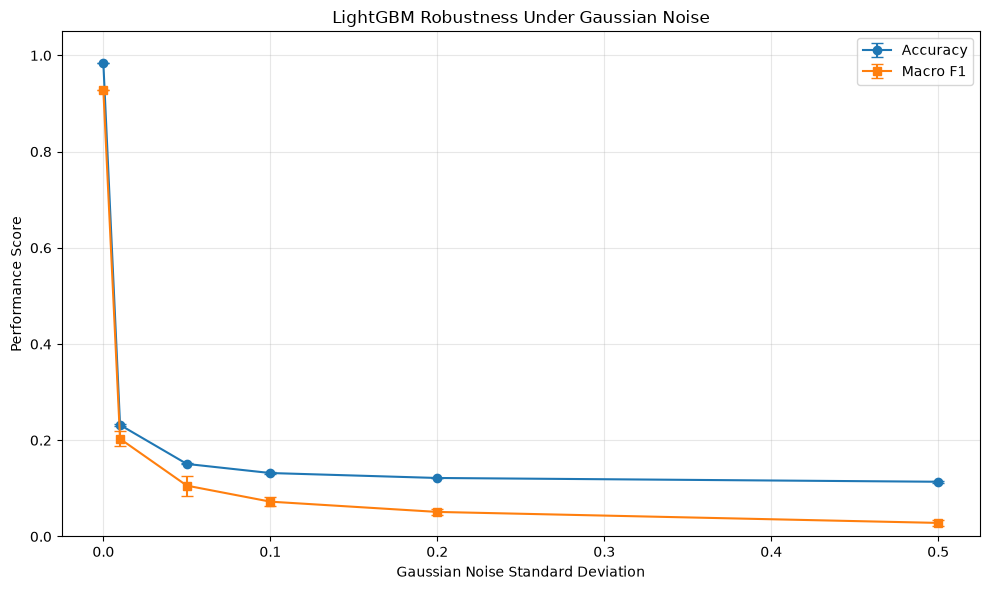

,Verification_Check,Status
0,Baseline verification passed,PASS
1,Correct sample dimensions,PASS
2,Complete experimental runs,PASS
3,Correct noise levels,PASS
4,All perturbed inputs finite,PASS
5,All prediction labels valid,PASS
6,Finite performance metrics,PASS
7,Valid performance ranges,PASS
8,Original features unchanged,PASS
9,Baseline accuracy preserved,PASS


-----------------------------------------------------------------
GAUSSIAN NOISE ROBUSTNESS SUMMARY
-----------------------------------------------------------------
Model: LGBMClassifier
Sample records: 9471
Features: 69
Noise levels: [0.01, 0.05, 0.1, 0.2, 0.5]
Random seeds: [42, 43, 44]
Perturbation experiments: 15
Baseline evaluations: 1
Total evaluations: 16
Results files saved: 2
Figures saved: 1
Total checks: 13
Passed checks: 13
Execution time: 16.13 seconds
-----------------------------------------------------------------
Gaussian noise robustness analysis: PASS
Gaussian noise experiments completed.


In [14]:
# STEP 10: GAUSSIAN NOISE ROBUSTNESS ANALYSIS

from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, f1_score

start_time = perf_counter()

assert robustness_prediction_consistency_passed

print("GAUSSIAN NOISE ROBUSTNESS ANALYSIS")
print("-" * 65)

project_root = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

results_dir = project_root / "results"
figures_dir = project_root / "figures"

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Experimental configuration

noise_levels = [0.01, 0.05, 0.10, 0.20, 0.50]

noise_seeds = [42, 43, 44]

original_features = X_robustness_sample.copy()

noise_records = []

all_inputs_finite = True
all_predictions_valid = True

# Record unperturbed baseline

noise_records.append({
    "Noise_Level": 0.0,
    "Random_Seed": -1,
    "Accuracy": robustness_baseline_accuracy,
    "Macro_F1": robustness_baseline_macro_f1,
    "Prediction_Agreement": 1.0,
    "Accuracy_Drop": 0.0,
    "Macro_F1_Drop": 0.0,
    "Changed_Predictions": 0
})

# Run controlled perturbation experiments

for noise_level in noise_levels:

    for seed in noise_seeds:

        rng = np.random.default_rng(seed)

        noise = rng.normal(
            loc=0.0,
            scale=noise_level,
            size=original_features.shape
        ).astype(np.float32)

        X_noisy = original_features + noise

        assert X_noisy.shape == (9471, 69)

        all_inputs_finite &= bool(
            np.isfinite(X_noisy).all()
        )

        assert np.isfinite(X_noisy).all()

        X_noisy_df = pd.DataFrame(
            X_noisy,
            columns=feature_names
        )

        noisy_predictions = np.asarray(
            model.predict(X_noisy_df)
        )

        assert noisy_predictions.shape == (9471,)

        all_predictions_valid &= bool(
            np.isin(
                noisy_predictions,
                model.classes_
            ).all()
        )

        noisy_accuracy = accuracy_score(
            y_robustness_sample,
            noisy_predictions
        )

        noisy_macro_f1 = f1_score(
            y_robustness_sample,
            noisy_predictions,
            labels=model.classes_,
            average="macro",
            zero_division=0
        )

        agreement = float(np.mean(
            noisy_predictions
            == robustness_baseline_predictions
        ))

        changed_predictions = int(np.sum(
            noisy_predictions
            != robustness_baseline_predictions
        ))

        noise_records.append({
            "Noise_Level": noise_level,
            "Random_Seed": seed,
            "Accuracy": noisy_accuracy,
            "Macro_F1": noisy_macro_f1,
            "Prediction_Agreement": agreement,
            "Accuracy_Drop":
                robustness_baseline_accuracy
                - noisy_accuracy,
            "Macro_F1_Drop":
                robustness_baseline_macro_f1
                - noisy_macro_f1,
            "Changed_Predictions":
                changed_predictions
        })

        print(
            f"Noise={noise_level:.2f} | "
            f"Seed={seed} | "
            f"Accuracy={noisy_accuracy:.6f} | "
            f"Macro F1={noisy_macro_f1:.6f}"
        )

# Create detailed results

gaussian_noise_df = pd.DataFrame(noise_records)

# Aggregate results across random seeds

gaussian_noise_summary = (
    gaussian_noise_df
    .groupby("Noise_Level", as_index=False)
    .agg(
        Runs=("Accuracy", "count"),
        Mean_Accuracy=("Accuracy", "mean"),
        Std_Accuracy=("Accuracy", "std"),
        Mean_Macro_F1=("Macro_F1", "mean"),
        Std_Macro_F1=("Macro_F1", "std"),
        Mean_Prediction_Agreement=(
            "Prediction_Agreement", "mean"
        ),
        Mean_Accuracy_Drop=(
            "Accuracy_Drop", "mean"
        ),
        Mean_Macro_F1_Drop=(
            "Macro_F1_Drop", "mean"
        )
    )
)

# Baseline is a single deterministic evaluation

gaussian_noise_summary[
    ["Std_Accuracy", "Std_Macro_F1"]
] = gaussian_noise_summary[
    ["Std_Accuracy", "Std_Macro_F1"]
].fillna(0.0)

# Save research results

detail_path = (
    results_dir
    / "06_gaussian_noise_detailed_results.csv"
)

summary_path = (
    results_dir
    / "06_gaussian_noise_summary.csv"
)

gaussian_noise_df.to_csv(
    detail_path, index=False
)

gaussian_noise_summary.to_csv(
    summary_path, index=False
)

display(gaussian_noise_summary.round(6))

# Generate robustness performance figure

figure_path = (
    figures_dir
    / "06_gaussian_noise_robustness.png"
)

plt.figure(figsize=(10, 6))

plt.errorbar(
    gaussian_noise_summary["Noise_Level"],
    gaussian_noise_summary["Mean_Accuracy"],
    yerr=gaussian_noise_summary["Std_Accuracy"],
    marker="o",
    capsize=4,
    label="Accuracy"
)

plt.errorbar(
    gaussian_noise_summary["Noise_Level"],
    gaussian_noise_summary["Mean_Macro_F1"],
    yerr=gaussian_noise_summary["Std_Macro_F1"],
    marker="s",
    capsize=4,
    label="Macro F1"
)

plt.xlabel("Gaussian Noise Standard Deviation")
plt.ylabel("Performance Score")

plt.title(
    "LightGBM Robustness Under Gaussian Noise"
)

plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Verification checks

metric_columns = [
    "Accuracy",
    "Macro_F1",
    "Prediction_Agreement"
]

gaussian_noise_checks = {

    "Baseline verification passed":
        robustness_prediction_consistency_passed,

    "Correct sample dimensions":
        original_features.shape == (9471, 69),

    "Complete experimental runs":
        len(gaussian_noise_df) == 16,

    "Correct noise levels":
        len(gaussian_noise_summary) == 6,

    "All perturbed inputs finite":
        all_inputs_finite,

    "All prediction labels valid":
        all_predictions_valid,

    "Finite performance metrics":
        bool(np.isfinite(
            gaussian_noise_df[metric_columns]
            .to_numpy()
        ).all()),

    "Valid performance ranges":
        bool((
            (gaussian_noise_df[metric_columns] >= 0)
            & (gaussian_noise_df[metric_columns] <= 1)
        ).all().all()),

    "Original features unchanged":
        bool(np.array_equal(
            original_features,
            X_robustness_sample
        )),

    "Baseline accuracy preserved":
        bool(np.isclose(
            gaussian_noise_df.iloc[0]["Accuracy"],
            robustness_baseline_accuracy
        )),

    "Baseline macro F1 preserved":
        bool(np.isclose(
            gaussian_noise_df.iloc[0]["Macro_F1"],
            robustness_baseline_macro_f1
        )),

    "Results files saved":
        all(
            p.exists() and p.stat().st_size > 0
            for p in [detail_path, summary_path]
        ),

    "Figure saved":
        figure_path.exists()
        and figure_path.stat().st_size > 0
}

display(pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }
    for name, passed
    in gaussian_noise_checks.items()
]))

gaussian_noise_analysis_passed = all(
    gaussian_noise_checks.values()
)

print("-" * 65)
print("GAUSSIAN NOISE ROBUSTNESS SUMMARY")
print("-" * 65)

print("Model:", type(model).__name__)
print("Sample records:", len(original_features))
print("Features:", original_features.shape[1])
print("Noise levels:", noise_levels)
print("Random seeds:", noise_seeds)
print("Perturbation experiments:", 15)
print("Baseline evaluations:", 1)
print("Total evaluations:", len(gaussian_noise_df))
print("Results files saved:", 2)
print("Figures saved:", 1)

print("Total checks:", len(gaussian_noise_checks))

print(
    "Passed checks:",
    sum(gaussian_noise_checks.values())
)

print(
    f"Execution time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

print("-" * 65)

assert gaussian_noise_analysis_passed, (
    "Gaussian noise robustness verification failed."
)

print("Gaussian noise robustness analysis: PASS")
print("Gaussian noise experiments completed.")

In [15]:
# STEP 10B: GAUSSIAN NOISE RESULTS INTERPRETATION

assert gaussian_noise_analysis_passed

print("GAUSSIAN NOISE PERFORMANCE REVIEW")
print("-" * 65)

noise_review_df = gaussian_noise_summary.copy()

display(noise_review_df.round(6))

print("-" * 65)
print("PERFORMANCE DEGRADATION BY NOISE LEVEL")
print("-" * 65)

for _, row in noise_review_df.iterrows():

    print(
        f"Noise level: {row['Noise_Level']:.2f}"
    )

    print(
        f"Mean accuracy: "
        f"{row['Mean_Accuracy']:.4%}"
    )

    print(
        f"Mean macro F1: "
        f"{row['Mean_Macro_F1']:.4%}"
    )

    print(
        f"Accuracy drop: "
        f"{row['Mean_Accuracy_Drop'] * 100:.4f} "
        "percentage points"
    )

    print(
        f"Macro F1 drop: "
        f"{row['Mean_Macro_F1_Drop'] * 100:.4f} "
        "percentage points"
    )

    print(
        f"Prediction agreement: "
        f"{row['Mean_Prediction_Agreement']:.4%}"
    )

    print("-" * 65)

print("Gaussian noise performance review completed.")

GAUSSIAN NOISE PERFORMANCE REVIEW
-----------------------------------------------------------------


,Noise_Level,Runs,Mean_Accuracy,Std_Accuracy,Mean_Macro_F1,Std_Macro_F1,Mean_Prediction_Agreement,Mean_Accuracy_Drop,Mean_Macro_F1_Drop
0,0.00,1,0.983529,0.000000,0.927644,0.000000,1.000000,0.000000,0.000000
1,0.01,3,0.231831,0.001976,0.203009,0.015447,0.232288,0.751698,0.724635
2,0.05,3,0.150811,0.001063,0.105717,0.020977,0.151304,0.832717,0.821927
3,0.10,3,0.131911,0.001616,0.072419,0.009924,0.132334,0.851617,0.855225
4,0.20,3,0.121634,0.000950,0.051077,0.006547,0.122092,0.861894,0.876567
5,0.50,3,0.113786,0.001671,0.028236,0.006783,0.114279,0.869743,0.899408


-----------------------------------------------------------------
PERFORMANCE DEGRADATION BY NOISE LEVEL
-----------------------------------------------------------------
Noise level: 0.00
Mean accuracy: 98.3529%
Mean macro F1: 92.7644%
Accuracy drop: 0.0000 percentage points
Macro F1 drop: 0.0000 percentage points
Prediction agreement: 100.0000%
-----------------------------------------------------------------
Noise level: 0.01
Mean accuracy: 23.1831%
Mean macro F1: 20.3009%
Accuracy drop: 75.1698 percentage points
Macro F1 drop: 72.4635 percentage points
Prediction agreement: 23.2288%
-----------------------------------------------------------------
Noise level: 0.05
Mean accuracy: 15.0811%
Mean macro F1: 10.5717%
Accuracy drop: 83.2717 percentage points
Macro F1 drop: 82.1927 percentage points
Prediction agreement: 15.1304%
-----------------------------------------------------------------
Noise level: 0.10
Mean accuracy: 13.1911%
Mean macro F1: 7.2419%
Accuracy drop: 85.1617 percent

In [16]:
# STEP 10C: GAUSSIAN NOISE DIAGNOSTIC VERIFICATION

from time import perf_counter

import numpy as np
import pandas as pd

start_time = perf_counter()

assert gaussian_noise_analysis_passed
assert robustness_prediction_consistency_passed

print("GAUSSIAN NOISE DIAGNOSTIC VERIFICATION")
print("-" * 65)

# Display complete performance results

review_columns = [
    "Noise_Level",
    "Mean_Accuracy",
    "Mean_Macro_F1",
    "Mean_Prediction_Agreement",
    "Std_Accuracy",
    "Std_Macro_F1"
]

print("COMPLETE PERFORMANCE RESULTS")

print(
    gaussian_noise_summary[review_columns]
    .round(6)
    .to_string(index=False)
)

# Verify prediction reproducibility without noise

clean_predictions = np.asarray(
    model.predict(
        pd.DataFrame(
            X_robustness_sample,
            columns=feature_names
        )
    )
)

clean_agreement = np.mean(
    clean_predictions
    == robustness_baseline_predictions
)

assert clean_agreement == 1.0

print("-" * 65)
print("Unperturbed prediction agreement:",
      f"{clean_agreement:.4%}")

# Investigate predicted class distributions

diagnostic_records = []

diagnostic_levels = [
    0.0, 0.01, 0.05, 0.10, 0.20, 0.50
]

for level in diagnostic_levels:

    rng = np.random.default_rng(42)

    noise = rng.normal(
        loc=0.0,
        scale=level,
        size=X_robustness_sample.shape
    ).astype(np.float32)

    diagnostic_features = (
        X_robustness_sample + noise
    )

    assert np.isfinite(
        diagnostic_features
    ).all()

    predictions = np.asarray(
        model.predict(
            pd.DataFrame(
                diagnostic_features,
                columns=feature_names
            )
        )
    )

    assert len(predictions) == 9471

    assert np.isin(
        predictions,
        model.classes_
    ).all()

    unique_labels, counts = np.unique(
        predictions,
        return_counts=True
    )

    dominant_position = np.argmax(counts)

    dominant_label = unique_labels[
        dominant_position
    ]

    dominant_class = (
        label_encoder.inverse_transform(
            [int(dominant_label)]
        )[0]
    )

    dominant_share = (
        counts[dominant_position]
        / len(predictions)
    )

    diagnostic_records.append({
        "Noise_Level": level,
        "Predicted_Classes": len(unique_labels),
        "Dominant_Class": dominant_class,
        "Dominant_Class_Share": dominant_share,
        "Prediction_Agreement": np.mean(
            predictions
            == robustness_baseline_predictions
        ),
        "Accuracy": np.mean(
            predictions == y_robustness_sample
        )
    })

gaussian_diagnostic_df = pd.DataFrame(
    diagnostic_records
)

print("-" * 65)
print("PREDICTION DISTRIBUTION DIAGNOSTICS")

print(
    gaussian_diagnostic_df
    .round(6)
    .to_string(index=False)
)

# Save diagnostic results

diagnostic_path = (
    results_dir
    / "06_gaussian_noise_diagnostics.csv"
)

gaussian_diagnostic_df.to_csv(
    diagnostic_path,
    index=False
)

# Verification

gaussian_diagnostic_checks = {

    "Previous noise analysis passed":
        gaussian_noise_analysis_passed,

    "Clean prediction agreement":
        clean_agreement == 1.0,

    "Complete diagnostic levels":
        len(gaussian_diagnostic_df) == 6,

    "Valid predicted class counts":
        bool(
            gaussian_diagnostic_df[
                "Predicted_Classes"
            ].between(1, 15).all()
        ),

    "Valid dominant class proportions":
        bool(
            gaussian_diagnostic_df[
                "Dominant_Class_Share"
            ].between(0, 1).all()
        ),

    "Diagnostic file saved":
        diagnostic_path.exists()
        and diagnostic_path.stat().st_size > 0
}

display(pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }
    for name, passed
    in gaussian_diagnostic_checks.items()
]))

gaussian_diagnostic_passed = all(
    gaussian_diagnostic_checks.values()
)

print("-" * 65)
print("GAUSSIAN DIAGNOSTIC SUMMARY")
print("-" * 65)

print("Diagnostic levels:", 6)
print("Sample records:", 9471)
print("Random seed:", 42)
print("Results files saved:", 1)

print("Total checks:",
      len(gaussian_diagnostic_checks))

print("Passed checks:",
      sum(gaussian_diagnostic_checks.values()))

print(f"Execution time: "
      f"{perf_counter() - start_time:.2f} seconds")

assert gaussian_diagnostic_passed

print("-" * 65)
print("Gaussian noise diagnostic verification: PASS")
print("Gaussian noise diagnostic analysis completed.")

GAUSSIAN NOISE DIAGNOSTIC VERIFICATION
-----------------------------------------------------------------
COMPLETE PERFORMANCE RESULTS
 Noise_Level  Mean_Accuracy  Mean_Macro_F1  Mean_Prediction_Agreement  Std_Accuracy  Std_Macro_F1
        0.00       0.983529       0.927644                   1.000000      0.000000      0.000000
        0.01       0.231831       0.203009                   0.232288      0.001976      0.015447
        0.05       0.150811       0.105717                   0.151304      0.001063      0.020977
        0.10       0.131911       0.072419                   0.132334      0.001616      0.009924
        0.20       0.121634       0.051077                   0.122092      0.000950      0.006547
        0.50       0.113786       0.028236                   0.114279      0.001671      0.006783
-----------------------------------------------------------------
Unperturbed prediction agreement: 100.0000%
-----------------------------------------------------------------
PRED

,Verification_Check,Status
0,Previous noise analysis passed,PASS
1,Clean prediction agreement,PASS
2,Complete diagnostic levels,PASS
3,Valid predicted class counts,PASS
4,Valid dominant class proportions,PASS
5,Diagnostic file saved,PASS


-----------------------------------------------------------------
GAUSSIAN DIAGNOSTIC SUMMARY
-----------------------------------------------------------------
Diagnostic levels: 6
Sample records: 9471
Random seed: 42
Results files saved: 1
Total checks: 6
Passed checks: 6
Execution time: 6.72 seconds
-----------------------------------------------------------------
Gaussian noise diagnostic verification: PASS
Gaussian noise diagnostic analysis completed.


In [17]:
# Review Gaussian noise diagnostic results

display(gaussian_diagnostic_df.round(6))

,Noise_Level,Predicted_Classes,Dominant_Class,Dominant_Class_Share,Prediction_Agreement,Accuracy
0,0.00,15,BENIGN,0.106113,1.000000,0.983529
1,0.01,14,BENIGN,0.769613,0.234083,0.234083
2,0.05,14,BENIGN,0.888396,0.152149,0.151937
3,0.10,14,BENIGN,0.922078,0.130504,0.130081
4,0.20,11,BENIGN,0.940239,0.121212,0.120684
5,0.50,10,BENIGN,0.956710,0.112765,0.112343


In [18]:
# Inspect variables for feature masking analysis

print("FEATURE MASKING PREPARATION")
print("-" * 65)

for name, value in list(globals().items()):

    if name.startswith("_"):
        continue

    if isinstance(value, (np.ndarray, pd.DataFrame, pd.Series)):

        if value.shape in [
            (9471, 69),
            (9471,)
        ]:

            print(
                f"{name}: "
                f"shape={value.shape}"
            )

print("-" * 65)
print("Model:", type(model).__name__)
print("Feature count:", len(feature_names))
print("Feature masking preparation completed.")

FEATURE MASKING PREPARATION
-----------------------------------------------------------------
robustness_sample_positions: shape=(9471,)
robustness_sample_indices: shape=(9471,)
y_robustness_sample: shape=(9471,)
robustness_reference_predictions: shape=(9471,)
X_robustness_sample: shape=(9471, 69)
written: shape=(9471,)
X_robustness_df: shape=(9471, 69)
expected_predictions: shape=(9471,)
robustness_baseline_predictions: shape=(9471,)
prediction_matches: shape=(9471,)
original_features: shape=(9471, 69)
noise: shape=(9471, 69)
X_noisy: shape=(9471, 69)
X_noisy_df: shape=(9471, 69)
noisy_predictions: shape=(9471,)
clean_predictions: shape=(9471,)
diagnostic_features: shape=(9471, 69)
predictions: shape=(9471,)
-----------------------------------------------------------------
Model: LGBMClassifier
Feature count: 69
Feature masking preparation completed.


FEATURE MASKING ROBUSTNESS ANALYSIS
-----------------------------------------------------------------
Masking: 5% | Seed: 42 | Accuracy: 0.921339 | Macro F1: 0.886102
Masking: 5% | Seed: 43 | Accuracy: 0.924929 | Macro F1: 0.890664
Masking: 5% | Seed: 44 | Accuracy: 0.921233 | Macro F1: 0.887923
Masking: 10% | Seed: 42 | Accuracy: 0.830641 | Macro F1: 0.808997
Masking: 10% | Seed: 43 | Accuracy: 0.837610 | Macro F1: 0.837921
Masking: 10% | Seed: 44 | Accuracy: 0.832119 | Macro F1: 0.809940
Masking: 20% | Seed: 42 | Accuracy: 0.607856 | Macro F1: 0.645059
Masking: 20% | Seed: 43 | Accuracy: 0.623271 | Macro F1: 0.650977
Masking: 20% | Seed: 44 | Accuracy: 0.614402 | Macro F1: 0.573900
Masking: 30% | Seed: 42 | Accuracy: 0.412522 | Macro F1: 0.498154
Masking: 30% | Seed: 43 | Accuracy: 0.413473 | Macro F1: 0.464432
Masking: 30% | Seed: 44 | Accuracy: 0.414845 | Macro F1: 0.406899
Masking: 50% | Seed: 42 | Accuracy: 0.182874 | Macro F1: 0.153514
Masking: 50% | Seed: 43 | Accuracy: 0.18424

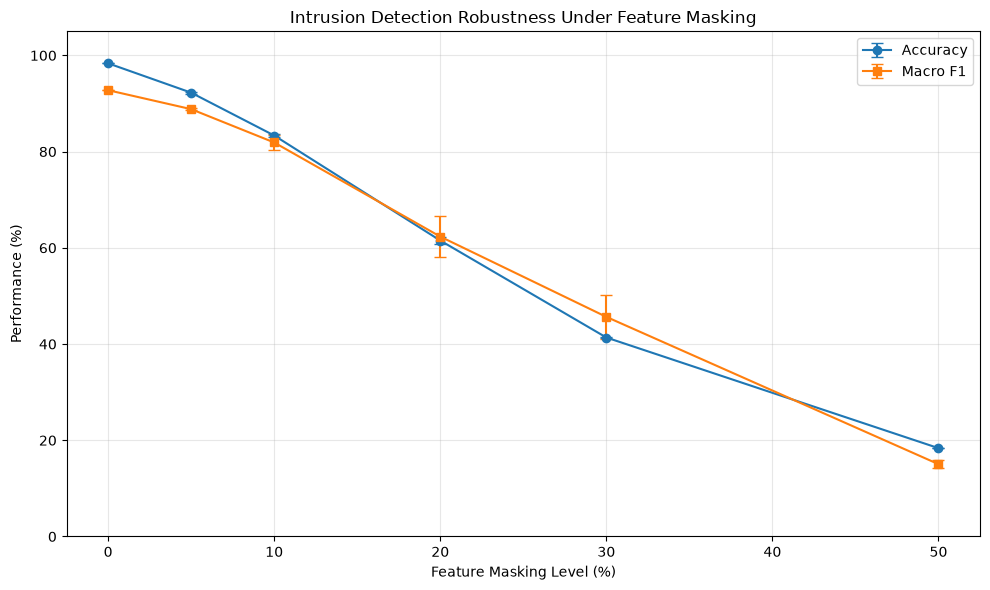

,Verification_Check,Status
0,Correct sample dimensions,PASS
1,All target classes represented,PASS
2,Complete masking experiments,PASS
3,Complete masking levels,PASS
4,Correct repetitions,PASS
5,Original features unchanged,PASS
6,Baseline predictions unchanged,PASS
7,Finite evaluation metrics,PASS
8,Valid masking rates,PASS
9,Masking rate consistency,PASS


,Masking_Level,Experiments,Mean_Actual_Masking_Rate,Mean_Accuracy,Std_Accuracy,Mean_Macro_Precision,Mean_Macro_Recall,Mean_Macro_F1,Std_Macro_F1,Mean_Prediction_Agreement,Mean_Accuracy_Drop_PP,Mean_Macro_F1_Drop_PP
0,0.00,1,0.000000,0.983529,0.000000,0.922949,0.934129,0.927644,0.000000,1.000000,0.000000,0.000000
1,0.05,3,0.049651,0.922500,0.002104,0.903695,0.881337,0.888230,0.002296,0.932460,6.102840,3.941451
2,0.10,3,0.099929,0.833457,0.003672,0.881274,0.789041,0.818953,0.016434,0.840425,15.007215,10.869154
3,0.20,3,0.199914,0.615176,0.007737,0.836073,0.550062,0.623312,0.042894,0.617006,36.835251,30.433203
4,0.30,3,0.299951,0.413613,0.001168,0.793614,0.387634,0.456495,0.046142,0.414212,56.991518,47.114958
5,0.50,3,0.499866,0.183648,0.000703,0.705087,0.146840,0.150304,0.008136,0.184176,79.988034,77.734012


-----------------------------------------------------------------
FEATURE MASKING ROBUSTNESS SUMMARY
-----------------------------------------------------------------
Model: LGBMClassifier
Sample records: 9471
Features: 69
Masking levels: [0.05, 0.1, 0.2, 0.3, 0.5]
Random seeds: [42, 43, 44]
Masking experiments: 15
Baseline evaluations: 1
Total evaluations: 16
Results files saved: 2
Figures saved: 1
Total checks: 13
Passed checks: 13
Execution time: 18.91 seconds
-----------------------------------------------------------------
Feature masking robustness analysis: PASS
Feature masking experiments completed.


In [19]:
# Step 11 - Feature masking robustness analysis

from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

start_time = perf_counter()

print("FEATURE MASKING ROBUSTNESS ANALYSIS")
print("-" * 65)

# Experimental configuration

masking_levels = [0.05, 0.10, 0.20, 0.30, 0.50]
masking_seeds = [42, 43, 44]

project_root = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

results_dir = project_root / "results"
figures_dir = project_root / "figures"

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Prepare original sample

masking_original_features = (
    X_robustness_df.to_numpy(
        dtype=np.float32,
        copy=True
    )
)

masking_targets = np.asarray(
    y_robustness_sample
).ravel()

masking_baseline_predictions = np.asarray(
    robustness_baseline_predictions
).ravel()

masking_classes = np.asarray(model.classes_)

assert masking_original_features.shape == (9471, 69)
assert len(masking_targets) == 9471
assert len(masking_baseline_predictions) == 9471
assert len(masking_classes) == 15
assert np.isfinite(masking_original_features).all()

# Preserve original features

masking_original_snapshot = (
    masking_original_features.copy()
)

# Confirm baseline prediction consistency

masking_clean_predictions = model.predict(
    pd.DataFrame(
        masking_original_features,
        columns=feature_names
    )
)

assert np.array_equal(
    masking_clean_predictions,
    masking_baseline_predictions
)

# Baseline metrics

masking_baseline_accuracy = accuracy_score(
    masking_targets,
    masking_baseline_predictions
)

masking_baseline_f1 = f1_score(
    masking_targets,
    masking_baseline_predictions,
    labels=masking_classes,
    average="macro",
    zero_division=0
)

masking_results = []

# Evaluation function

def evaluate_masking(
    predictions,
    masking_level,
    seed,
    actual_masking_rate
):

    accuracy = accuracy_score(
        masking_targets,
        predictions
    )

    macro_f1 = f1_score(
        masking_targets,
        predictions,
        labels=masking_classes,
        average="macro",
        zero_division=0
    )

    return {
        "Masking_Level": masking_level,

        "Random_Seed": seed,

        "Actual_Masking_Rate":
            actual_masking_rate,

        "Accuracy": accuracy,

        "Macro_Precision": precision_score(
            masking_targets,
            predictions,
            labels=masking_classes,
            average="macro",
            zero_division=0
        ),

        "Macro_Recall": recall_score(
            masking_targets,
            predictions,
            labels=masking_classes,
            average="macro",
            zero_division=0
        ),

        "Macro_F1": macro_f1,

        "Prediction_Agreement": float(
            np.mean(
                predictions ==
                masking_baseline_predictions
            )
        ),

        "Accuracy_Drop_PP":
            100 * (
                masking_baseline_accuracy -
                accuracy
            ),

        "Macro_F1_Drop_PP":
            100 * (
                masking_baseline_f1 -
                macro_f1
            )
    }

# Record baseline

masking_results.append(
    evaluate_masking(
        masking_baseline_predictions,
        0.0,
        -1,
        0.0
    )
)

# Run masking experiments

for level in masking_levels:

    for seed in masking_seeds:

        rng = np.random.default_rng(seed)

        X_masked = (
            masking_original_features.copy()
        )

        feature_mask = (
            rng.random(X_masked.shape) < level
        )

        # Development mean replacement
        # Zero represents the mean in scaled space

        X_masked[feature_mask] = 0.0

        actual_rate = float(
            feature_mask.mean()
        )

        assert X_masked.shape == (9471, 69)
        assert np.isfinite(X_masked).all()

        assert np.array_equal(
            X_masked[~feature_mask],
            masking_original_features[~feature_mask]
        )

        X_masked_df = pd.DataFrame(
            X_masked,
            columns=feature_names
        )

        masked_predictions = model.predict(
            X_masked_df
        )

        assert len(masked_predictions) == 9471

        masking_results.append(
            evaluate_masking(
                masked_predictions,
                level,
                seed,
                actual_rate
            )
        )

        print(
            f"Masking: {level:.0%} | "
            f"Seed: {seed} | "
            f"Accuracy: "
            f"{masking_results[-1]['Accuracy']:.6f} | "
            f"Macro F1: "
            f"{masking_results[-1]['Macro_F1']:.6f}"
        )

# Create detailed results

feature_masking_results_df = pd.DataFrame(
    masking_results
)

# Aggregate results across seeds

feature_masking_summary_df = (
    feature_masking_results_df
    .groupby("Masking_Level", as_index=False)
    .agg(
        Experiments=("Accuracy", "count"),

        Mean_Actual_Masking_Rate=(
            "Actual_Masking_Rate", "mean"
        ),

        Mean_Accuracy=("Accuracy", "mean"),

        Std_Accuracy=("Accuracy", "std"),

        Mean_Macro_Precision=(
            "Macro_Precision", "mean"
        ),

        Mean_Macro_Recall=(
            "Macro_Recall", "mean"
        ),

        Mean_Macro_F1=("Macro_F1", "mean"),

        Std_Macro_F1=("Macro_F1", "std"),

        Mean_Prediction_Agreement=(
            "Prediction_Agreement", "mean"
        ),

        Mean_Accuracy_Drop_PP=(
            "Accuracy_Drop_PP", "mean"
        ),

        Mean_Macro_F1_Drop_PP=(
            "Macro_F1_Drop_PP", "mean"
        )
    )
)

feature_masking_summary_df[
    ["Std_Accuracy", "Std_Macro_F1"]
] = feature_masking_summary_df[
    ["Std_Accuracy", "Std_Macro_F1"]
].fillna(0)

# Save results

masking_details_path = (
    results_dir /
    "06_feature_masking_results.csv"
)

masking_summary_path = (
    results_dir /
    "06_feature_masking_summary.csv"
)

feature_masking_results_df.to_csv(
    masking_details_path,
    index=False
)

feature_masking_summary_df.to_csv(
    masking_summary_path,
    index=False
)

# Generate robustness figure

plt.figure(figsize=(10, 6))

masking_percentages = (
    feature_masking_summary_df[
        "Masking_Level"
    ] * 100
)

plt.errorbar(
    masking_percentages,
    feature_masking_summary_df[
        "Mean_Accuracy"
    ] * 100,
    yerr=feature_masking_summary_df[
        "Std_Accuracy"
    ] * 100,
    marker="o",
    capsize=4,
    label="Accuracy"
)

plt.errorbar(
    masking_percentages,
    feature_masking_summary_df[
        "Mean_Macro_F1"
    ] * 100,
    yerr=feature_masking_summary_df[
        "Std_Macro_F1"
    ] * 100,
    marker="s",
    capsize=4,
    label="Macro F1"
)

plt.xlabel("Feature Masking Level (%)")
plt.ylabel("Performance (%)")

plt.title(
    "Intrusion Detection Robustness "
    "Under Feature Masking"
)

plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

masking_figure_path = (
    figures_dir /
    "06_feature_masking_robustness.png"
)

plt.savefig(
    masking_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Verification checks

feature_masking_checks = {

    "Correct sample dimensions":
        masking_original_features.shape ==
        (9471, 69),

    "All target classes represented":
        len(np.unique(masking_targets)) == 15,

    "Complete masking experiments":
        len(feature_masking_results_df) == 16,

    "Complete masking levels":
        len(feature_masking_summary_df) == 6,

    "Correct repetitions":
        feature_masking_summary_df[
            "Experiments"
        ].tolist() == [1, 3, 3, 3, 3, 3],

    "Original features unchanged":
        np.array_equal(
            masking_original_features,
            masking_original_snapshot
        ),

    "Baseline predictions unchanged":
        np.array_equal(
            masking_clean_predictions,
            masking_baseline_predictions
        ),

    "Finite evaluation metrics":
        bool(
            np.isfinite(
                feature_masking_results_df
                .select_dtypes(include=np.number)
                .to_numpy()
            ).all()
        ),

    "Valid masking rates":
        bool(
            feature_masking_results_df[
                "Actual_Masking_Rate"
            ].between(0, 1).all()
        ),

    "Masking rate consistency":
        bool(
            np.allclose(
                feature_masking_results_df[
                    "Actual_Masking_Rate"
                ],
                feature_masking_results_df[
                    "Masking_Level"
                ],
                atol=0.005,
                rtol=0
            )
        ),

    "Detailed results saved":
        masking_details_path.is_file()
        and masking_details_path.stat().st_size > 0,

    "Summary results saved":
        masking_summary_path.is_file()
        and masking_summary_path.stat().st_size > 0,

    "Robustness figure saved":
        masking_figure_path.is_file()
        and masking_figure_path.stat().st_size > 0
}

display(pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }
    for name, passed in
    feature_masking_checks.items()
]))

feature_masking_passed = all(
    feature_masking_checks.values()
)

display(feature_masking_summary_df.round(6))

print("-" * 65)
print("FEATURE MASKING ROBUSTNESS SUMMARY")
print("-" * 65)

print("Model:", type(model).__name__)
print("Sample records:", len(masking_targets))
print("Features:", len(feature_names))
print("Masking levels:", masking_levels)
print("Random seeds:", masking_seeds)
print("Masking experiments:", 15)
print("Baseline evaluations:", 1)
print("Total evaluations:", len(masking_results))
print("Results files saved:", 2)
print("Figures saved:", 1)

print(
    "Total checks:",
    len(feature_masking_checks)
)

print(
    "Passed checks:",
    sum(feature_masking_checks.values())
)

print(
    f"Execution time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

print("-" * 65)

assert feature_masking_passed, (
    "Feature masking verification failed."
)

print("Feature masking robustness analysis: PASS")
print("Feature masking experiments completed.")

In [20]:
# Step 11B - Feature masking performance review

print("FEATURE MASKING PERFORMANCE REVIEW")
print("-" * 65)

for _, row in feature_masking_summary_df.iterrows():

    print(
        f"Masking level: "
        f"{row['Masking_Level']:.0%}"
    )

    print(
        f"Mean accuracy: "
        f"{row['Mean_Accuracy']:.4%}"
    )

    print(
        f"Mean macro F1: "
        f"{row['Mean_Macro_F1']:.4%}"
    )

    print(
        f"Accuracy standard deviation: "
        f"{row['Std_Accuracy'] * 100:.4f} "
        "percentage points"
    )

    print(
        f"Macro F1 standard deviation: "
        f"{row['Std_Macro_F1'] * 100:.4f} "
        "percentage points"
    )

    print(
        f"Accuracy drop: "
        f"{row['Mean_Accuracy_Drop_PP']:.4f} "
        "percentage points"
    )

    print(
        f"Macro F1 drop: "
        f"{row['Mean_Macro_F1_Drop_PP']:.4f} "
        "percentage points"
    )

    print(
        f"Prediction agreement: "
        f"{row['Mean_Prediction_Agreement']:.4%}"
    )

    print("-" * 65)

print("Feature masking performance review completed.")

FEATURE MASKING PERFORMANCE REVIEW
-----------------------------------------------------------------
Masking level: 0%
Mean accuracy: 98.3529%
Mean macro F1: 92.7644%
Accuracy standard deviation: 0.0000 percentage points
Macro F1 standard deviation: 0.0000 percentage points
Accuracy drop: 0.0000 percentage points
Macro F1 drop: 0.0000 percentage points
Prediction agreement: 100.0000%
-----------------------------------------------------------------
Masking level: 5%
Mean accuracy: 92.2500%
Mean macro F1: 88.8230%
Accuracy standard deviation: 0.2104 percentage points
Macro F1 standard deviation: 0.2296 percentage points
Accuracy drop: 6.1028 percentage points
Macro F1 drop: 3.9415 percentage points
Prediction agreement: 93.2460%
-----------------------------------------------------------------
Masking level: 10%
Mean accuracy: 83.3457%
Mean macro F1: 81.8953%
Accuracy standard deviation: 0.3672 percentage points
Macro F1 standard deviation: 1.6434 percentage points
Accuracy drop: 15.007

In [21]:
# Step 11C - Complete feature masking results

masking_review_df = feature_masking_summary_df[
    [
        "Masking_Level",
        "Mean_Accuracy",
        "Mean_Macro_F1",
        "Mean_Prediction_Agreement",
        "Mean_Accuracy_Drop_PP",
        "Mean_Macro_F1_Drop_PP"
    ]
].copy()

display(masking_review_df.round(6))

print("-" * 65)
print("Complete feature masking results displayed.")

,Masking_Level,Mean_Accuracy,Mean_Macro_F1,Mean_Prediction_Agreement,Mean_Accuracy_Drop_PP,Mean_Macro_F1_Drop_PP
0,0.00,0.983529,0.927644,1.000000,0.000000,0.000000
1,0.05,0.922500,0.888230,0.932460,6.102840,3.941451
2,0.10,0.833457,0.818953,0.840425,15.007215,10.869154
3,0.20,0.615176,0.623312,0.617006,36.835251,30.433203
4,0.30,0.413613,0.456495,0.414212,56.991518,47.114958
5,0.50,0.183648,0.150304,0.184176,79.988034,77.734012


-----------------------------------------------------------------
Complete feature masking results displayed.


In [22]:
# Step 12A - Class-level robustness preparation

import numpy as np
import pandas as pd

print("CLASS-LEVEL ROBUSTNESS PREPARATION")
print("-" * 65)

required_variables = [
    "model",
    "feature_names",
    "label_encoder",
    "X_robustness_sample",
    "X_robustness_df",
    "y_robustness_sample",
    "robustness_baseline_predictions",
    "gaussian_diagnostic_df",
    "feature_masking_summary_df"
]

namespace = globals().copy()

for name in required_variables:

    if name in namespace:

        value = namespace[name]

        print(
            f"{name}: "
            f"{type(value).__name__}, "
            f"shape={getattr(value, 'shape', 'N/A')}"
        )

    else:

        print(f"{name}: NOT FOUND")

print("-" * 65)
print("AVAILABLE EXPERIMENT VARIABLES")
print("-" * 65)

for name, value in namespace.items():

    if name.startswith("_"):
        continue

    if any(
        keyword in name.lower()
        for keyword in [
            "gaussian",
            "masking",
            "noise",
            "seed"
        ]
    ):

        print(
            f"{name}: "
            f"{type(value).__name__}, "
            f"shape={getattr(value, 'shape', 'N/A')}"
        )

print("-" * 65)
print("CLASS LABELS")

for index, label in enumerate(label_encoder.classes_):

    print(f"{index:2d}: {label}")

print("-" * 65)
print("Class-level robustness preparation completed.")

CLASS-LEVEL ROBUSTNESS PREPARATION
-----------------------------------------------------------------
model: LGBMClassifier, shape=N/A
feature_names: list, shape=N/A
label_encoder: LabelEncoder, shape=N/A
X_robustness_sample: ndarray, shape=(9471, 69)
X_robustness_df: DataFrame, shape=(9471, 69)
y_robustness_sample: ndarray, shape=(9471,)
robustness_baseline_predictions: ndarray, shape=(9471,)
gaussian_diagnostic_df: DataFrame, shape=(6, 6)
feature_masking_summary_df: DataFrame, shape=(6, 12)
-----------------------------------------------------------------
AVAILABLE EXPERIMENT VARIABLES
-----------------------------------------------------------------
noise_levels: list, shape=N/A
noise_seeds: list, shape=N/A
noise_records: list, shape=N/A
noise_level: float, shape=N/A
seed: int, shape=N/A
noise: ndarray, shape=(9471, 69)
gaussian_noise_df: DataFrame, shape=(16, 8)
gaussian_noise_summary: DataFrame, shape=(6, 9)
gaussian_noise_checks: dict, shape=N/A
gaussian_noise_analysis_passed: boo

In [23]:
# Step 12B - Class-level robustness baseline

from time import perf_counter
from sklearn.metrics import (
    precision_recall_fscore_support,
    f1_score
)

import numpy as np
import pandas as pd

start_time = perf_counter()

print("CLASS-LEVEL ROBUSTNESS BASELINE")
print("-" * 65)

class_labels = np.arange(len(label_encoder.classes_))

baseline_targets = np.asarray(
    y_robustness_sample
)

baseline_predictions = np.asarray(
    robustness_baseline_predictions
)

assert baseline_targets.shape == (9471,)
assert baseline_predictions.shape == (9471,)
assert len(class_labels) == 15

precision, recall, f1, support = (
    precision_recall_fscore_support(
        baseline_targets,
        baseline_predictions,
        labels=class_labels,
        zero_division=0
    )
)

class_robustness_baseline_df = pd.DataFrame({

    "Class_ID": class_labels,

    "Class_Name": label_encoder.classes_,

    "Baseline_Precision": precision,

    "Baseline_Recall": recall,

    "Baseline_F1": f1,

    "Support": support

})

baseline_macro_f1 = f1_score(
    baseline_targets,
    baseline_predictions,
    labels=class_labels,
    average="macro",
    zero_division=0
)

# Verification checks

class_baseline_checks = {

    "Correct number of classes":
        len(class_robustness_baseline_df) == 15,

    "Complete sample accounting":
        int(support.sum()) == 9471,

    "All classes represented":
        bool((support > 0).all()),

    "Valid precision values":
        bool(((precision >= 0) &
              (precision <= 1)).all()),

    "Valid recall values":
        bool(((recall >= 0) &
              (recall <= 1)).all()),

    "Valid F1 values":
        bool(((f1 >= 0) &
              (f1 <= 1)).all()),

    "Finite performance metrics":
        bool(np.isfinite(
            np.concatenate([precision, recall, f1])
        ).all()),

    "Macro F1 consistency":
        bool(np.isclose(
            f1.mean(),
            baseline_macro_f1
        )),

    "Reference prediction agreement":
        bool(np.array_equal(
            baseline_predictions,
            robustness_reference_predictions
        ))
}

display(
    class_robustness_baseline_df.round(6)
)

display(pd.DataFrame([

    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }

    for name, passed in class_baseline_checks.items()

]))

assert all(class_baseline_checks.values()), (
    "Class-level robustness baseline failed."
)

class_robustness_baseline_passed = True

print("-" * 65)
print("CLASS-LEVEL ROBUSTNESS BASELINE SUMMARY")
print("-" * 65)

print("Model:", type(model).__name__)
print("Classes analysed:", len(class_labels))
print("Sample records:", len(baseline_targets))
print("Baseline macro F1:", round(baseline_macro_f1, 6))

print(
    "Lowest F1 class:",
    label_encoder.classes_[np.argmin(f1)]
)

print("Lowest F1 score:", round(f1.min(), 6))

print(
    "Highest F1 class:",
    label_encoder.classes_[np.argmax(f1)]
)

print("Highest F1 score:", round(f1.max(), 6))

print("Minimum class support:", support.min())
print("Maximum class support:", support.max())

print("Total checks:", len(class_baseline_checks))
print("Passed checks:", sum(class_baseline_checks.values()))

print(
    f"Execution time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

print("-" * 65)
print("Class-level robustness baseline: PASS")
print("Class-level baseline established.")

CLASS-LEVEL ROBUSTNESS BASELINE
-----------------------------------------------------------------


,Class_ID,Class_Name,Baseline_Precision,Baseline_Recall,Baseline_F1,Support
0,0,BENIGN,0.995025,1.000000,0.997506,1000
1,1,Bot,1.000000,0.992308,0.996139,390
2,2,DDoS,1.000000,1.000000,1.000000,1000
3,3,DoS GoldenEye,0.999000,0.999000,0.999000,1000
4,4,DoS Hulk,0.998004,1.000000,0.999001,1000
5,5,DoS Slowhttptest,0.996997,0.996000,0.996498,1000
6,6,DoS slowloris,0.995992,0.994000,0.994995,1000
7,7,FTP-Patator,1.000000,0.999000,0.999500,1000
8,8,Heartbleed,1.000000,1.000000,1.000000,2
9,9,Infiltration,1.000000,1.000000,1.000000,7


,Verification_Check,Status
0,Correct number of classes,PASS
1,Complete sample accounting,PASS
2,All classes represented,PASS
3,Valid precision values,PASS
4,Valid recall values,PASS
5,Valid F1 values,PASS
6,Finite performance metrics,PASS
7,Macro F1 consistency,PASS
8,Reference prediction agreement,PASS


-----------------------------------------------------------------
CLASS-LEVEL ROBUSTNESS BASELINE SUMMARY
-----------------------------------------------------------------
Model: LGBMClassifier
Classes analysed: 15
Sample records: 9471
Baseline macro F1: 0.927644
Lowest F1 class: Web Attack - XSS
Lowest F1 score: 0.514085
Highest F1 class: DDoS
Highest F1 score: 1.0
Minimum class support: 2
Maximum class support: 1000
Total checks: 9
Passed checks: 9
Execution time: 0.04 seconds
-----------------------------------------------------------------
Class-level robustness baseline: PASS
Class-level baseline established.


In [24]:
# Step 12C - Class-level Gaussian noise robustness

from time import perf_counter
from sklearn.metrics import precision_recall_fscore_support

import numpy as np
import pandas as pd

start_time = perf_counter()

assert class_robustness_baseline_passed

print("CLASS-LEVEL GAUSSIAN NOISE ROBUSTNESS")
print("-" * 65)

class_noise_levels = [
    0.01, 0.05, 0.10, 0.20, 0.50
]

class_noise_seeds = [42, 43, 44]

class_noise_features = X_robustness_df.to_numpy(
    dtype=np.float32,
    copy=True
)

class_noise_targets = np.asarray(
    y_robustness_sample
)

class_noise_baseline = np.asarray(
    robustness_baseline_predictions
)

class_noise_labels = np.arange(
    len(label_encoder.classes_)
)

assert class_noise_features.shape == (9471, 69)
assert class_noise_targets.shape == (9471,)
assert len(class_noise_labels) == 15

original_features_snapshot = (
    class_noise_features.copy()
)

class_gaussian_records = []

# Establish baseline records

for _, row in class_robustness_baseline_df.iterrows():

    class_gaussian_records.append({

        "Noise_Level": 0.0,
        "Random_Seed": -1,
        "Class_ID": int(row["Class_ID"]),
        "Class_Name": row["Class_Name"],
        "Precision": row["Baseline_Precision"],
        "Recall": row["Baseline_Recall"],
        "F1": row["Baseline_F1"],
        "Support": int(row["Support"]),
        "F1_Drop_PP": 0.0

    })

# Conduct perturbation experiments

for noise_level in class_noise_levels:

    for seed in class_noise_seeds:

        rng = np.random.default_rng(seed)

        gaussian_noise = rng.normal(
            loc=0.0,
            scale=noise_level,
            size=class_noise_features.shape
        ).astype(np.float32)

        perturbed_features = (
            class_noise_features + gaussian_noise
        )

        assert np.isfinite(
            perturbed_features
        ).all()

        perturbed_df = pd.DataFrame(
            perturbed_features,
            columns=feature_names
        )

        perturbed_predictions = model.predict(
            perturbed_df
        )

        assert perturbed_predictions.shape == (9471,)

        precision, recall, f1, support = (
            precision_recall_fscore_support(
                class_noise_targets,
                perturbed_predictions,
                labels=class_noise_labels,
                zero_division=0
            )
        )

        for i, class_id in enumerate(
            class_noise_labels
        ):

            baseline_f1 = (
                class_robustness_baseline_df
                .iloc[i]["Baseline_F1"]
            )

            class_gaussian_records.append({

                "Noise_Level": noise_level,
                "Random_Seed": seed,
                "Class_ID": int(class_id),
                "Class_Name":
                    label_encoder.classes_[i],
                "Precision": precision[i],
                "Recall": recall[i],
                "F1": f1[i],
                "Support": int(support[i]),
                "F1_Drop_PP":
                    (baseline_f1 - f1[i]) * 100

            })

        print(
            f"Noise level {noise_level:.2f} | "
            f"Seed {seed} | "
            f"Macro F1: {f1.mean():.6f}"
        )

class_gaussian_df = pd.DataFrame(
    class_gaussian_records
)

# Aggregate class-level results

class_gaussian_summary_df = (
    class_gaussian_df
    .groupby(
        ["Noise_Level", "Class_ID", "Class_Name"],
        as_index=False
    )
    .agg(
        Mean_Precision=("Precision", "mean"),
        Mean_Recall=("Recall", "mean"),
        Mean_F1=("F1", "mean"),
        F1_Std=("F1", "std"),
        Support=("Support", "first"),
        Mean_F1_Drop_PP=("F1_Drop_PP", "mean"),
        Runs=("F1", "size")
    )
)

class_gaussian_summary_df["F1_Std"] = (
    class_gaussian_summary_df["F1_Std"]
    .fillna(0.0)
)

# Verification checks

metric_columns = [
    "Precision", "Recall", "F1"
]

support_totals = (
    class_gaussian_df
    .groupby(["Noise_Level", "Random_Seed"])
    ["Support"].sum()
)

class_gaussian_checks = {

    "Correct detailed result count":
        len(class_gaussian_df) == 240,

    "Correct aggregated result count":
        len(class_gaussian_summary_df) == 90,

    "All noise levels represented":
        class_gaussian_df["Noise_Level"].nunique() == 6,

    "All classes represented":
        class_gaussian_df["Class_ID"].nunique() == 15,

    "Complete experiment count":
        len(support_totals) == 16,

    "Complete sample accounting":
        bool((support_totals == 9471).all()),

    "Valid performance metrics":
        bool(
            class_gaussian_df[metric_columns]
            .ge(0).all().all()
            and
            class_gaussian_df[metric_columns]
            .le(1).all().all()
        ),

    "Finite performance metrics":
        bool(np.isfinite(
            class_gaussian_df[metric_columns]
            .to_numpy()
        ).all()),

    "Baseline macro F1 consistency":
        bool(np.isclose(
            class_gaussian_df.loc[
                class_gaussian_df["Noise_Level"] == 0,
                "F1"
            ].mean(),
            0.927644,
            atol=1e-6
        )),

    "Original features unchanged":
        bool(np.array_equal(
            class_noise_features,
            original_features_snapshot
        )),

    "Reference predictions unchanged":
        bool(np.array_equal(
            class_noise_baseline,
            robustness_reference_predictions
        ))
}

display(pd.DataFrame([

    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }

    for name, passed in class_gaussian_checks.items()

]))

assert all(class_gaussian_checks.values()), (
    "Class-level Gaussian verification failed."
)

class_gaussian_passed = True

print("-" * 65)
print("CLASS-LEVEL GAUSSIAN ROBUSTNESS SUMMARY")
print("-" * 65)

print("Model:", type(model).__name__)
print("Sample records:", len(class_noise_targets))
print("Classes analysed:", len(class_noise_labels))
print("Noise levels:", class_noise_levels)
print("Random seeds:", class_noise_seeds)
print("Perturbation experiments:", 15)
print("Baseline evaluations:", 1)
print("Detailed result records:", len(class_gaussian_df))
print(
    "Aggregated result records:",
    len(class_gaussian_summary_df)
)
print("Total checks:", len(class_gaussian_checks))
print("Passed checks:", sum(class_gaussian_checks.values()))

print(
    f"Execution time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

print("-" * 65)
print("Class-level Gaussian robustness analysis: PASS")
print("Class-level Gaussian experiments completed.")

CLASS-LEVEL GAUSSIAN NOISE ROBUSTNESS
-----------------------------------------------------------------
Noise level 0.01 | Seed 42 | Macro F1: 0.186557
Noise level 0.01 | Seed 43 | Macro F1: 0.205268
Noise level 0.01 | Seed 44 | Macro F1: 0.217203
Noise level 0.05 | Seed 42 | Macro F1: 0.118318
Noise level 0.05 | Seed 43 | Macro F1: 0.117331
Noise level 0.05 | Seed 44 | Macro F1: 0.081502
Noise level 0.10 | Seed 42 | Macro F1: 0.070471
Noise level 0.10 | Seed 43 | Macro F1: 0.083173
Noise level 0.10 | Seed 44 | Macro F1: 0.063614
Noise level 0.20 | Seed 42 | Macro F1: 0.047310
Noise level 0.20 | Seed 43 | Macro F1: 0.058636
Noise level 0.20 | Seed 44 | Macro F1: 0.047285
Noise level 0.50 | Seed 42 | Macro F1: 0.035971
Noise level 0.50 | Seed 43 | Macro F1: 0.025433
Noise level 0.50 | Seed 44 | Macro F1: 0.023303


,Verification_Check,Status
0,Correct detailed result count,PASS
1,Correct aggregated result count,PASS
2,All noise levels represented,PASS
3,All classes represented,PASS
4,Complete experiment count,PASS
5,Complete sample accounting,PASS
6,Valid performance metrics,PASS
7,Finite performance metrics,PASS
8,Baseline macro F1 consistency,PASS
9,Original features unchanged,PASS


-----------------------------------------------------------------
CLASS-LEVEL GAUSSIAN ROBUSTNESS SUMMARY
-----------------------------------------------------------------
Model: LGBMClassifier
Sample records: 9471
Classes analysed: 15
Noise levels: [0.01, 0.05, 0.1, 0.2, 0.5]
Random seeds: [42, 43, 44]
Perturbation experiments: 15
Baseline evaluations: 1
Detailed result records: 240
Aggregated result records: 90
Total checks: 11
Passed checks: 11
Execution time: 14.99 seconds
-----------------------------------------------------------------
Class-level Gaussian robustness analysis: PASS
Class-level Gaussian experiments completed.


In [25]:
# Step 12D - Class-level Gaussian results review

import numpy as np
import pandas as pd

assert class_gaussian_passed

print("CLASS-LEVEL GAUSSIAN RESULTS REVIEW")
print("-" * 65)

# Create class-level F1 comparison table

class_gaussian_f1_table = (
    class_gaussian_summary_df
    .pivot(
        index="Class_Name",
        columns="Noise_Level",
        values="Mean_F1"
    )
    .reindex(label_encoder.classes_)
)

print("CLASS-LEVEL MEAN F1 SCORES")
display(class_gaussian_f1_table.round(6))

# Create class-level recall comparison table

class_gaussian_recall_table = (
    class_gaussian_summary_df
    .pivot(
        index="Class_Name",
        columns="Noise_Level",
        values="Mean_Recall"
    )
    .reindex(label_encoder.classes_)
)

print("CLASS-LEVEL MEAN RECALL SCORES")
display(class_gaussian_recall_table.round(6))

# Calculate macro F1 across all classes

class_gaussian_macro_review = (
    class_gaussian_summary_df
    .groupby("Noise_Level", as_index=False)
    .agg(
        Macro_F1=("Mean_F1", "mean"),
        Mean_Class_Recall=("Mean_Recall", "mean")
    )
)

baseline_f1_value = (
    class_gaussian_macro_review.loc[
        class_gaussian_macro_review["Noise_Level"] == 0,
        "Macro_F1"
    ].iloc[0]
)

class_gaussian_macro_review["Macro_F1_Drop_PP"] = (
    baseline_f1_value
    - class_gaussian_macro_review["Macro_F1"]
) * 100

print("AGGREGATED MACRO F1 REVIEW")
display(class_gaussian_macro_review.round(6))

# Review class vulnerability at highest noise level

highest_noise_results = (
    class_gaussian_summary_df.loc[
        class_gaussian_summary_df["Noise_Level"] == 0.50,
        [
            "Class_Name",
            "Support",
            "Mean_Precision",
            "Mean_Recall",
            "Mean_F1",
            "Mean_F1_Drop_PP"
        ]
    ]
    .sort_values(
        "Mean_F1_Drop_PP",
        ascending=False
    )
)

print("CLASS PERFORMANCE AT NOISE LEVEL 0.50")
display(highest_noise_results.round(6))

# Identify previous Gaussian result variables

print("-" * 65)
print("AVAILABLE GAUSSIAN RESULT VARIABLES")
print("-" * 65)

for name, value in list(globals().items()):

    if (
        "gaussian" in name.lower()
        and isinstance(value, pd.DataFrame)
        and not name.startswith("_")
    ):

        print(f"{name}: shape={value.shape}")

        print("Columns:", list(value.columns))

        print("-" * 65)

print("Class-level Gaussian results review completed.")

CLASS-LEVEL GAUSSIAN RESULTS REVIEW
-----------------------------------------------------------------
CLASS-LEVEL MEAN F1 SCORES


Noise_Level,0.00,0.01,0.05,0.10,0.20,0.50
Class_Name,,,,,,
BENIGN,0.997506,0.238253,0.210444,0.203463,0.199145,0.196355
Bot,0.996139,0.049591,0.005085,0.001701,0.000000,0.000000
DDoS,1.000000,0.011911,0.000000,0.000000,0.000000,0.000000
DoS GoldenEye,0.999000,0.138805,0.054400,0.033405,0.018488,0.003325
DoS Hulk,0.999001,0.271388,0.102808,0.070217,0.042553,0.025983
DoS Slowhttptest,0.996498,0.173664,0.066704,0.038375,0.023926,0.010414
DoS slowloris,0.994995,0.248272,0.103538,0.061712,0.034915,0.018256
FTP-Patator,0.999500,0.352355,0.172039,0.124416,0.091425,0.062401
Heartbleed,1.000000,0.888889,0.628571,0.419048,0.269360,0.066667


CLASS-LEVEL MEAN RECALL SCORES


Noise_Level,0.00,0.01,0.05,0.10,0.20,0.50
Class_Name,,,,,,
BENIGN,1.000000,0.990333,0.990000,0.989000,0.985333,0.987333
Bot,0.992308,0.025641,0.002564,0.000855,0.000000,0.000000
DDoS,1.000000,0.006000,0.000000,0.000000,0.000000,0.000000
DoS GoldenEye,0.999000,0.074667,0.028000,0.017000,0.009333,0.001667
DoS Hulk,1.000000,0.158000,0.054333,0.036667,0.022000,0.013333
DoS Slowhttptest,0.996000,0.097333,0.035333,0.020000,0.012333,0.005333
DoS slowloris,0.994000,0.146333,0.055667,0.032333,0.018000,0.009333
FTP-Patator,0.999000,0.368000,0.138333,0.089333,0.060333,0.037667
Heartbleed,1.000000,0.833333,0.833333,0.666667,0.666667,0.166667


AGGREGATED MACRO F1 REVIEW


,Noise_Level,Macro_F1,Mean_Class_Recall,Macro_F1_Drop_PP
0,0.00,0.927644,0.934129,0.000000
1,0.01,0.203009,0.210496,72.463485
2,0.05,0.105717,0.151892,82.192710
3,0.10,0.072419,0.128415,85.522509
4,0.20,0.051077,0.121476,87.656712
5,0.50,0.028236,0.082933,89.940850


CLASS PERFORMANCE AT NOISE LEVEL 0.50


,Class_Name,Support,Mean_Precision,Mean_Recall,Mean_F1,Mean_F1_Drop_PP
77,DDoS,1000,0.000000,0.000000,0.000000,100.000000
86,SSH-Patator,644,0.000000,0.000000,0.000000,100.000000
84,Infiltration,7,0.000000,0.000000,0.000000,100.000000
76,Bot,390,0.000000,0.000000,0.000000,99.613900
78,DoS GoldenEye,1000,0.777778,0.001667,0.003325,99.567531
80,DoS Slowhttptest,1000,0.224250,0.005333,0.010414,98.608403
81,DoS slowloris,1000,0.501010,0.009333,0.018256,97.673904
79,DoS Hulk,1000,0.511584,0.013333,0.025983,97.301756
85,PortScan,1000,0.177096,0.022667,0.040134,95.936533
82,FTP-Patator,1000,0.182927,0.037667,0.062401,93.709869


-----------------------------------------------------------------
AVAILABLE GAUSSIAN RESULT VARIABLES
-----------------------------------------------------------------
gaussian_noise_df: shape=(16, 8)
Columns: ['Noise_Level', 'Random_Seed', 'Accuracy', 'Macro_F1', 'Prediction_Agreement', 'Accuracy_Drop', 'Macro_F1_Drop', 'Changed_Predictions']
-----------------------------------------------------------------
gaussian_noise_summary: shape=(6, 9)
Columns: ['Noise_Level', 'Runs', 'Mean_Accuracy', 'Std_Accuracy', 'Mean_Macro_F1', 'Std_Macro_F1', 'Mean_Prediction_Agreement', 'Mean_Accuracy_Drop', 'Mean_Macro_F1_Drop']
-----------------------------------------------------------------
gaussian_diagnostic_df: shape=(6, 6)
Columns: ['Noise_Level', 'Predicted_Classes', 'Dominant_Class', 'Dominant_Class_Share', 'Prediction_Agreement', 'Accuracy']
-----------------------------------------------------------------
class_gaussian_df: shape=(240, 9)
Columns: ['Noise_Level', 'Random_Seed', 'Class_ID', 

In [26]:
# Step 12D - Class-level Gaussian results review

import numpy as np
import pandas as pd

assert class_gaussian_passed

print("CLASS-LEVEL GAUSSIAN RESULTS REVIEW")
print("-" * 65)

# Create class-level F1 comparison table

class_gaussian_f1_table = (
    class_gaussian_summary_df
    .pivot(
        index="Class_Name",
        columns="Noise_Level",
        values="Mean_F1"
    )
    .reindex(label_encoder.classes_)
)

print("CLASS-LEVEL MEAN F1 SCORES")
display(class_gaussian_f1_table.round(6))

# Create class-level recall comparison table

class_gaussian_recall_table = (
    class_gaussian_summary_df
    .pivot(
        index="Class_Name",
        columns="Noise_Level",
        values="Mean_Recall"
    )
    .reindex(label_encoder.classes_)
)

print("CLASS-LEVEL MEAN RECALL SCORES")
display(class_gaussian_recall_table.round(6))

# Calculate macro F1 across all classes

class_gaussian_macro_review = (
    class_gaussian_summary_df
    .groupby("Noise_Level", as_index=False)
    .agg(
        Macro_F1=("Mean_F1", "mean"),
        Mean_Class_Recall=("Mean_Recall", "mean")
    )
)

baseline_f1_value = (
    class_gaussian_macro_review.loc[
        class_gaussian_macro_review["Noise_Level"] == 0,
        "Macro_F1"
    ].iloc[0]
)

class_gaussian_macro_review["Macro_F1_Drop_PP"] = (
    baseline_f1_value
    - class_gaussian_macro_review["Macro_F1"]
) * 100

print("AGGREGATED MACRO F1 REVIEW")
display(class_gaussian_macro_review.round(6))

# Review class vulnerability at highest noise level

highest_noise_results = (
    class_gaussian_summary_df.loc[
        class_gaussian_summary_df["Noise_Level"] == 0.50,
        [
            "Class_Name",
            "Support",
            "Mean_Precision",
            "Mean_Recall",
            "Mean_F1",
            "Mean_F1_Drop_PP"
        ]
    ]
    .sort_values(
        "Mean_F1_Drop_PP",
        ascending=False
    )
)

print("CLASS PERFORMANCE AT NOISE LEVEL 0.50")
display(highest_noise_results.round(6))

# Identify previous Gaussian result variables

print("-" * 65)
print("AVAILABLE GAUSSIAN RESULT VARIABLES")
print("-" * 65)

for name, value in list(globals().items()):

    if (
        "gaussian" in name.lower()
        and isinstance(value, pd.DataFrame)
        and not name.startswith("_")
    ):

        print(f"{name}: shape={value.shape}")

        print("Columns:", list(value.columns))

        print("-" * 65)

print("Class-level Gaussian results review completed.")

CLASS-LEVEL GAUSSIAN RESULTS REVIEW
-----------------------------------------------------------------
CLASS-LEVEL MEAN F1 SCORES


Noise_Level,0.00,0.01,0.05,0.10,0.20,0.50
Class_Name,,,,,,
BENIGN,0.997506,0.238253,0.210444,0.203463,0.199145,0.196355
Bot,0.996139,0.049591,0.005085,0.001701,0.000000,0.000000
DDoS,1.000000,0.011911,0.000000,0.000000,0.000000,0.000000
DoS GoldenEye,0.999000,0.138805,0.054400,0.033405,0.018488,0.003325
DoS Hulk,0.999001,0.271388,0.102808,0.070217,0.042553,0.025983
DoS Slowhttptest,0.996498,0.173664,0.066704,0.038375,0.023926,0.010414
DoS slowloris,0.994995,0.248272,0.103538,0.061712,0.034915,0.018256
FTP-Patator,0.999500,0.352355,0.172039,0.124416,0.091425,0.062401
Heartbleed,1.000000,0.888889,0.628571,0.419048,0.269360,0.066667


CLASS-LEVEL MEAN RECALL SCORES


Noise_Level,0.00,0.01,0.05,0.10,0.20,0.50
Class_Name,,,,,,
BENIGN,1.000000,0.990333,0.990000,0.989000,0.985333,0.987333
Bot,0.992308,0.025641,0.002564,0.000855,0.000000,0.000000
DDoS,1.000000,0.006000,0.000000,0.000000,0.000000,0.000000
DoS GoldenEye,0.999000,0.074667,0.028000,0.017000,0.009333,0.001667
DoS Hulk,1.000000,0.158000,0.054333,0.036667,0.022000,0.013333
DoS Slowhttptest,0.996000,0.097333,0.035333,0.020000,0.012333,0.005333
DoS slowloris,0.994000,0.146333,0.055667,0.032333,0.018000,0.009333
FTP-Patator,0.999000,0.368000,0.138333,0.089333,0.060333,0.037667
Heartbleed,1.000000,0.833333,0.833333,0.666667,0.666667,0.166667


AGGREGATED MACRO F1 REVIEW


,Noise_Level,Macro_F1,Mean_Class_Recall,Macro_F1_Drop_PP
0,0.00,0.927644,0.934129,0.000000
1,0.01,0.203009,0.210496,72.463485
2,0.05,0.105717,0.151892,82.192710
3,0.10,0.072419,0.128415,85.522509
4,0.20,0.051077,0.121476,87.656712
5,0.50,0.028236,0.082933,89.940850


CLASS PERFORMANCE AT NOISE LEVEL 0.50


,Class_Name,Support,Mean_Precision,Mean_Recall,Mean_F1,Mean_F1_Drop_PP
77,DDoS,1000,0.000000,0.000000,0.000000,100.000000
86,SSH-Patator,644,0.000000,0.000000,0.000000,100.000000
84,Infiltration,7,0.000000,0.000000,0.000000,100.000000
76,Bot,390,0.000000,0.000000,0.000000,99.613900
78,DoS GoldenEye,1000,0.777778,0.001667,0.003325,99.567531
80,DoS Slowhttptest,1000,0.224250,0.005333,0.010414,98.608403
81,DoS slowloris,1000,0.501010,0.009333,0.018256,97.673904
79,DoS Hulk,1000,0.511584,0.013333,0.025983,97.301756
85,PortScan,1000,0.177096,0.022667,0.040134,95.936533
82,FTP-Patator,1000,0.182927,0.037667,0.062401,93.709869


-----------------------------------------------------------------
AVAILABLE GAUSSIAN RESULT VARIABLES
-----------------------------------------------------------------
gaussian_noise_df: shape=(16, 8)
Columns: ['Noise_Level', 'Random_Seed', 'Accuracy', 'Macro_F1', 'Prediction_Agreement', 'Accuracy_Drop', 'Macro_F1_Drop', 'Changed_Predictions']
-----------------------------------------------------------------
gaussian_noise_summary: shape=(6, 9)
Columns: ['Noise_Level', 'Runs', 'Mean_Accuracy', 'Std_Accuracy', 'Mean_Macro_F1', 'Std_Macro_F1', 'Mean_Prediction_Agreement', 'Mean_Accuracy_Drop', 'Mean_Macro_F1_Drop']
-----------------------------------------------------------------
gaussian_diagnostic_df: shape=(6, 6)
Columns: ['Noise_Level', 'Predicted_Classes', 'Dominant_Class', 'Dominant_Class_Share', 'Prediction_Agreement', 'Accuracy']
-----------------------------------------------------------------
class_gaussian_df: shape=(240, 9)
Columns: ['Noise_Level', 'Random_Seed', 'Class_ID', 

In [27]:
# Step 12E - Gaussian reconciliation preparation

import pandas as pd

assert class_gaussian_passed

print("GAUSSIAN RECONCILIATION PREPARATION")
print("-" * 65)

print("ORIGINAL GAUSSIAN RESULT VARIABLES")
print("-" * 65)

original_gaussian_candidates = {}

for name, value in list(globals().items()):

    if (
        "gaussian" in name.lower()
        and isinstance(value, pd.DataFrame)
        and not name.startswith("_")
        and not name.startswith("class_")
    ):

        original_gaussian_candidates[name] = value

        print("Variable:", name)
        print("Shape:", value.shape)
        print("Columns:", list(value.columns))
        print("-" * 65)

print(
    "Original Gaussian candidates:",
    len(original_gaussian_candidates)
)

print("-" * 65)
print("CLASS-LEVEL RECONSTRUCTED MACRO F1")
print("-" * 65)

display(
    class_gaussian_macro_review.round(6)
)

print("-" * 65)
print("Gaussian reconciliation preparation completed.")

GAUSSIAN RECONCILIATION PREPARATION
-----------------------------------------------------------------
ORIGINAL GAUSSIAN RESULT VARIABLES
-----------------------------------------------------------------
Variable: gaussian_noise_df
Shape: (16, 8)
Columns: ['Noise_Level', 'Random_Seed', 'Accuracy', 'Macro_F1', 'Prediction_Agreement', 'Accuracy_Drop', 'Macro_F1_Drop', 'Changed_Predictions']
-----------------------------------------------------------------
Variable: gaussian_noise_summary
Shape: (6, 9)
Columns: ['Noise_Level', 'Runs', 'Mean_Accuracy', 'Std_Accuracy', 'Mean_Macro_F1', 'Std_Macro_F1', 'Mean_Prediction_Agreement', 'Mean_Accuracy_Drop', 'Mean_Macro_F1_Drop']
-----------------------------------------------------------------
Variable: gaussian_diagnostic_df
Shape: (6, 6)
Columns: ['Noise_Level', 'Predicted_Classes', 'Dominant_Class', 'Dominant_Class_Share', 'Prediction_Agreement', 'Accuracy']
-----------------------------------------------------------------
Original Gaussian can

,Noise_Level,Macro_F1,Mean_Class_Recall,Macro_F1_Drop_PP
0,0.00,0.927644,0.934129,0.000000
1,0.01,0.203009,0.210496,72.463485
2,0.05,0.105717,0.151892,82.192710
3,0.10,0.072419,0.128415,85.522509
4,0.20,0.051077,0.121476,87.656712
5,0.50,0.028236,0.082933,89.940850


-----------------------------------------------------------------
Gaussian reconciliation preparation completed.


In [28]:
# Step 12F - Formal Gaussian numerical reconciliation

from time import perf_counter

import numpy as np
import pandas as pd

start_time = perf_counter()

assert class_gaussian_passed

print("GAUSSIAN NUMERICAL RECONCILIATION")
print("-" * 65)

# Identify original aggregated Gaussian results

summary_candidates = {
    name: df
    for name, df in original_gaussian_candidates.items()
    if {
        "Noise_Level",
        "Mean_Macro_F1",
        "Runs"
    }.issubset(df.columns)
}

assert len(summary_candidates) == 1, (
    "Expected exactly one Gaussian summary DataFrame."
)

original_summary_name, original_summary = next(
    iter(summary_candidates.items())
)

print("Original summary:", original_summary_name)

original_summary = original_summary.copy()

reconstructed_summary = (
    class_gaussian_macro_review.copy()
)

expected_levels = np.array([
    0.0, 0.01, 0.05, 0.1, 0.2, 0.5
])

tolerance = 1e-10

# Verify noise conditions before comparison

assert len(original_summary) == 6
assert len(reconstructed_summary) == 6

assert original_summary["Noise_Level"].is_unique
assert reconstructed_summary["Noise_Level"].is_unique

# Align original and reconstructed results

gaussian_reconciliation_df = pd.merge(
    original_summary[
        ["Noise_Level", "Mean_Macro_F1"]
    ],
    reconstructed_summary[
        ["Noise_Level", "Macro_F1"]
    ],
    on="Noise_Level",
    how="outer",
    validate="one_to_one",
    indicator=True
).sort_values("Noise_Level").reset_index(drop=True)

gaussian_reconciliation_df = (
    gaussian_reconciliation_df.rename(
        columns={
            "Mean_Macro_F1": "Original_Macro_F1",
            "Macro_F1": "Reconstructed_Macro_F1"
        }
    )
)

gaussian_reconciliation_df["Absolute_Difference"] = (
    gaussian_reconciliation_df["Original_Macro_F1"]
    - gaussian_reconciliation_df["Reconstructed_Macro_F1"]
).abs()

gaussian_reconciliation_df["Agreement"] = np.where(
    gaussian_reconciliation_df["Absolute_Difference"]
    <= tolerance,
    "PASS",
    "FAIL"
)

# Verification checks

gaussian_reconciliation_checks = {

    "Complete noise conditions":
        len(gaussian_reconciliation_df) == 6,

    "Correct noise levels":
        np.array_equal(
            gaussian_reconciliation_df[
                "Noise_Level"
            ].to_numpy(),
            expected_levels
        ),

    "Complete result alignment":
        bool(
            (
                gaussian_reconciliation_df["_merge"]
                == "both"
            ).all()
        ),

    "Finite original scores":
        bool(np.isfinite(
            gaussian_reconciliation_df[
                "Original_Macro_F1"
            ]
        ).all()),

    "Finite reconstructed scores":
        bool(np.isfinite(
            gaussian_reconciliation_df[
                "Reconstructed_Macro_F1"
            ]
        ).all()),

    "Valid macro F1 ranges":
        bool(
            gaussian_reconciliation_df[
                "Original_Macro_F1"
            ].between(0, 1).all()
            and
            gaussian_reconciliation_df[
                "Reconstructed_Macro_F1"
            ].between(0, 1).all()
        ),

    "Numerical macro F1 agreement":
        bool(
            (
                gaussian_reconciliation_df[
                    "Absolute_Difference"
                ] <= tolerance
            ).all()
        )
}

display(
    gaussian_reconciliation_df.drop(
        columns="_merge"
    ).round(12)
)

display(pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }
    for name, passed
    in gaussian_reconciliation_checks.items()
]))

gaussian_reconciliation_passed = all(
    gaussian_reconciliation_checks.values()
)

print("-" * 65)
print("GAUSSIAN RECONCILIATION SUMMARY")
print("-" * 65)

print("Noise conditions compared:",
      len(gaussian_reconciliation_df))

print("Numerical tolerance:", tolerance)

print("Maximum absolute difference:",
      gaussian_reconciliation_df[
          "Absolute_Difference"
      ].max())

print("Total checks:",
      len(gaussian_reconciliation_checks))

print("Passed checks:",
      sum(gaussian_reconciliation_checks.values()))

print(f"Execution time: "
      f"{perf_counter() - start_time:.2f} seconds")

assert gaussian_reconciliation_passed, (
    "Gaussian numerical reconciliation failed."
)

print("-" * 65)
print("Gaussian numerical reconciliation: PASS")
print("Class-level macro F1 consistency verified.")

GAUSSIAN NUMERICAL RECONCILIATION
-----------------------------------------------------------------
Original summary: gaussian_noise_summary


,Noise_Level,Original_Macro_F1,Reconstructed_Macro_F1,Absolute_Difference,Agreement
0,0.00,0.927644,0.927644,0.0,PASS
1,0.01,0.203009,0.203009,0.0,PASS
2,0.05,0.105717,0.105717,0.0,PASS
3,0.10,0.072419,0.072419,0.0,PASS
4,0.20,0.051077,0.051077,0.0,PASS
5,0.50,0.028236,0.028236,0.0,PASS


,Verification_Check,Status
0,Complete noise conditions,PASS
1,Correct noise levels,PASS
2,Complete result alignment,PASS
3,Finite original scores,PASS
4,Finite reconstructed scores,PASS
5,Valid macro F1 ranges,PASS
6,Numerical macro F1 agreement,PASS


-----------------------------------------------------------------
GAUSSIAN RECONCILIATION SUMMARY
-----------------------------------------------------------------
Noise conditions compared: 6
Numerical tolerance: 1e-10
Maximum absolute difference: 2.7755575615628914e-17
Total checks: 7
Passed checks: 7
Execution time: 0.06 seconds
-----------------------------------------------------------------
Gaussian numerical reconciliation: PASS
Class-level macro F1 consistency verified.


In [29]:
# Step 13A - Class-level feature masking preparation

import numpy as np
import pandas as pd

assert gaussian_reconciliation_passed
assert feature_masking_passed

print("CLASS-LEVEL FEATURE MASKING PREPARATION")
print("-" * 65)

# Locate original feature masking experiment

masking_code_candidates = []

for cell_number, source in enumerate(In):

    if (
        "feature_masking_passed" in source
        and "model.predict" in source
        and "masking_code_candidates" not in source
    ):

        masking_code_candidates.append(
            (cell_number, source)
        )

print("Original masking code candidates:",
      len(masking_code_candidates))

for cell_number, source in masking_code_candidates:

    print("-" * 65)
    print("Cell number:", cell_number)
    print("-" * 65)
    print(source)

# Inspect available masking result DataFrames

print("-" * 65)
print("AVAILABLE MASKING RESULT DATAFRAMES")
print("-" * 65)

for name, obj in list(globals().items()):

    if (
        isinstance(obj, pd.DataFrame)
        and "masking" in name.lower()
    ):

        print("Variable:", name)
        print("Shape:", obj.shape)
        print("Columns:", list(obj.columns))
        print("-" * 65)

# Confirm sample dimensions

print("Feature dimensions:",
      X_robustness_sample.shape)

print("Target dimensions:",
      y_robustness_sample.shape)

print("Baseline prediction dimensions:",
      robustness_baseline_predictions.shape)

print("Model:", type(model).__name__)

print("-" * 65)
print("Class-level feature masking preparation completed.")

CLASS-LEVEL FEATURE MASKING PREPARATION
-----------------------------------------------------------------
Original masking code candidates: 1
-----------------------------------------------------------------
Cell number: 19
-----------------------------------------------------------------
# Step 11 - Feature masking robustness analysis

from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

start_time = perf_counter()

print("FEATURE MASKING ROBUSTNESS ANALYSIS")
print("-" * 65)

# Experimental configuration

masking_levels = [0.05, 0.10, 0.20, 0.30, 0.50]
masking_seeds = [42, 43, 44]

project_root = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

results_dir = project_root / "results"
figures_dir = project_root / "figures"

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exis

In [30]:
# Step 13B - Retrieve original feature masking methodology

print("ORIGINAL FEATURE MASKING METHODOLOGY")
print("-" * 65)

assert len(masking_code_candidates) > 0, (
    "Original feature masking code not found."
)

for cell_number, source in masking_code_candidates:

    print("Cell number:", cell_number)
    print("-" * 65)
    print(source)
    print("-" * 65)

print("Original masking methodology retrieved.")

ORIGINAL FEATURE MASKING METHODOLOGY
-----------------------------------------------------------------
Cell number: 19
-----------------------------------------------------------------
# Step 11 - Feature masking robustness analysis

from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

start_time = perf_counter()

print("FEATURE MASKING ROBUSTNESS ANALYSIS")
print("-" * 65)

# Experimental configuration

masking_levels = [0.05, 0.10, 0.20, 0.30, 0.50]
masking_seeds = [42, 43, 44]

project_root = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

results_dir = project_root / "results"
figures_dir = project_root / "figures"

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Prepare original sample

masking_original_features = (
    X_robustness_df.to_numpy(
      

In [31]:
# Step 13C - Class-level feature masking robustness analysis

from time import perf_counter

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_recall_fscore_support,
    accuracy_score,
    f1_score
)

start_time = perf_counter()

assert feature_masking_passed
assert gaussian_reconciliation_passed

print("CLASS-LEVEL FEATURE MASKING ROBUSTNESS ANALYSIS")
print("-" * 65)

# Preserve original experimental configuration

class_masking_levels = [0.05, 0.10, 0.20, 0.30, 0.50]
class_masking_seeds = [42, 43, 44]

class_masking_features = X_robustness_df.to_numpy(
    dtype=np.float32,
    copy=True
)

class_masking_targets = np.asarray(
    y_robustness_sample
).ravel()

class_masking_baseline = np.asarray(
    robustness_baseline_predictions
).ravel()

class_masking_ids = np.asarray(
    model.classes_
)

class_masking_names = label_encoder.inverse_transform(
    class_masking_ids.astype(int)
)

assert class_masking_features.shape == (9471, 69)
assert len(class_masking_targets) == 9471
assert len(class_masking_baseline) == 9471
assert len(class_masking_ids) == 15
assert np.isfinite(class_masking_features).all()

# Preserve original data

class_masking_snapshot = (
    class_masking_features.copy()
)

class_masking_baseline_snapshot = (
    class_masking_baseline.copy()
)

# Establish class-level baseline

(
    baseline_class_precision,
    baseline_class_recall,
    baseline_class_f1,
    baseline_class_support
) = precision_recall_fscore_support(
    class_masking_targets,
    class_masking_baseline,
    labels=class_masking_ids,
    zero_division=0
)

class_masking_records = []
class_masking_run_records = []

# Class-level evaluation function

def evaluate_class_masking(
    predictions,
    level,
    seed,
    actual_rate
):

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            class_masking_targets,
            predictions,
            labels=class_masking_ids,
            zero_division=0
        )
    )

    for i, class_id in enumerate(
        class_masking_ids
    ):

        class_masking_records.append({

            "Masking_Level": level,

            "Random_Seed": seed,

            "Class_ID": int(class_id),

            "Class_Name": class_masking_names[i],

            "Precision": float(precision[i]),

            "Recall": float(recall[i]),

            "F1": float(f1[i]),

            "Support": int(support[i]),

            "F1_Drop_PP": float(
                100 * (
                    baseline_class_f1[i] - f1[i]
                )
            )
        })

    class_masking_run_records.append({

        "Masking_Level": level,

        "Random_Seed": seed,

        "Actual_Masking_Rate": actual_rate,

        "Accuracy": accuracy_score(
            class_masking_targets,
            predictions
        ),

        "Macro_F1": float(np.mean(f1)),

        "Macro_Precision": float(
            np.mean(precision)
        ),

        "Macro_Recall": float(
            np.mean(recall)
        ),

        "Prediction_Agreement": float(
            np.mean(
                predictions == class_masking_baseline
            )
        )
    })


# Record unperturbed baseline

evaluate_class_masking(
    class_masking_baseline,
    0.0,
    -1,
    0.0
)

# Reproduce original masking experiments

for level in class_masking_levels:

    for seed in class_masking_seeds:

        rng = np.random.default_rng(seed)

        X_class_masked = (
            class_masking_features.copy()
        )

        class_feature_mask = (
            rng.random(X_class_masked.shape)
            < level
        )

        # Development mean replacement
        # Zero represents mean in scaled space

        X_class_masked[
            class_feature_mask
        ] = 0.0

        actual_rate = float(
            class_feature_mask.mean()
        )

        assert X_class_masked.shape == (9471, 69)

        assert np.isfinite(
            X_class_masked
        ).all()

        assert np.array_equal(
            X_class_masked[~class_feature_mask],
            class_masking_features[
                ~class_feature_mask
            ]
        )

        class_masked_predictions = model.predict(
            pd.DataFrame(
                X_class_masked,
                columns=feature_names
            )
        )

        assert len(
            class_masked_predictions
        ) == 9471

        evaluate_class_masking(
            class_masked_predictions,
            level,
            seed,
            actual_rate
        )

        print(
            f"Masking: {level:.0%} | "
            f"Seed: {seed} | "
            f"Macro F1: "
            f"{class_masking_run_records[-1]['Macro_F1']:.6f}"
        )

# Create detailed class-level results

class_masking_results_df = pd.DataFrame(
    class_masking_records
)

class_masking_runs_df = pd.DataFrame(
    class_masking_run_records
)

# Aggregate across random seeds

class_masking_summary_df = (
    class_masking_results_df
    .groupby(
        [
            "Masking_Level",
            "Class_ID",
            "Class_Name"
        ],
        as_index=False
    )
    .agg(
        Mean_Precision=("Precision", "mean"),

        Mean_Recall=("Recall", "mean"),

        Mean_F1=("F1", "mean"),

        F1_Std=("F1", "std"),

        Support=("Support", "first"),

        Mean_F1_Drop_PP=("F1_Drop_PP", "mean"),

        Runs=("F1", "count")
    )
)

class_masking_summary_df["F1_Std"] = (
    class_masking_summary_df["F1_Std"]
    .fillna(0)
)

# Verify results

class_masking_checks = {

    "Correct sample dimensions":
        class_masking_features.shape == (9471, 69),

    "All 15 classes represented":
        class_masking_results_df[
            "Class_ID"
        ].nunique() == 15,

    "Complete detailed results":
        len(class_masking_results_df) == 240,

    "Complete aggregated results":
        len(class_masking_summary_df) == 90,

    "Complete masking evaluations":
        len(class_masking_runs_df) == 16,

    "Complete masking conditions":
        class_masking_summary_df[
            "Masking_Level"
        ].nunique() == 6,

    "Correct experiment repetitions":
        bool(
            (
                class_masking_summary_df["Runs"]
                ==
                np.where(
                    class_masking_summary_df[
                        "Masking_Level"
                    ] == 0,
                    1,
                    3
                )
            ).all()
        ),

    "Valid class-level metric ranges":
        bool(
            class_masking_results_df[
                ["Precision", "Recall", "F1"]
            ].apply(
                lambda col: col.between(0, 1)
            ).all().all()
        ),

    "Finite evaluation metrics":
        bool(
            np.isfinite(
                class_masking_summary_df
                .select_dtypes(include=np.number)
                .to_numpy()
            ).all()
        ),

    "Consistent class support":
        bool(
            class_masking_results_df
            .groupby(
                ["Masking_Level", "Random_Seed"]
            )["Support"]
            .sum()
            .eq(9471)
            .all()
        ),

    "Original features unchanged":
        np.array_equal(
            class_masking_features,
            class_masking_snapshot
        ),

    "Baseline predictions unchanged":
        np.array_equal(
            class_masking_baseline,
            class_masking_baseline_snapshot
        )
}

display(pd.DataFrame([

    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }

    for name, passed in class_masking_checks.items()

]))

class_masking_passed = all(
    class_masking_checks.values()
)

assert class_masking_passed, (
    "Class-level masking verification failed."
)

print("-" * 65)
print("CLASS-LEVEL FEATURE MASKING SUMMARY")
print("-" * 65)

print("Model:", type(model).__name__)
print("Sample records:", len(class_masking_targets))
print("Classes analysed:", len(class_masking_ids))
print("Masking levels:", class_masking_levels)
print("Random seeds:", class_masking_seeds)
print("Masking experiments:", 15)
print("Baseline evaluations:", 1)

print(
    "Detailed result records:",
    len(class_masking_results_df)
)

print(
    "Aggregated result records:",
    len(class_masking_summary_df)
)

print(
    "Total checks:",
    len(class_masking_checks)
)

print(
    "Passed checks:",
    sum(class_masking_checks.values())
)

print(
    f"Execution time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

print("-" * 65)

print("Class-level feature masking analysis: PASS")
print("Class-level feature masking experiments completed.")

CLASS-LEVEL FEATURE MASKING ROBUSTNESS ANALYSIS
-----------------------------------------------------------------
Masking: 5% | Seed: 42 | Macro F1: 0.886102
Masking: 5% | Seed: 43 | Macro F1: 0.890664
Masking: 5% | Seed: 44 | Macro F1: 0.887923
Masking: 10% | Seed: 42 | Macro F1: 0.808997
Masking: 10% | Seed: 43 | Macro F1: 0.837921
Masking: 10% | Seed: 44 | Macro F1: 0.809940
Masking: 20% | Seed: 42 | Macro F1: 0.645059
Masking: 20% | Seed: 43 | Macro F1: 0.650977
Masking: 20% | Seed: 44 | Macro F1: 0.573900
Masking: 30% | Seed: 42 | Macro F1: 0.498154
Masking: 30% | Seed: 43 | Macro F1: 0.464432
Masking: 30% | Seed: 44 | Macro F1: 0.406899
Masking: 50% | Seed: 42 | Macro F1: 0.153514
Masking: 50% | Seed: 43 | Macro F1: 0.141052
Masking: 50% | Seed: 44 | Macro F1: 0.156346


,Verification_Check,Status
0,Correct sample dimensions,PASS
1,All 15 classes represented,PASS
2,Complete detailed results,PASS
3,Complete aggregated results,PASS
4,Complete masking evaluations,PASS
5,Complete masking conditions,PASS
6,Correct experiment repetitions,PASS
7,Valid class-level metric ranges,PASS
8,Finite evaluation metrics,PASS
9,Consistent class support,PASS


-----------------------------------------------------------------
CLASS-LEVEL FEATURE MASKING SUMMARY
-----------------------------------------------------------------
Model: LGBMClassifier
Sample records: 9471
Classes analysed: 15
Masking levels: [0.05, 0.1, 0.2, 0.3, 0.5]
Random seeds: [42, 43, 44]
Masking experiments: 15
Baseline evaluations: 1
Detailed result records: 240
Aggregated result records: 90
Total checks: 12
Passed checks: 12
Execution time: 16.37 seconds
-----------------------------------------------------------------
Class-level feature masking analysis: PASS
Class-level feature masking experiments completed.


In [32]:
# Step 13D - Formal feature masking numerical reconciliation

from time import perf_counter

import numpy as np
import pandas as pd

start_time = perf_counter()

assert feature_masking_passed
assert class_masking_passed
assert gaussian_reconciliation_passed

print("FEATURE MASKING NUMERICAL RECONCILIATION")
print("-" * 65)

# Numerical tolerance

masking_tolerance = 1e-10

# Experimental identifiers

masking_keys = [
    "Masking_Level",
    "Random_Seed"
]

# Metrics to reconcile

masking_comparison_metrics = [
    "Actual_Masking_Rate",
    "Accuracy",
    "Macro_Precision",
    "Macro_Recall",
    "Macro_F1",
    "Prediction_Agreement"
]

# Prepare original results

original_masking_comparison = (
    feature_masking_results_df[
        masking_keys + masking_comparison_metrics
    ].copy()
)

# Prepare reproduced results

reconstructed_masking_comparison = (
    class_masking_runs_df[
        masking_keys + masking_comparison_metrics
    ].copy()
)

# Align individual experiments

masking_reconciliation_df = (
    original_masking_comparison.merge(
        reconstructed_masking_comparison,
        on=masking_keys,
        how="outer",
        suffixes=("_Original", "_Reconstructed"),
        indicator=True,
        validate="one_to_one"
    )
    .sort_values(masking_keys)
    .reset_index(drop=True)
)

# Calculate numerical differences

masking_metric_differences = []

for metric in masking_comparison_metrics:

    difference = np.abs(
        masking_reconciliation_df[
            f"{metric}_Original"
        ]
        -
        masking_reconciliation_df[
            f"{metric}_Reconstructed"
        ]
    )

    masking_reconciliation_df[
        f"{metric}_Absolute_Difference"
    ] = difference

    masking_metric_differences.append({

        "Metric": metric,

        "Maximum_Absolute_Difference":
            float(difference.max()),

        "Mean_Absolute_Difference":
            float(difference.mean()),

        "Status": (
            "PASS"
            if difference.le(masking_tolerance).all()
            else "FAIL"
        )
    })

masking_metric_reconciliation_df = pd.DataFrame(
    masking_metric_differences
)

# Independently reconstruct macro F1
# from aggregated class-level results

class_masking_macro_review = (
    class_masking_summary_df
    .groupby("Masking_Level", as_index=False)
    .agg(
        Reconstructed_Macro_F1=("Mean_F1", "mean"),
        Mean_Class_Recall=("Mean_Recall", "mean")
    )
)

# Compare aggregated macro F1

masking_aggregate_reconciliation_df = (
    feature_masking_summary_df[
        ["Masking_Level", "Mean_Macro_F1"]
    ]
    .merge(
        class_masking_macro_review,
        on="Masking_Level",
        how="outer",
        indicator=True,
        validate="one_to_one"
    )
    .sort_values("Masking_Level")
    .reset_index(drop=True)
)

masking_aggregate_reconciliation_df[
    "Absolute_Difference"
] = np.abs(

    masking_aggregate_reconciliation_df[
        "Mean_Macro_F1"
    ]

    -

    masking_aggregate_reconciliation_df[
        "Reconstructed_Macro_F1"
    ]
)

# Verification checks

masking_reconciliation_checks = {

    "Complete original experiments":
        len(original_masking_comparison) == 16,

    "Complete reproduced experiments":
        len(reconstructed_masking_comparison) == 16,

    "Complete experiment alignment":
        bool(
            len(masking_reconciliation_df) == 16
            and masking_reconciliation_df[
                "_merge"
            ].eq("both").all()
        ),

    "Finite original metrics":
        bool(
            np.isfinite(
                original_masking_comparison[
                    masking_comparison_metrics
                ].to_numpy()
            ).all()
        ),

    "Finite reconstructed metrics":
        bool(
            np.isfinite(
                reconstructed_masking_comparison[
                    masking_comparison_metrics
                ].to_numpy()
            ).all()
        ),

    "All six metrics reconciled":
        len(masking_metric_reconciliation_df) == 6,

    "Individual experiment numerical agreement":
        bool(
            masking_metric_reconciliation_df[
                "Status"
            ].eq("PASS").all()
        ),

    "Complete aggregate alignment":
        bool(
            len(masking_aggregate_reconciliation_df) == 6
            and masking_aggregate_reconciliation_df[
                "_merge"
            ].eq("both").all()
        ),

    "Aggregate macro F1 numerical agreement":
        bool(
            masking_aggregate_reconciliation_df[
                "Absolute_Difference"
            ].le(masking_tolerance).all()
        ),

    "Valid reconstructed macro F1 ranges":
        bool(
            class_masking_macro_review[
                "Reconstructed_Macro_F1"
            ].between(0, 1).all()
        )
}

# Display reconciliation results

print("INDIVIDUAL EXPERIMENT METRIC AGREEMENT")
print("-" * 65)

display(masking_metric_reconciliation_df)

print("-" * 65)
print("AGGREGATED MACRO F1 AGREEMENT")
print("-" * 65)

display(
    masking_aggregate_reconciliation_df.drop(
        columns="_merge"
    )
)

# Display verification checks

display(pd.DataFrame([

    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }

    for name, passed in
    masking_reconciliation_checks.items()

]))

masking_reconciliation_passed = all(
    masking_reconciliation_checks.values()
)

assert masking_reconciliation_passed, (
    "Feature masking numerical reconciliation failed."
)

# Final summary

print("-" * 65)
print("FEATURE MASKING RECONCILIATION SUMMARY")
print("-" * 65)

print(
    "Individual experiments compared:",
    len(masking_reconciliation_df)
)

print(
    "Metrics compared:",
    len(masking_comparison_metrics)
)

print(
    "Masking conditions compared:",
    len(masking_aggregate_reconciliation_df)
)

print("Numerical tolerance:", masking_tolerance)

print(
    "Maximum individual metric difference:",
    masking_metric_reconciliation_df[
        "Maximum_Absolute_Difference"
    ].max()
)

print(
    "Maximum aggregate macro F1 difference:",
    masking_aggregate_reconciliation_df[
        "Absolute_Difference"
    ].max()
)

print(
    "Total checks:",
    len(masking_reconciliation_checks)
)

print(
    "Passed checks:",
    sum(masking_reconciliation_checks.values())
)

print(
    f"Execution time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

print("-" * 65)

print("Feature masking numerical reconciliation: PASS")
print("Class-level feature masking consistency verified.")

FEATURE MASKING NUMERICAL RECONCILIATION
-----------------------------------------------------------------
INDIVIDUAL EXPERIMENT METRIC AGREEMENT
-----------------------------------------------------------------


,Metric,Maximum_Absolute_Difference,Mean_Absolute_Difference,Status
0,Actual_Masking_Rate,0.0,0.0,PASS
1,Accuracy,0.0,0.0,PASS
2,Macro_Precision,0.0,0.0,PASS
3,Macro_Recall,0.0,0.0,PASS
4,Macro_F1,0.0,0.0,PASS
5,Prediction_Agreement,0.0,0.0,PASS


-----------------------------------------------------------------
AGGREGATED MACRO F1 AGREEMENT
-----------------------------------------------------------------


,Masking_Level,Mean_Macro_F1,Reconstructed_Macro_F1,Mean_Class_Recall,Absolute_Difference
0,0.00,0.927644,0.927644,0.934129,0.000000e+00
1,0.05,0.888230,0.888230,0.881337,1.110223e-16
2,0.10,0.818953,0.818953,0.789041,0.000000e+00
3,0.20,0.623312,0.623312,0.550062,0.000000e+00
4,0.30,0.456495,0.456495,0.387634,0.000000e+00
5,0.50,0.150304,0.150304,0.146840,0.000000e+00


,Verification_Check,Status
0,Complete original experiments,PASS
1,Complete reproduced experiments,PASS
2,Complete experiment alignment,PASS
3,Finite original metrics,PASS
4,Finite reconstructed metrics,PASS
5,All six metrics reconciled,PASS
6,Individual experiment numerical agreement,PASS
7,Complete aggregate alignment,PASS
8,Aggregate macro F1 numerical agreement,PASS
9,Valid reconstructed macro F1 ranges,PASS


-----------------------------------------------------------------
FEATURE MASKING RECONCILIATION SUMMARY
-----------------------------------------------------------------
Individual experiments compared: 16
Metrics compared: 6
Masking conditions compared: 6
Numerical tolerance: 1e-10
Maximum individual metric difference: 0.0
Maximum aggregate macro F1 difference: 1.1102230246251565e-16
Total checks: 10
Passed checks: 10
Execution time: 0.10 seconds
-----------------------------------------------------------------
Feature masking numerical reconciliation: PASS
Class-level feature masking consistency verified.


In [33]:
# Step 14A - Class-level robustness visualization preparation

from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

start_time = perf_counter()

assert gaussian_reconciliation_passed
assert masking_reconciliation_passed

print("CLASS-LEVEL ROBUSTNESS VISUALIZATION PREPARATION")
print("-" * 65)

# Project directories

project_root = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

results_dir = project_root / "results"
figures_dir = project_root / "figures"

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Inspect verified class-level datasets

visualization_sources = {

    "Gaussian noise":
        class_gaussian_summary_df,

    "Feature masking":
        class_masking_summary_df
}

for name, dataframe in visualization_sources.items():

    print(f"\nDataset: {name}")
    print("Shape:", dataframe.shape)
    print("Columns:", dataframe.columns.tolist())

# Expected experimental conditions

expected_gaussian_levels = [
    0.0, 0.01, 0.05, 0.10, 0.20, 0.50
]

expected_masking_levels = [
    0.0, 0.05, 0.10, 0.20, 0.30, 0.50
]

# Establish consistent class ordering

visualization_class_mapping = (
    class_gaussian_summary_df[
        ["Class_ID", "Class_Name"]
    ]
    .drop_duplicates()
    .sort_values("Class_ID")
    .reset_index(drop=True)
)

visualization_class_order = (
    visualization_class_mapping[
        "Class_Name"
    ].tolist()
)

print("-" * 65)
print("VISUALIZATION CLASS ORDER")
print("-" * 65)

display(visualization_class_mapping)

# Prepare Gaussian noise F1 matrix

gaussian_f1_matrix = (
    class_gaussian_summary_df
    .pivot(
        index="Class_Name",
        columns="Noise_Level",
        values="Mean_F1"
    )
    .reindex(
        index=visualization_class_order,
        columns=expected_gaussian_levels
    )
)

# Prepare Gaussian noise recall matrix

gaussian_recall_matrix = (
    class_gaussian_summary_df
    .pivot(
        index="Class_Name",
        columns="Noise_Level",
        values="Mean_Recall"
    )
    .reindex(
        index=visualization_class_order,
        columns=expected_gaussian_levels
    )
)

# Prepare feature masking F1 matrix

masking_f1_matrix = (
    class_masking_summary_df
    .pivot(
        index="Class_Name",
        columns="Masking_Level",
        values="Mean_F1"
    )
    .reindex(
        index=visualization_class_order,
        columns=expected_masking_levels
    )
)

# Prepare feature masking recall matrix

masking_recall_matrix = (
    class_masking_summary_df
    .pivot(
        index="Class_Name",
        columns="Masking_Level",
        values="Mean_Recall"
    )
    .reindex(
        index=visualization_class_order,
        columns=expected_masking_levels
    )
)

# Collect visualization matrices

robustness_visualization_matrices = {

    "Gaussian F1":
        gaussian_f1_matrix,

    "Gaussian recall":
        gaussian_recall_matrix,

    "Masking F1":
        masking_f1_matrix,

    "Masking recall":
        masking_recall_matrix
}

print("-" * 65)
print("VISUALIZATION MATRIX INSPECTION")
print("-" * 65)

for name, matrix in (
    robustness_visualization_matrices.items()
):

    print(f"\nMatrix: {name}")
    print("Shape:", matrix.shape)

    print(
        "Missing values:",
        int(matrix.isna().sum().sum())
    )

    print(
        "Minimum value:",
        round(matrix.to_numpy().min(), 6)
    )

    print(
        "Maximum value:",
        round(matrix.to_numpy().max(), 6)
    )

# Verification checks

visualization_preparation_checks = {

    "Gaussian reconciliation verified":
        bool(gaussian_reconciliation_passed),

    "Masking reconciliation verified":
        bool(masking_reconciliation_passed),

    "All 15 classes represented":
        len(visualization_class_order) == 15,

    "Unique class names":
        len(set(visualization_class_order)) == 15,

    "Complete Gaussian conditions":
        sorted(
            class_gaussian_summary_df[
                "Noise_Level"
            ].unique().tolist()
        ) == expected_gaussian_levels,

    "Complete masking conditions":
        sorted(
            class_masking_summary_df[
                "Masking_Level"
            ].unique().tolist()
        ) == expected_masking_levels,

    "All four matrices prepared":
        len(robustness_visualization_matrices) == 4,

    "Correct matrix dimensions":
        all(
            matrix.shape == (15, 6)
            for matrix in
            robustness_visualization_matrices.values()
        ),

    "No missing matrix values":
        all(
            not matrix.isna().any().any()
            for matrix in
            robustness_visualization_matrices.values()
        ),

    "Finite visualization values":
        all(
            np.isfinite(matrix.to_numpy()).all()
            for matrix in
            robustness_visualization_matrices.values()
        ),

    "Valid metric ranges":
        all(
            (
                (matrix.to_numpy() >= 0)
                &
                (matrix.to_numpy() <= 1)
            ).all()
            for matrix in
            robustness_visualization_matrices.values()
        ),

    "Consistent baseline F1":
        np.allclose(
            gaussian_f1_matrix[0.0],
            masking_f1_matrix[0.0],
            atol=1e-10,
            rtol=0
        ),

    "Consistent baseline recall":
        np.allclose(
            gaussian_recall_matrix[0.0],
            masking_recall_matrix[0.0],
            atol=1e-10,
            rtol=0
        ),

    "Consistent class ordering":
        all(
            matrix.index.tolist() ==
            visualization_class_order
            for matrix in
            robustness_visualization_matrices.values()
        )
}

display(pd.DataFrame([

    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }

    for name, passed in
    visualization_preparation_checks.items()

]))

visualization_preparation_passed = all(
    visualization_preparation_checks.values()
)

print("-" * 65)
print("VISUALIZATION PREPARATION SUMMARY")
print("-" * 65)

print("Model:", type(model).__name__)
print("Classes:", len(visualization_class_order))
print("Gaussian conditions:", len(expected_gaussian_levels))
print("Masking conditions:", len(expected_masking_levels))

print(
    "Visualization matrices:",
    len(robustness_visualization_matrices)
)

print("Matrix dimensions:", (15, 6))

print(
    "Total metric values:",
    sum(
        matrix.size
        for matrix in
        robustness_visualization_matrices.values()
    )
)

print(
    "Total checks:",
    len(visualization_preparation_checks)
)

print(
    "Passed checks:",
    sum(visualization_preparation_checks.values())
)

print(
    f"Execution time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

print("-" * 65)

assert visualization_preparation_passed, (
    "Visualization preparation verification failed."
)

print("Visualization preparation: PASS")
print("Class-level robustness matrices established.")

CLASS-LEVEL ROBUSTNESS VISUALIZATION PREPARATION
-----------------------------------------------------------------

Dataset: Gaussian noise
Shape: (90, 10)
Columns: ['Noise_Level', 'Class_ID', 'Class_Name', 'Mean_Precision', 'Mean_Recall', 'Mean_F1', 'F1_Std', 'Support', 'Mean_F1_Drop_PP', 'Runs']

Dataset: Feature masking
Shape: (90, 10)
Columns: ['Masking_Level', 'Class_ID', 'Class_Name', 'Mean_Precision', 'Mean_Recall', 'Mean_F1', 'F1_Std', 'Support', 'Mean_F1_Drop_PP', 'Runs']
-----------------------------------------------------------------
VISUALIZATION CLASS ORDER
-----------------------------------------------------------------


,Class_ID,Class_Name
0,0,BENIGN
1,1,Bot
2,2,DDoS
3,3,DoS GoldenEye
4,4,DoS Hulk
5,5,DoS Slowhttptest
6,6,DoS slowloris
7,7,FTP-Patator
8,8,Heartbleed
9,9,Infiltration


-----------------------------------------------------------------
VISUALIZATION MATRIX INSPECTION
-----------------------------------------------------------------

Matrix: Gaussian F1
Shape: (15, 6)
Missing values: 0
Minimum value: 0.0
Maximum value: 1.0

Matrix: Gaussian recall
Shape: (15, 6)
Missing values: 0
Minimum value: 0.0
Maximum value: 1.0

Matrix: Masking F1
Shape: (15, 6)
Missing values: 0
Minimum value: 0.0
Maximum value: 1.0

Matrix: Masking recall
Shape: (15, 6)
Missing values: 0
Minimum value: 0.0
Maximum value: 1.0


,Verification_Check,Status
0,Gaussian reconciliation verified,PASS
1,Masking reconciliation verified,PASS
2,All 15 classes represented,PASS
3,Unique class names,PASS
4,Complete Gaussian conditions,PASS
5,Complete masking conditions,PASS
6,All four matrices prepared,PASS
7,Correct matrix dimensions,PASS
8,No missing matrix values,PASS
9,Finite visualization values,PASS


-----------------------------------------------------------------
VISUALIZATION PREPARATION SUMMARY
-----------------------------------------------------------------
Model: LGBMClassifier
Classes: 15
Gaussian conditions: 6
Masking conditions: 6
Visualization matrices: 4
Matrix dimensions: (15, 6)
Total metric values: 360
Total checks: 14
Passed checks: 14
Execution time: 0.06 seconds
-----------------------------------------------------------------
Visualization preparation: PASS
Class-level robustness matrices established.


CLASS-LEVEL F1 ROBUSTNESS HEATMAPS
-----------------------------------------------------------------


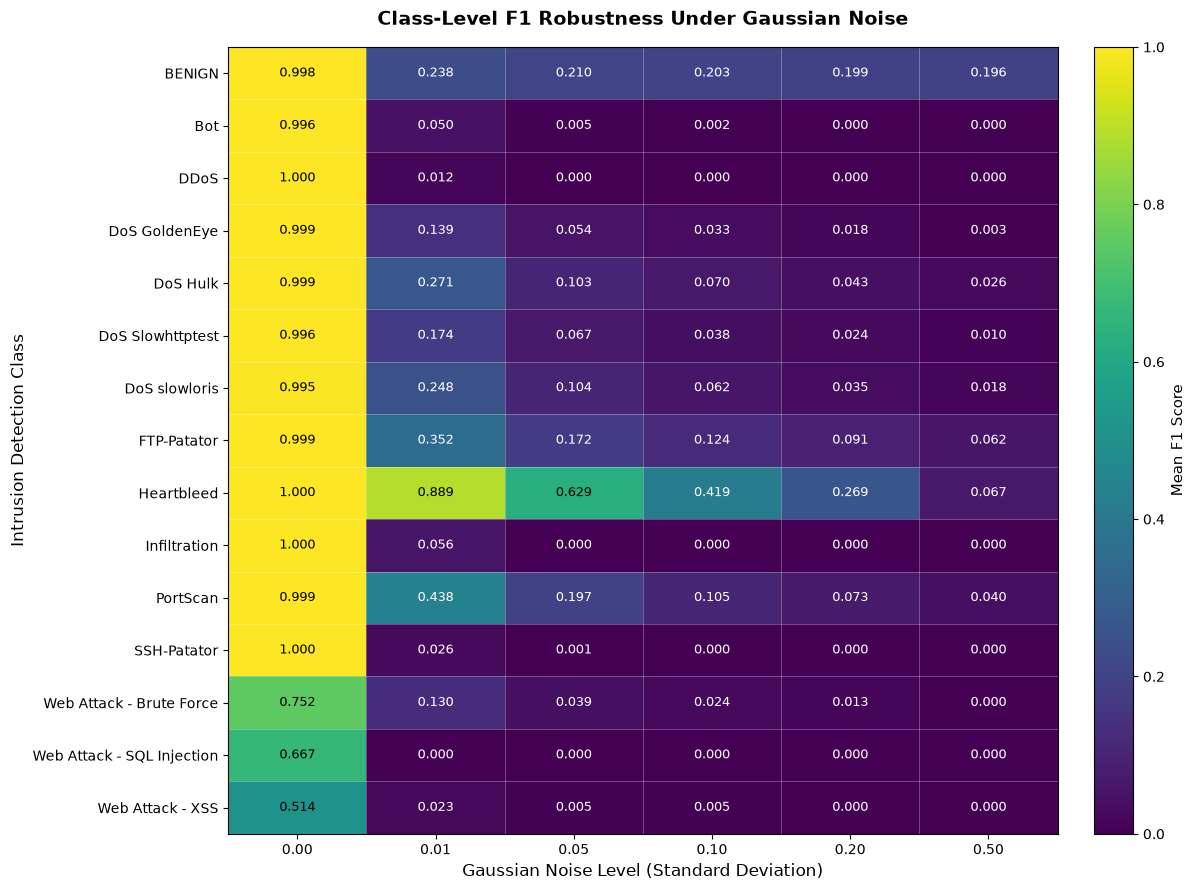

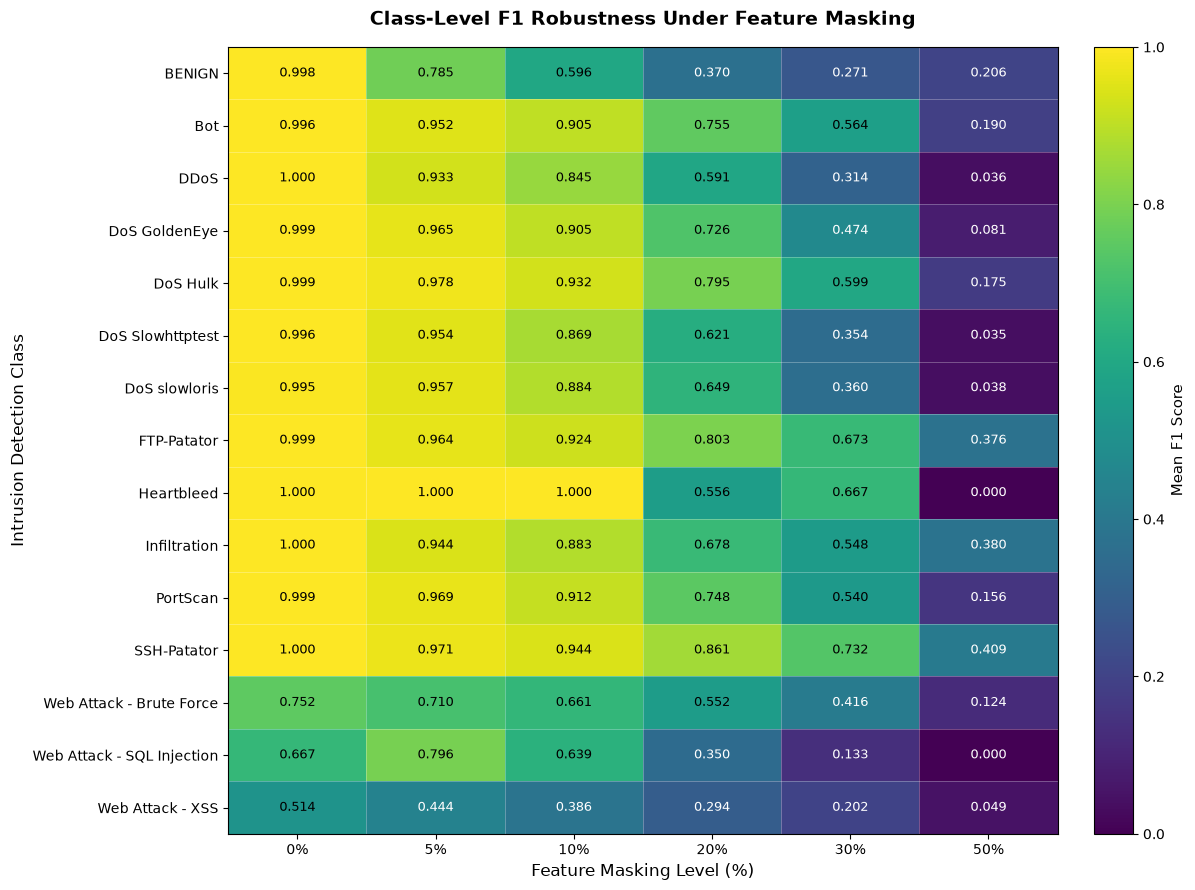

,Verification_Check,Status
0,Visualization preparation verified,PASS
1,Correct Gaussian matrix dimensions,PASS
2,Correct masking matrix dimensions,PASS
3,Consistent class ordering,PASS
4,Gaussian matrix unchanged,PASS
5,Masking matrix unchanged,PASS
6,Consistent baseline F1,PASS
7,Gaussian F1 heatmap saved,PASS
8,Masking F1 heatmap saved,PASS


-----------------------------------------------------------------
CLASS-LEVEL F1 HEATMAP SUMMARY
-----------------------------------------------------------------
Model: LGBMClassifier
Classes visualized: 15
Gaussian conditions: 6
Masking conditions: 6
Metric values visualized: 180
Figures generated: 2
Figure resolution: 300 DPI
Color scale: 0.0 to 1.0

Saved figures:
06_class_gaussian_f1_heatmap.png
06_class_masking_f1_heatmap.png

Total checks: 9
Passed checks: 9
Execution time: 8.27 seconds
-----------------------------------------------------------------
Class-level F1 heatmaps: PASS
F1 robustness visualization completed.


In [34]:
# Step 14B - Class-level F1 robustness heatmaps

from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

start_time = perf_counter()

assert visualization_preparation_passed

print("CLASS-LEVEL F1 ROBUSTNESS HEATMAPS")
print("-" * 65)

# Project configuration

project_root = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

figures_dir = project_root / "figures"

figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Preserve original visualization matrices

gaussian_f1_snapshot = (
    gaussian_f1_matrix.copy(deep=True)
)

masking_f1_snapshot = (
    masking_f1_matrix.copy(deep=True)
)

# Heatmap generation function

def generate_robustness_heatmap(
    matrix,
    title,
    xlabel,
    column_labels,
    colorbar_label,
    output_path
):

    values = matrix.to_numpy(
        dtype=np.float64
    )

    assert values.shape == (15, 6)
    assert np.isfinite(values).all()
    assert ((values >= 0) & (values <= 1)).all()

    assert len(column_labels) == values.shape[1]

    fig, ax = plt.subplots(
        figsize=(12, 9)
    )

    image = ax.imshow(
        values,
        cmap="viridis",
        vmin=0,
        vmax=1,
        aspect="auto",
        interpolation="nearest"
    )

    # Axis labels

    ax.set_xticks(
        np.arange(values.shape[1])
    )

    ax.set_xticklabels(
        column_labels,
        fontsize=10
    )

    ax.set_yticks(
        np.arange(values.shape[0])
    )

    ax.set_yticklabels(
        matrix.index.tolist(),
        fontsize=10
    )

    ax.set_xlabel(
        xlabel,
        fontsize=12
    )

    ax.set_ylabel(
        "Intrusion Detection Class",
        fontsize=12
    )

    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
        pad=16
    )

    # Annotate individual metric values

    for row in range(values.shape[0]):

        for col in range(values.shape[1]):

            value = values[row, col]

            text_color = (
                "white"
                if value < 0.50
                else "black"
            )

            ax.text(
                col,
                row,
                f"{value:.3f}",
                ha="center",
                va="center",
                color=text_color,
                fontsize=9
            )

    # Cell boundaries

    ax.set_xticks(
        np.arange(
            -0.5,
            values.shape[1],
            1
        ),
        minor=True
    )

    ax.set_yticks(
        np.arange(
            -0.5,
            values.shape[0],
            1
        ),
        minor=True
    )

    ax.grid(
        which="minor",
        color="white",
        linestyle="-",
        linewidth=0.5,
        alpha=0.4
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )

    # Consistent color scale

    colorbar = fig.colorbar(
        image,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

    colorbar.set_label(
        colorbar_label,
        fontsize=11
    )

    colorbar.set_ticks(
        np.linspace(0, 1, 6)
    )

    fig.tight_layout()

    # Save publication-quality figure

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

    return output_path


# Gaussian noise F1 heatmap

gaussian_f1_heatmap_path = (
    figures_dir /
    "06_class_gaussian_f1_heatmap.png"
)

gaussian_column_labels = [
    f"{level:.2f}"
    for level in gaussian_f1_matrix.columns
]

generate_robustness_heatmap(

    matrix=gaussian_f1_matrix,

    title=(
        "Class-Level F1 Robustness "
        "Under Gaussian Noise"
    ),

    xlabel="Gaussian Noise Level (Standard Deviation)",

    column_labels=gaussian_column_labels,

    colorbar_label="Mean F1 Score",

    output_path=gaussian_f1_heatmap_path
)

# Feature masking F1 heatmap

masking_f1_heatmap_path = (
    figures_dir /
    "06_class_masking_f1_heatmap.png"
)

masking_column_labels = [
    f"{level:.0%}"
    for level in masking_f1_matrix.columns
]

generate_robustness_heatmap(

    matrix=masking_f1_matrix,

    title=(
        "Class-Level F1 Robustness "
        "Under Feature Masking"
    ),

    xlabel="Feature Masking Level (%)",

    column_labels=masking_column_labels,

    colorbar_label="Mean F1 Score",

    output_path=masking_f1_heatmap_path
)

# Verification checks

f1_heatmap_checks = {

    "Visualization preparation verified":
        bool(visualization_preparation_passed),

    "Correct Gaussian matrix dimensions":
        gaussian_f1_matrix.shape == (15, 6),

    "Correct masking matrix dimensions":
        masking_f1_matrix.shape == (15, 6),

    "Consistent class ordering":
        gaussian_f1_matrix.index.tolist()
        == masking_f1_matrix.index.tolist(),

    "Gaussian matrix unchanged":
        gaussian_f1_matrix.equals(
            gaussian_f1_snapshot
        ),

    "Masking matrix unchanged":
        masking_f1_matrix.equals(
            masking_f1_snapshot
        ),

    "Consistent baseline F1":
        np.allclose(
            gaussian_f1_matrix[0.0],
            masking_f1_matrix[0.0],
            atol=1e-10,
            rtol=0
        ),

    "Gaussian F1 heatmap saved":
        gaussian_f1_heatmap_path.is_file()
        and gaussian_f1_heatmap_path.stat().st_size > 0,

    "Masking F1 heatmap saved":
        masking_f1_heatmap_path.is_file()
        and masking_f1_heatmap_path.stat().st_size > 0
}

display(pd.DataFrame([

    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }

    for name, passed in f1_heatmap_checks.items()

]))

f1_heatmaps_passed = all(
    f1_heatmap_checks.values()
)

print("-" * 65)
print("CLASS-LEVEL F1 HEATMAP SUMMARY")
print("-" * 65)

print("Model:", type(model).__name__)
print("Classes visualized:", 15)
print("Gaussian conditions:", 6)
print("Masking conditions:", 6)
print("Metric values visualized:", 180)
print("Figures generated:", 2)
print("Figure resolution: 300 DPI")
print("Color scale: 0.0 to 1.0")

print("\nSaved figures:")

print(
    gaussian_f1_heatmap_path.name
)

print(
    masking_f1_heatmap_path.name
)

print(
    "\nTotal checks:",
    len(f1_heatmap_checks)
)

print(
    "Passed checks:",
    sum(f1_heatmap_checks.values())
)

print(
    f"Execution time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

print("-" * 65)

assert f1_heatmaps_passed, (
    "Class-level F1 heatmap verification failed."
)

print("Class-level F1 heatmaps: PASS")
print("F1 robustness visualization completed.")

-----------------------------------------------------------------
06_class_gaussian_f1_heatmap.png
-----------------------------------------------------------------


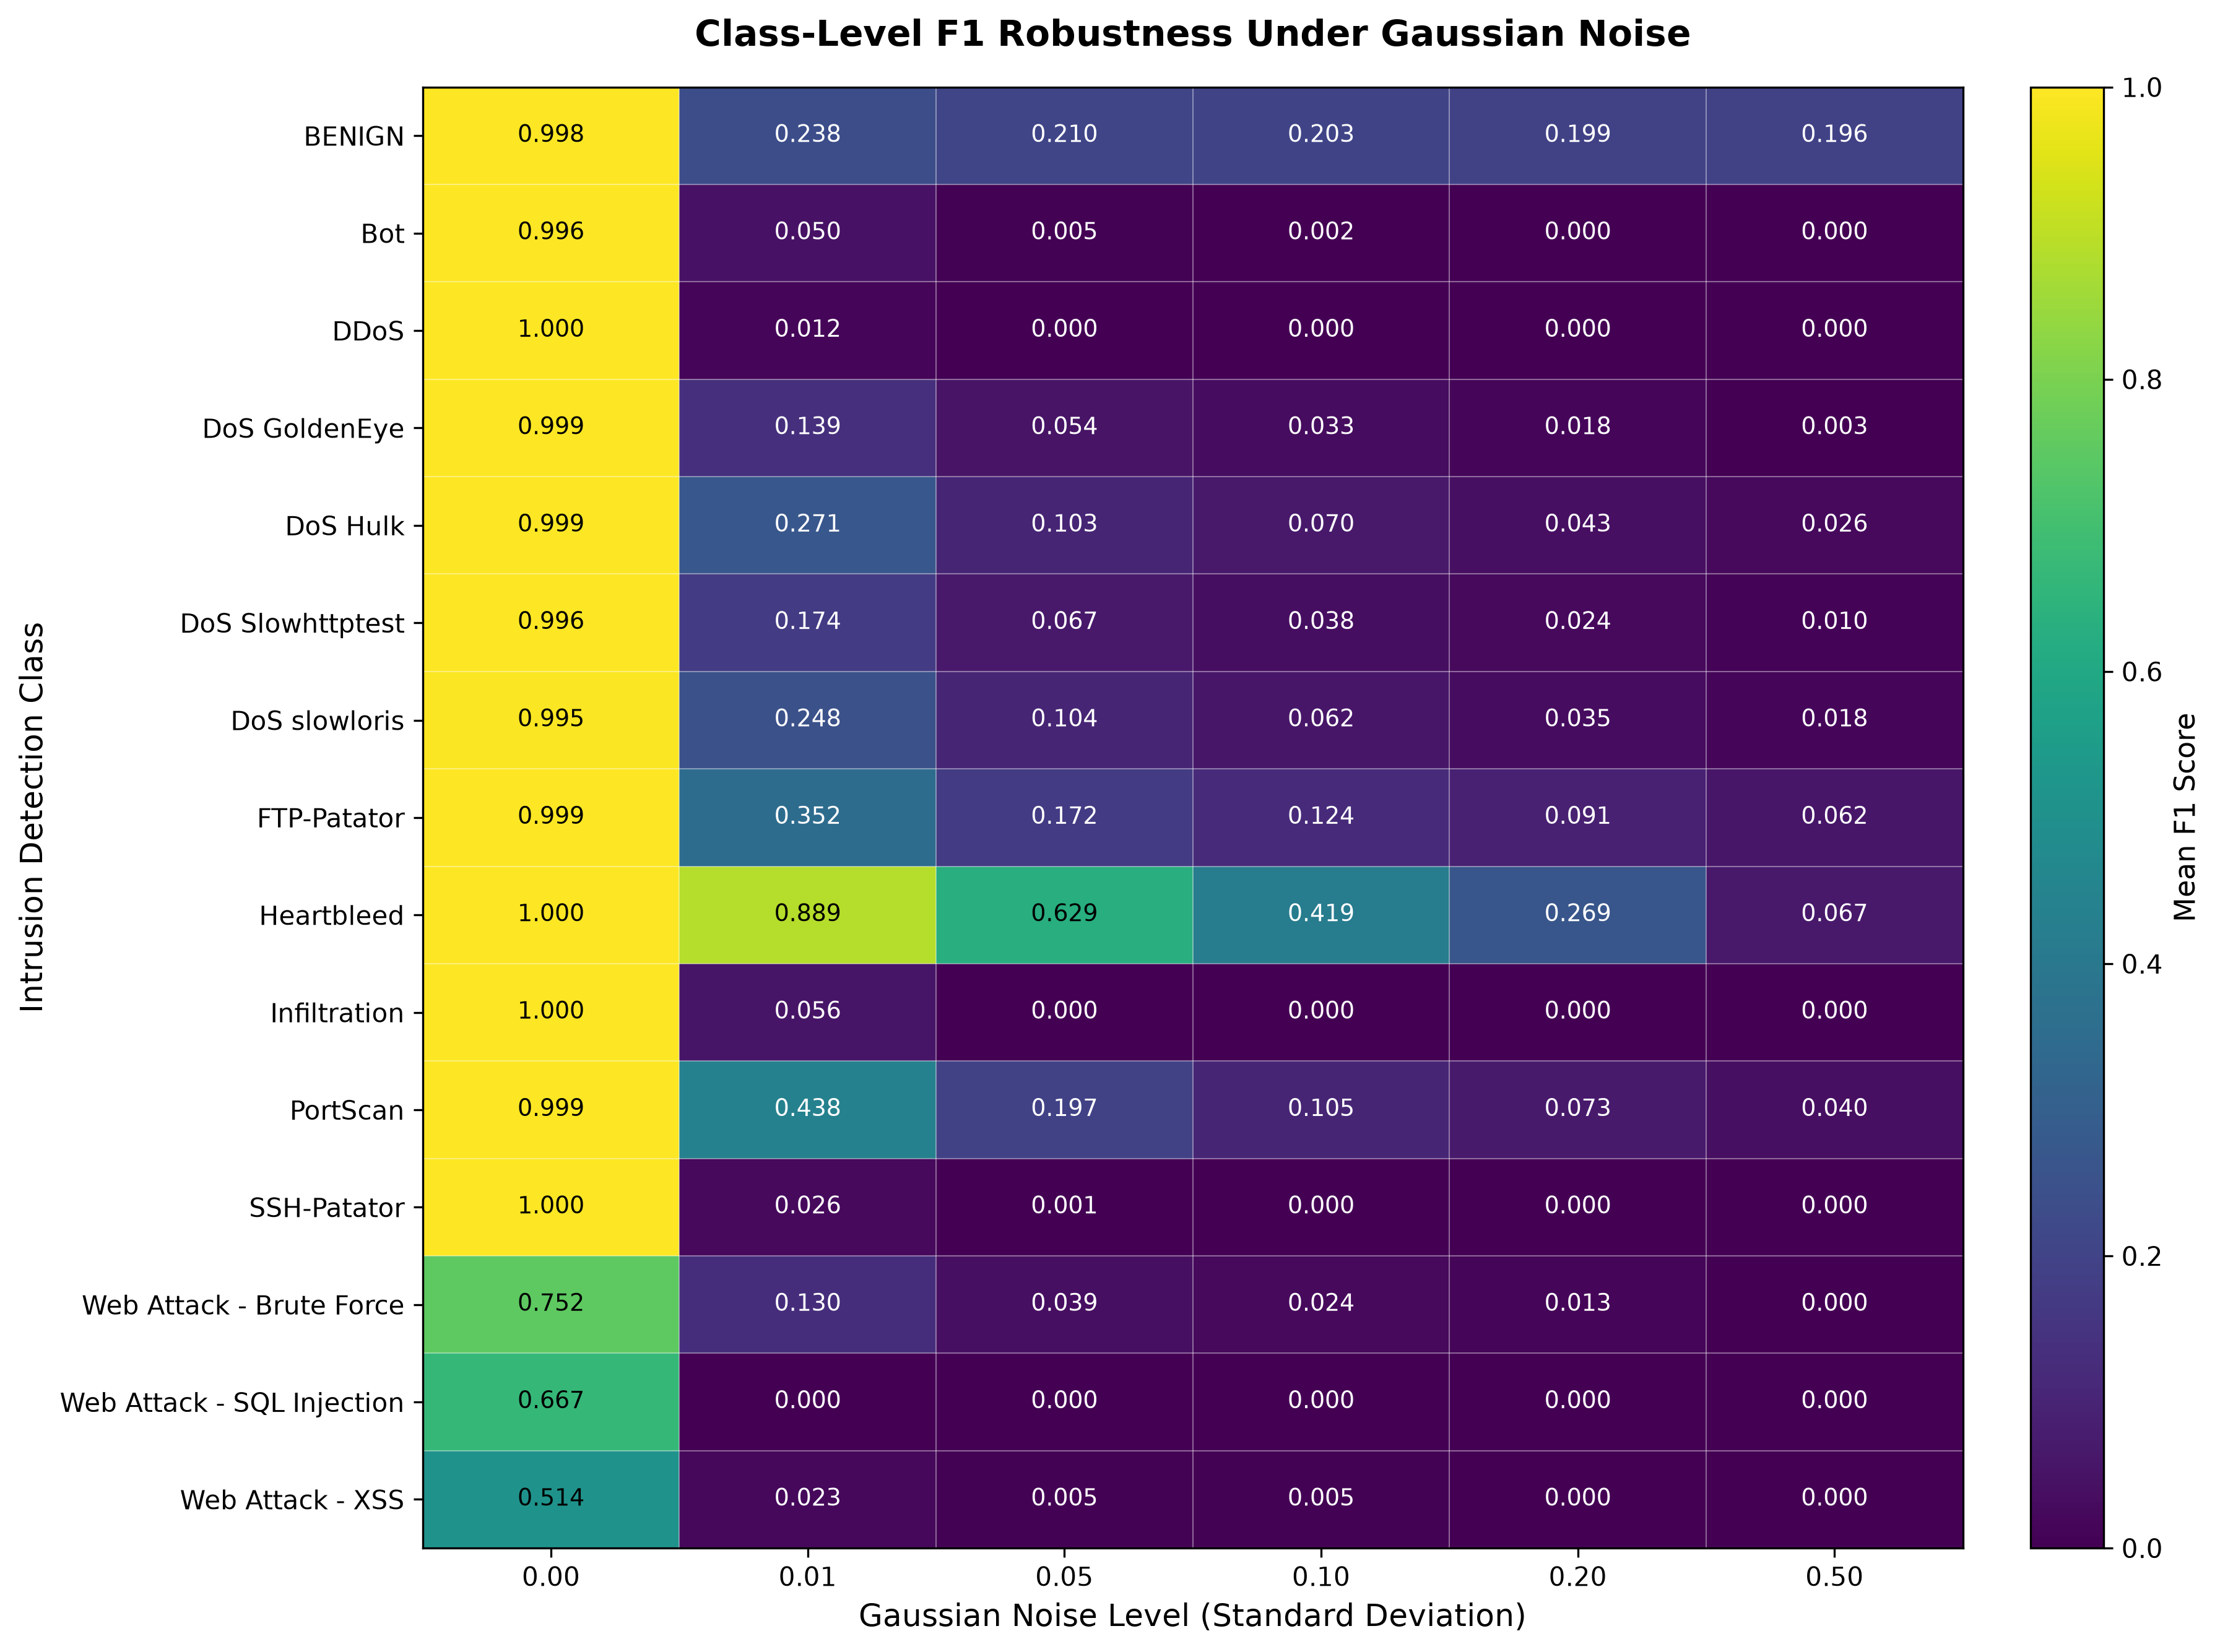

-----------------------------------------------------------------
06_class_masking_f1_heatmap.png
-----------------------------------------------------------------


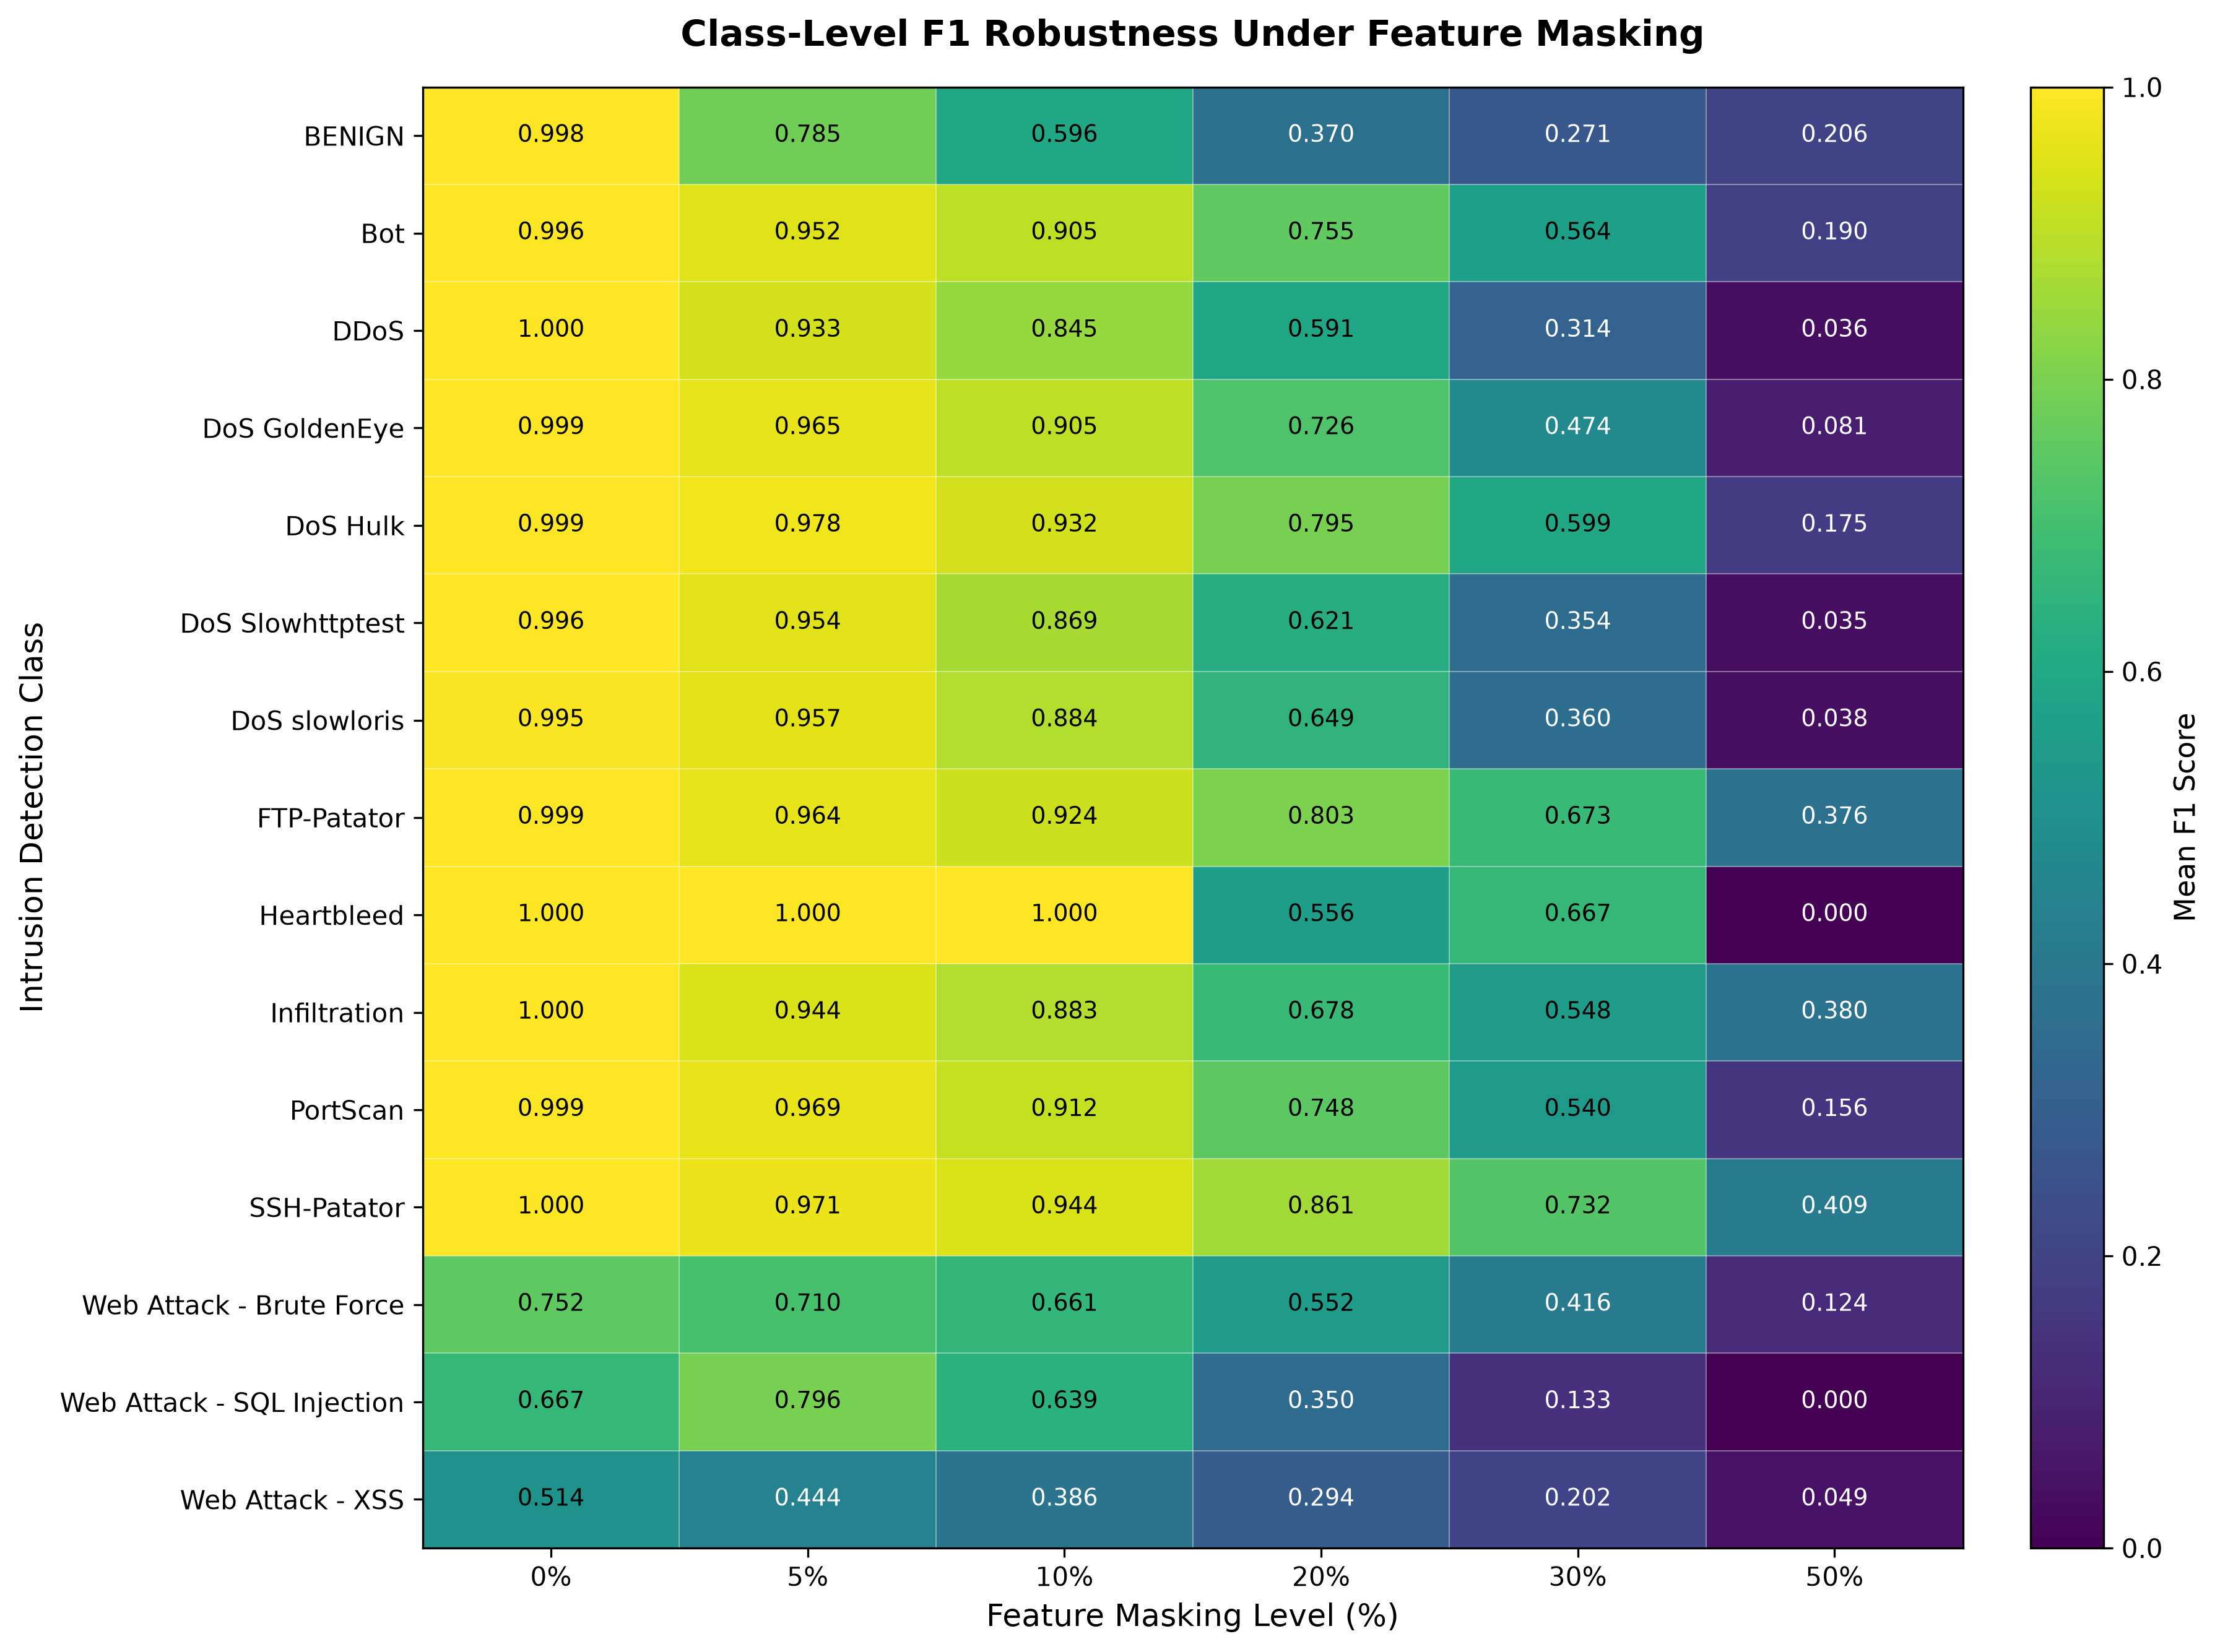

Saved F1 heatmap review completed.


In [35]:
# Review saved F1 robustness heatmaps

from pathlib import Path
from IPython.display import Image, display

review_figures_dir = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection\figures"
)

heatmap_files = [
    "06_class_gaussian_f1_heatmap.png",
    "06_class_masking_f1_heatmap.png"
]

for filename in heatmap_files:

    image_path = review_figures_dir / filename

    assert image_path.is_file(), (
        f"Missing figure: {filename}"
    )

    print("-" * 65)
    print(filename)
    print("-" * 65)

    display(
        Image(
            filename=str(image_path),
            width=950
        )
    )

print("Saved F1 heatmap review completed.")

CLASS-LEVEL RECALL ROBUSTNESS HEATMAPS
-----------------------------------------------------------------


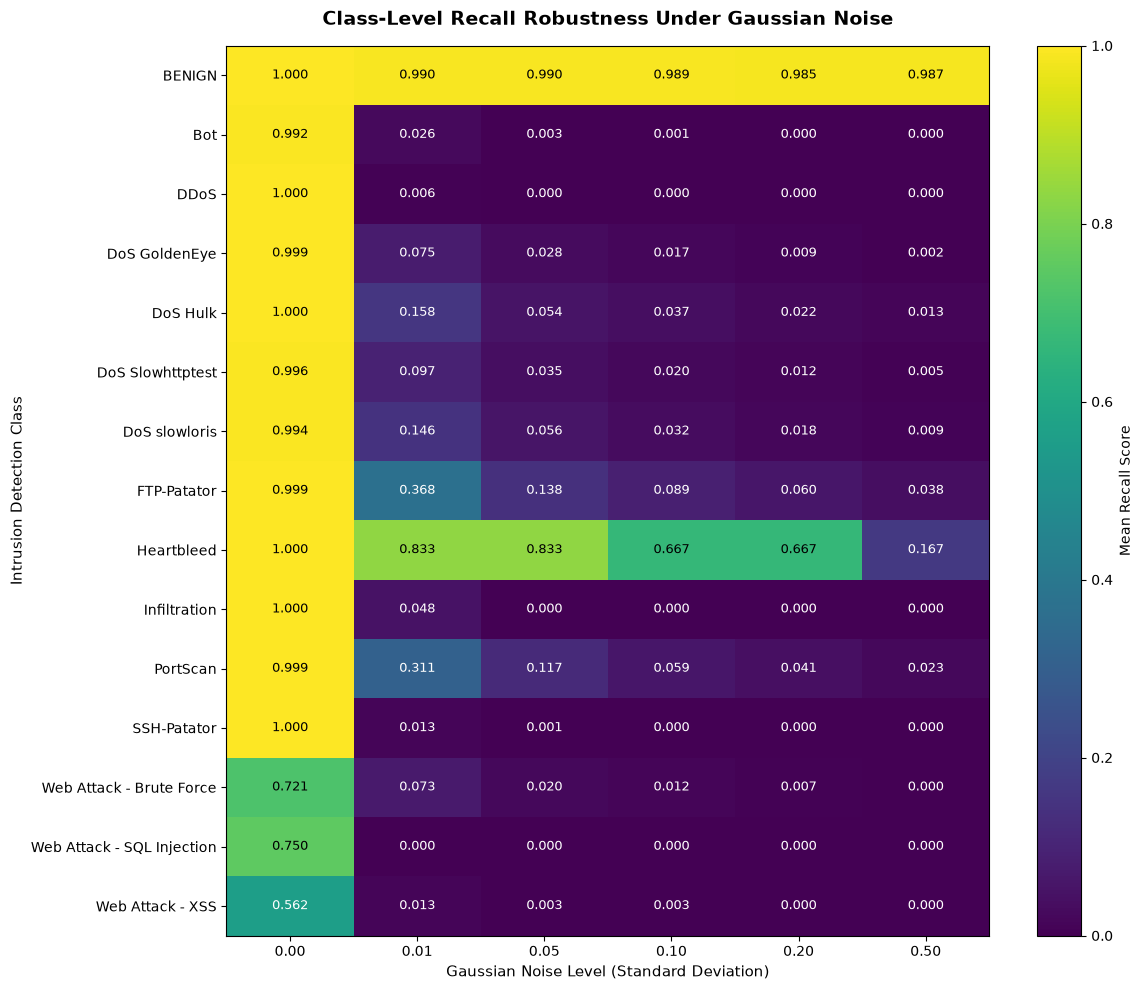

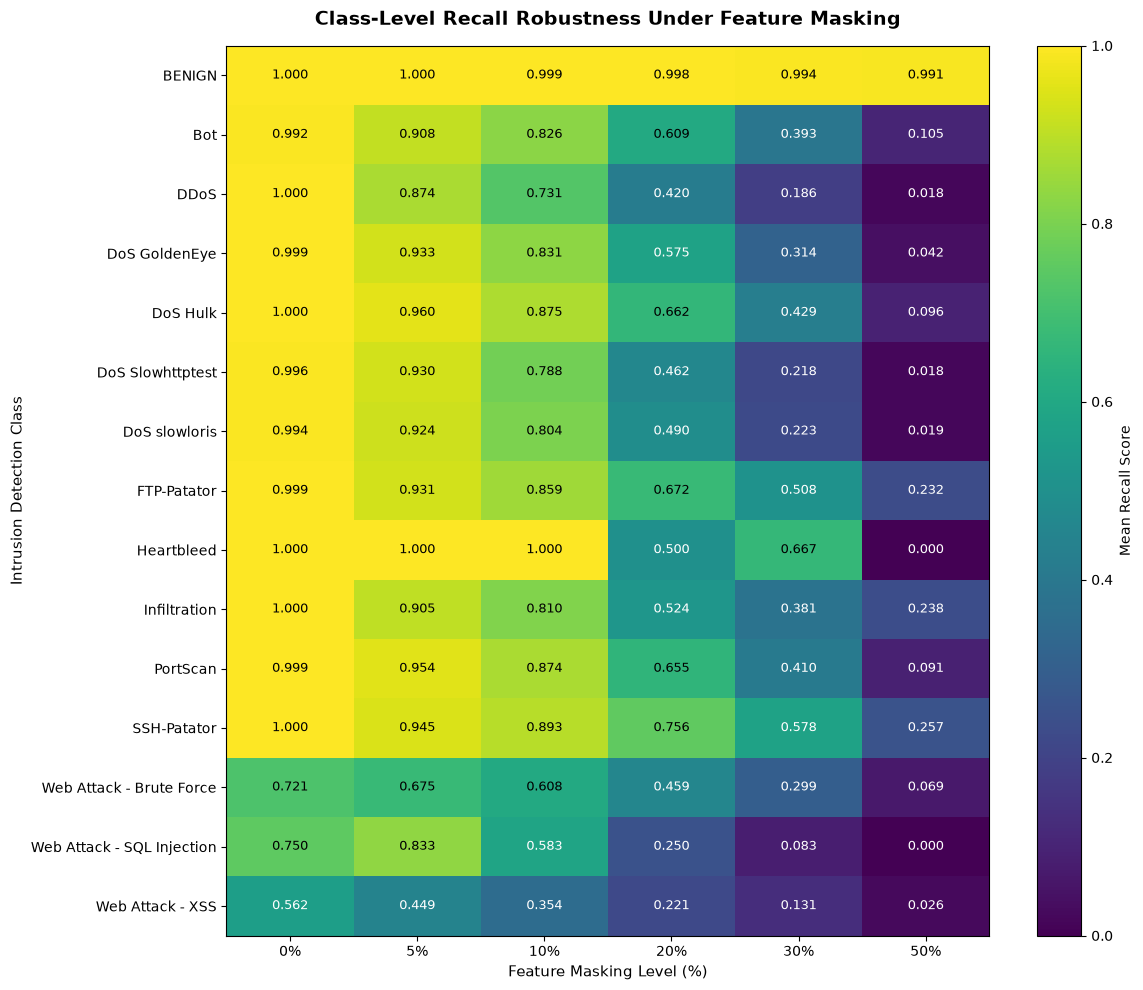

,Verification_Check,Status
0,Correct Gaussian matrix dimensions,PASS
1,Correct masking matrix dimensions,PASS
2,Consistent class ordering,PASS
3,Gaussian matrix unchanged,PASS
4,Masking matrix unchanged,PASS
5,Finite recall values,PASS
6,Valid recall ranges,PASS
7,Consistent baseline recall,PASS
8,Gaussian recall heatmap saved,PASS
9,Masking recall heatmap saved,PASS


-----------------------------------------------------------------
CLASS-LEVEL RECALL VISUALIZATION SUMMARY
-----------------------------------------------------------------
Model: LGBMClassifier
Classes visualized: 15
Gaussian conditions: 6
Masking conditions: 6
Metric values visualized: 180
Figures generated: 2
Figure resolution: 300 DPI
Color scale: 0.0 to 1.0

Saved figures:
06_class_gaussian_recall_heatmap.png
06_class_masking_recall_heatmap.png

Total checks: 10
Passed checks: 10
Execution time: 7.96 seconds
-----------------------------------------------------------------
Class-level recall heatmaps: PASS
Recall robustness visualization completed.


In [36]:
# Step 14C - Class-level recall robustness heatmaps

from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

start_time = perf_counter()

print("CLASS-LEVEL RECALL ROBUSTNESS HEATMAPS")
print("-" * 65)

# Configuration

project_root = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

figures_dir = project_root / "figures"

figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Verify required datasets

assert class_gaussian_summary_df.shape == (90, 10)
assert class_masking_summary_df.shape == (90, 10)

# Establish consistent class ordering

recall_class_order = (
    class_gaussian_summary_df[
        ["Class_ID", "Class_Name"]
    ]
    .drop_duplicates()
    .sort_values("Class_ID")
    ["Class_Name"]
    .tolist()
)

assert len(recall_class_order) == 15

# Prepare Gaussian recall matrix

gaussian_recall_matrix = (
    class_gaussian_summary_df
    .pivot(
        index="Class_Name",
        columns="Noise_Level",
        values="Mean_Recall"
    )
    .reindex(recall_class_order)
    .sort_index(axis=1)
)

# Prepare feature masking recall matrix

masking_recall_matrix = (
    class_masking_summary_df
    .pivot(
        index="Class_Name",
        columns="Masking_Level",
        values="Mean_Recall"
    )
    .reindex(recall_class_order)
    .sort_index(axis=1)
)

# Validate matrices

assert gaussian_recall_matrix.shape == (15, 6)
assert masking_recall_matrix.shape == (15, 6)

assert gaussian_recall_matrix.notna().all().all()
assert masking_recall_matrix.notna().all().all()

# Preserve original matrices

gaussian_recall_snapshot = (
    gaussian_recall_matrix.copy(deep=True)
)

masking_recall_snapshot = (
    masking_recall_matrix.copy(deep=True)
)

# Heatmap generation function

def generate_recall_heatmap(
    matrix,
    title,
    xlabel,
    tick_labels,
    filename
):

    values = matrix.to_numpy()

    fig, ax = plt.subplots(
        figsize=(12, 10)
    )

    heatmap = ax.imshow(
        values,
        cmap="viridis",
        vmin=0,
        vmax=1,
        aspect="auto"
    )

    ax.set_xticks(
        np.arange(matrix.shape[1])
    )

    ax.set_xticklabels(tick_labels)

    ax.set_yticks(
        np.arange(matrix.shape[0])
    )

    ax.set_yticklabels(matrix.index)

    # Numerical annotations

    for row in range(matrix.shape[0]):

        for col in range(matrix.shape[1]):

            value = values[row, col]

            text_color = (
                "black"
                if value >= 0.60
                else "white"
            )

            ax.text(
                col,
                row,
                f"{value:.3f}",
                ha="center",
                va="center",
                color=text_color,
                fontsize=9
            )

    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel(
        xlabel,
        fontsize=11
    )

    ax.set_ylabel(
        "Intrusion Detection Class",
        fontsize=11
    )

    colorbar = fig.colorbar(
        heatmap,
        ax=ax
    )

    colorbar.set_label(
        "Mean Recall Score"
    )

    fig.tight_layout()

    figure_path = figures_dir / filename

    fig.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    return figure_path


# Generate Gaussian recall heatmap

gaussian_recall_figure_path = (
    generate_recall_heatmap(
        gaussian_recall_matrix,

        "Class-Level Recall Robustness "
        "Under Gaussian Noise",

        "Gaussian Noise Level "
        "(Standard Deviation)",

        [
            f"{level:.2f}"
            for level in
            gaussian_recall_matrix.columns
        ],

        "06_class_gaussian_recall_heatmap.png"
    )
)

# Generate feature masking recall heatmap

masking_recall_figure_path = (
    generate_recall_heatmap(
        masking_recall_matrix,

        "Class-Level Recall Robustness "
        "Under Feature Masking",

        "Feature Masking Level (%)",

        [
            f"{level:.0%}"
            for level in
            masking_recall_matrix.columns
        ],

        "06_class_masking_recall_heatmap.png"
    )
)

# Verification checks

recall_heatmap_checks = {

    "Correct Gaussian matrix dimensions":
        gaussian_recall_matrix.shape == (15, 6),

    "Correct masking matrix dimensions":
        masking_recall_matrix.shape == (15, 6),

    "Consistent class ordering":
        gaussian_recall_matrix.index.equals(
            masking_recall_matrix.index
        ),

    "Gaussian matrix unchanged":
        gaussian_recall_matrix.equals(
            gaussian_recall_snapshot
        ),

    "Masking matrix unchanged":
        masking_recall_matrix.equals(
            masking_recall_snapshot
        ),

    "Finite recall values":
        bool(
            np.isfinite(
                gaussian_recall_matrix.to_numpy()
            ).all()
            and
            np.isfinite(
                masking_recall_matrix.to_numpy()
            ).all()
        ),

    "Valid recall ranges":
        bool(
            (
                (gaussian_recall_matrix >= 0)
                &
                (gaussian_recall_matrix <= 1)
            ).all().all()
            and
            (
                (masking_recall_matrix >= 0)
                &
                (masking_recall_matrix <= 1)
            ).all().all()
        ),

    "Consistent baseline recall":
        np.allclose(
            gaussian_recall_matrix[0.0],
            masking_recall_matrix[0.0],
            atol=1e-10,
            rtol=0
        ),

    "Gaussian recall heatmap saved":
        gaussian_recall_figure_path.is_file()
        and
        gaussian_recall_figure_path.stat().st_size > 0,

    "Masking recall heatmap saved":
        masking_recall_figure_path.is_file()
        and
        masking_recall_figure_path.stat().st_size > 0
}

display(pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }
    for name, passed in
    recall_heatmap_checks.items()
]))

recall_heatmaps_passed = all(
    recall_heatmap_checks.values()
)

print("-" * 65)
print("CLASS-LEVEL RECALL VISUALIZATION SUMMARY")
print("-" * 65)

print("Model:", type(model).__name__)
print("Classes visualized:", len(recall_class_order))
print("Gaussian conditions:", 6)
print("Masking conditions:", 6)
print("Metric values visualized:", 180)
print("Figures generated:", 2)
print("Figure resolution: 300 DPI")
print("Color scale: 0.0 to 1.0")

print("\nSaved figures:")

print(gaussian_recall_figure_path.name)
print(masking_recall_figure_path.name)

print("\nTotal checks:", len(recall_heatmap_checks))

print(
    "Passed checks:",
    sum(recall_heatmap_checks.values())
)

print(
    f"Execution time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

print("-" * 65)

assert recall_heatmaps_passed, (
    "Recall heatmap verification failed."
)

print("Class-level recall heatmaps: PASS")
print("Recall robustness visualization completed.")

SAVED RECALL HEATMAP VERIFICATION
-----------------------------------------------------------------

File: 06_class_gaussian_recall_heatmap.png
Format: PNG
Dimensions: (3428, 2970)
DPI: (299.9994, 299.9994)
File size: 387095
Status: PASS


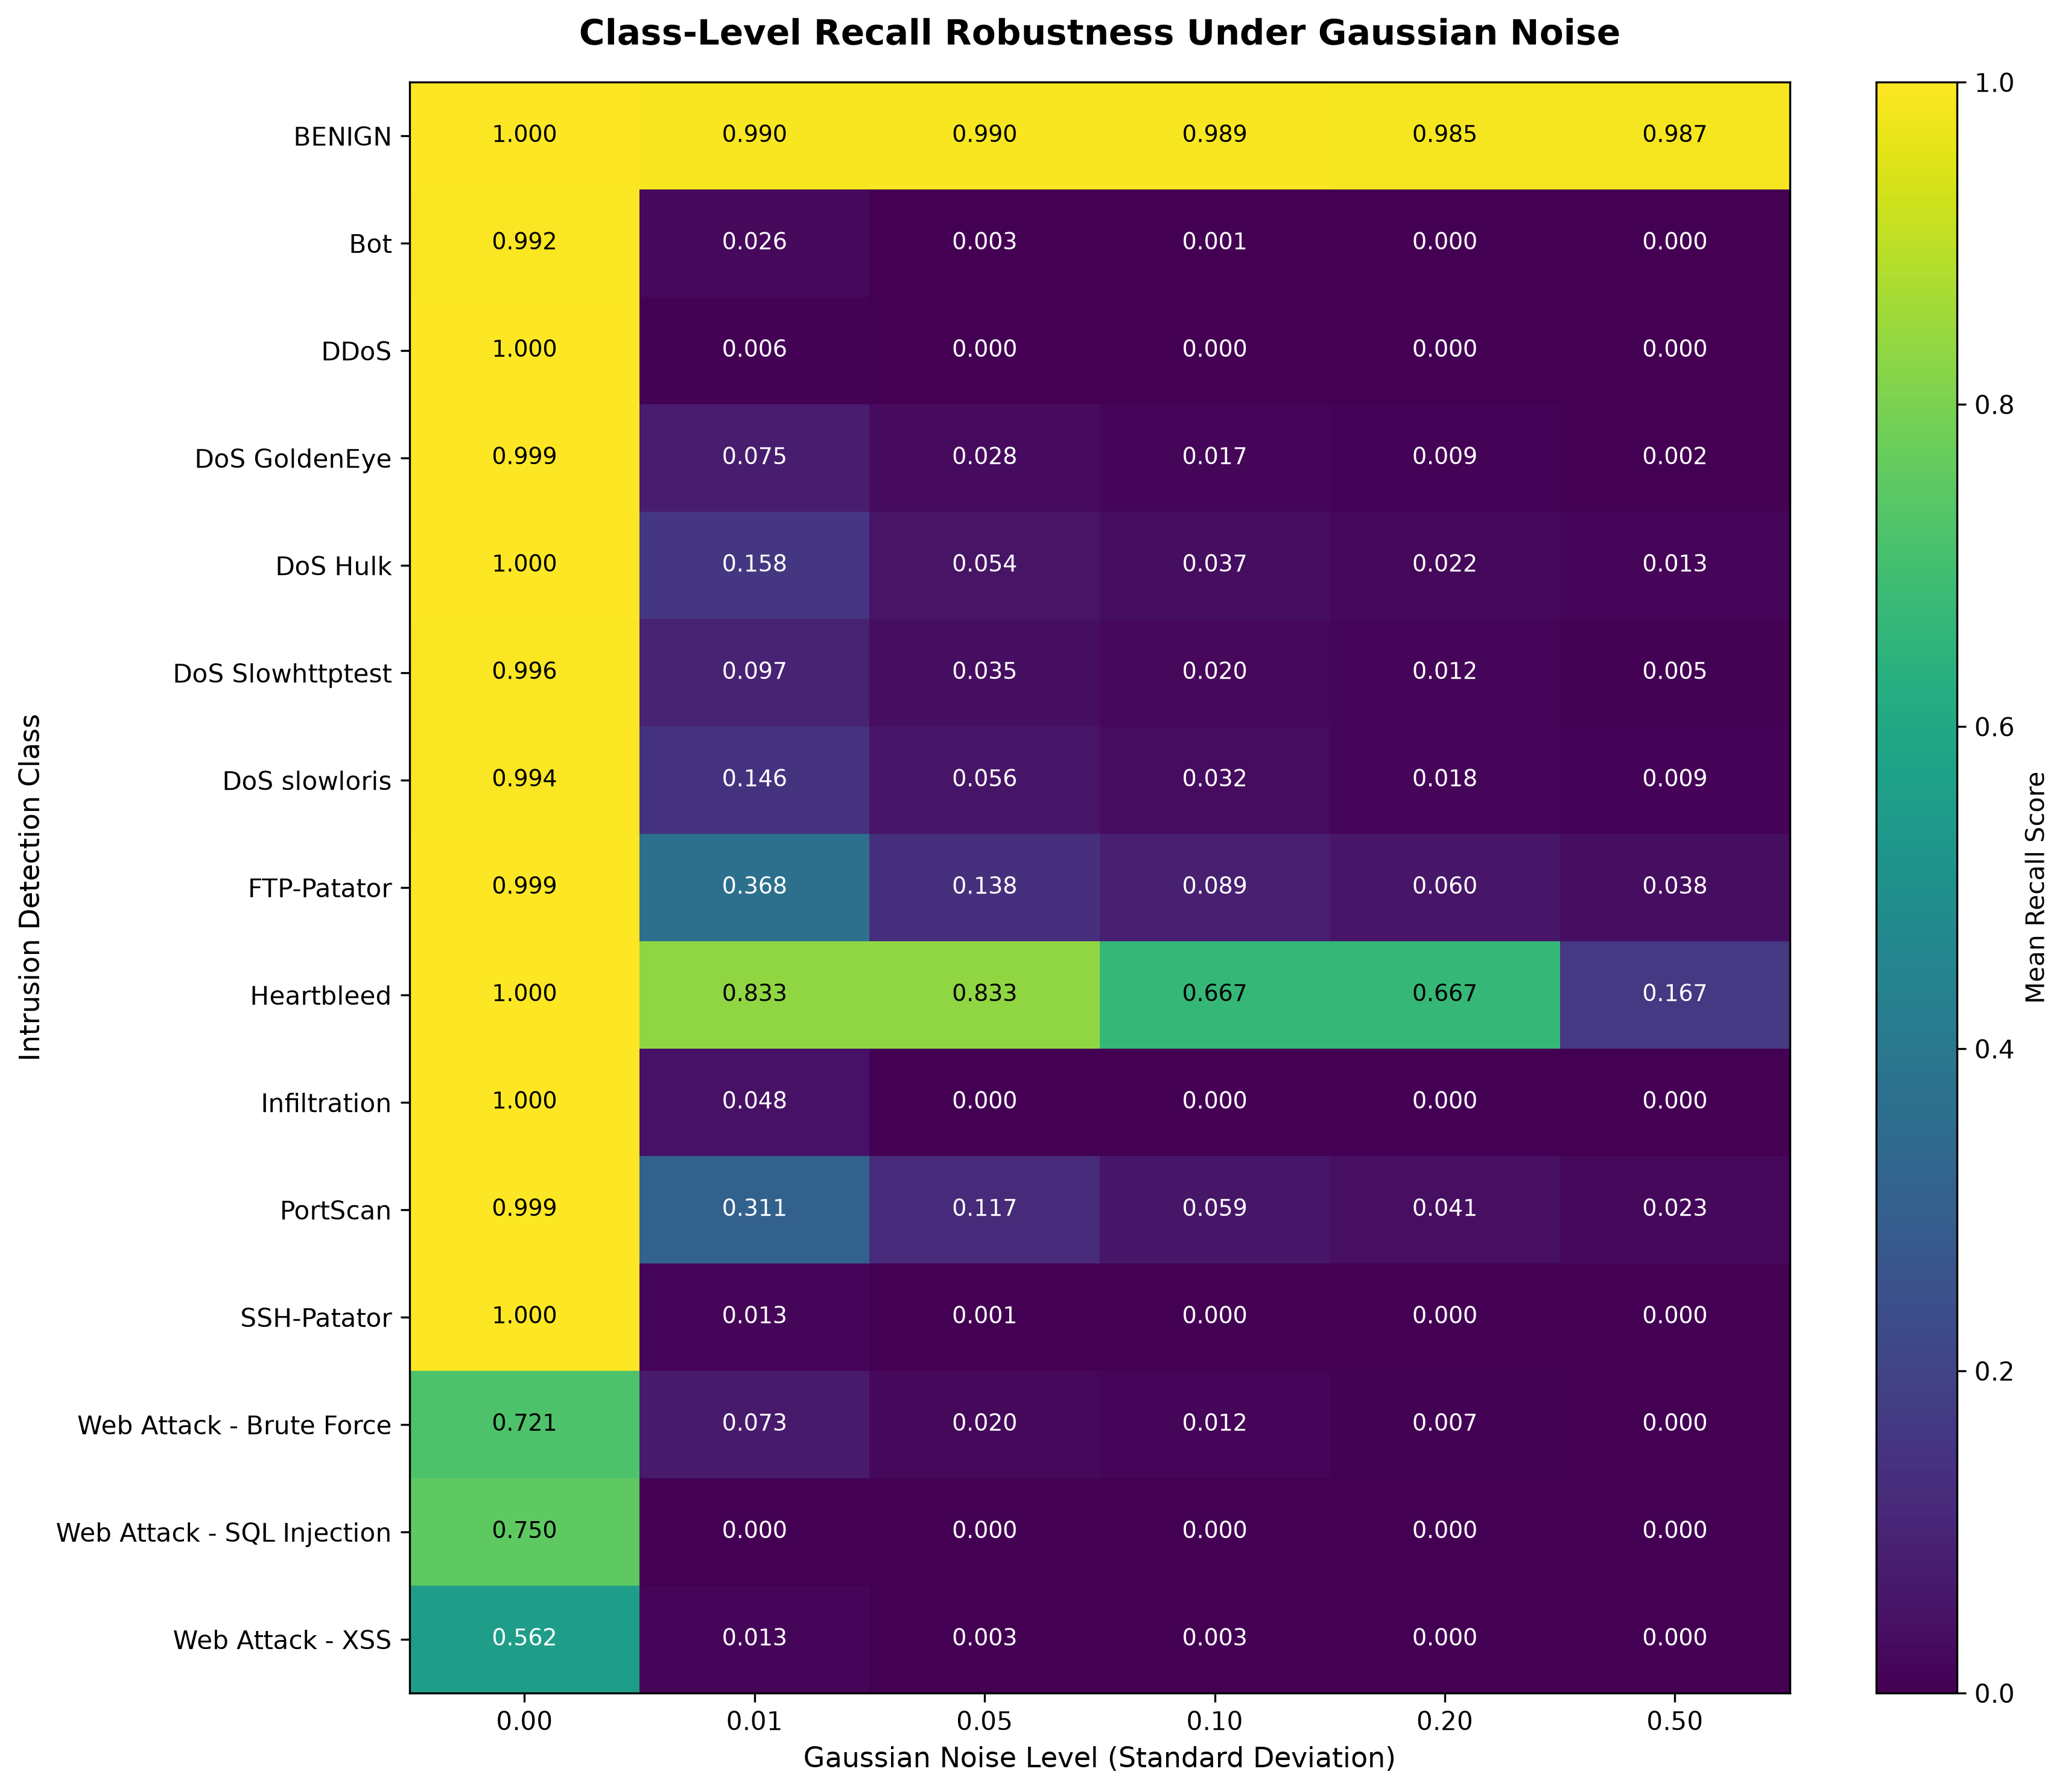


File: 06_class_masking_recall_heatmap.png
Format: PNG
Dimensions: (3428, 2970)
DPI: (299.9994, 299.9994)
File size: 449822
Status: PASS


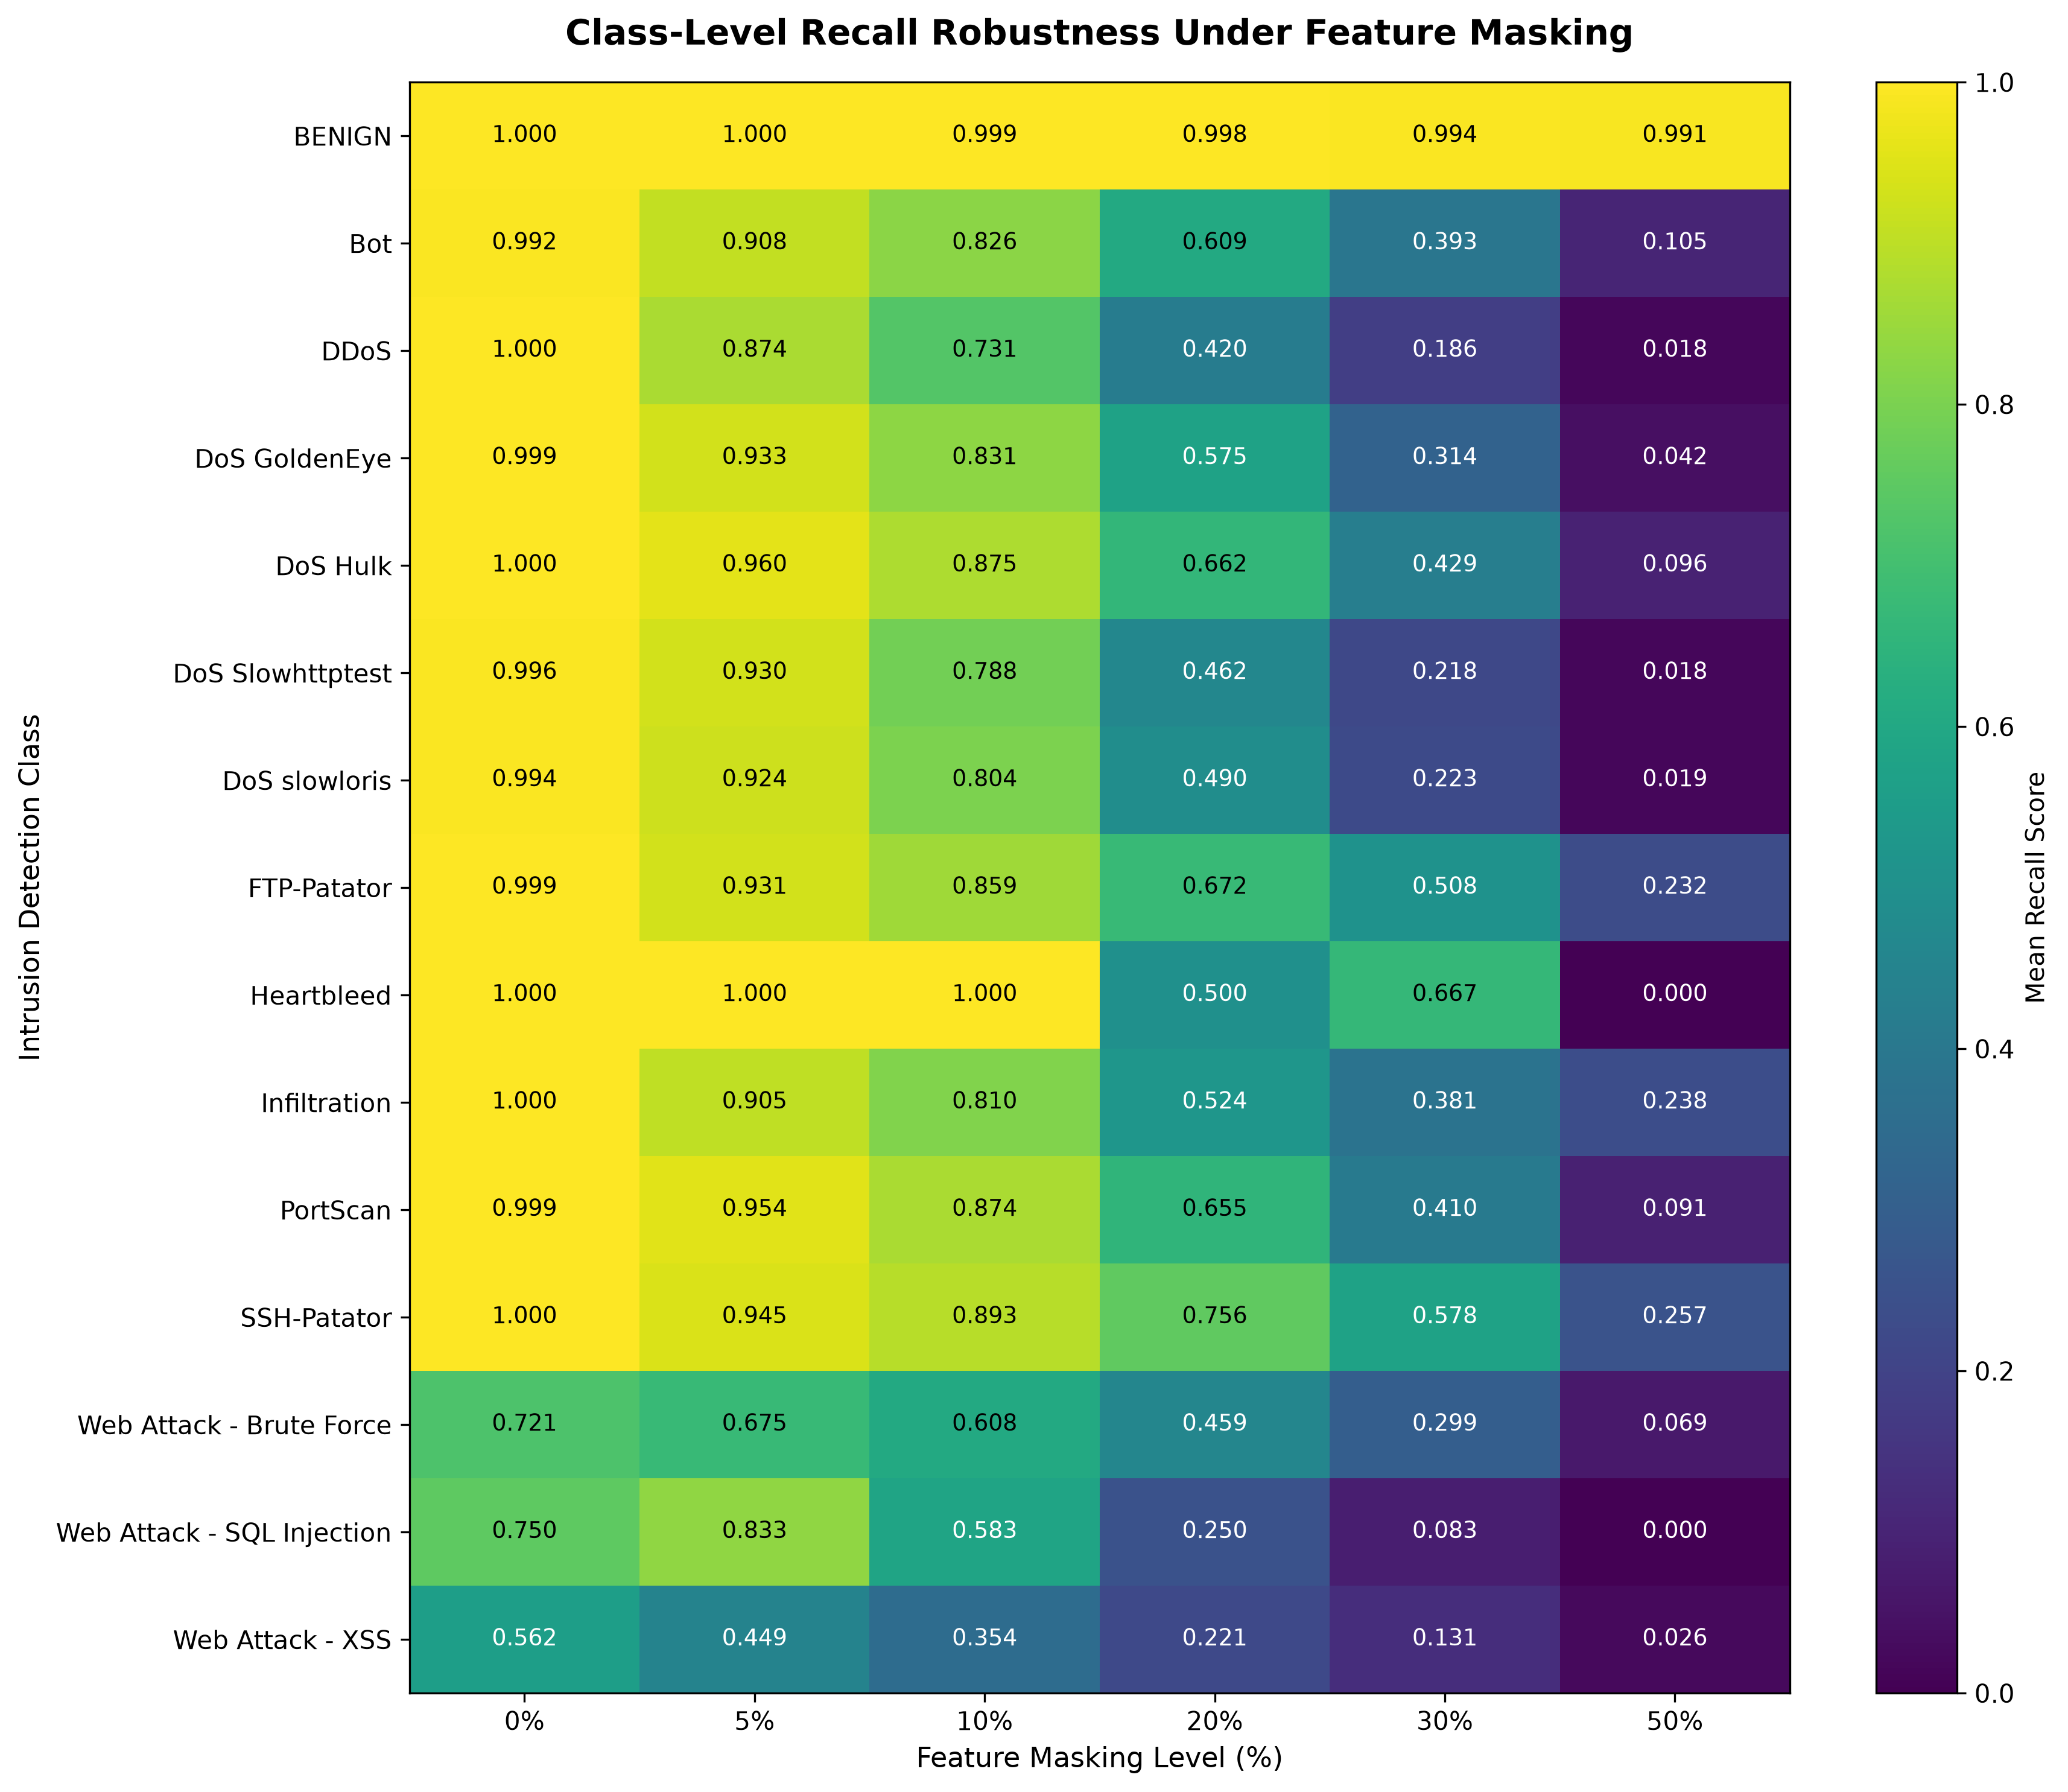

-----------------------------------------------------------------
Figures verified: 2
Passed checks: 2
Saved recall heatmap verification: PASS
Saved recall heatmap review completed.


In [37]:
# Step 14D - Saved recall heatmap verification

from PIL import Image
from IPython.display import display

assert recall_heatmaps_passed

print("SAVED RECALL HEATMAP VERIFICATION")
print("-" * 65)

recall_figure_paths = [
    gaussian_recall_figure_path,
    masking_recall_figure_path
]

saved_recall_checks = []

for figure_path in recall_figure_paths:

    assert figure_path.is_file()
    assert figure_path.stat().st_size > 0

    with Image.open(figure_path) as image:
        image.verify()

    with Image.open(figure_path) as image:

        width, height = image.size
        dpi = image.info.get("dpi", (0, 0))

        valid_format = image.format == "PNG"

        valid_dimensions = (
            width > 0 and height > 0
        )

        valid_dpi = all(
            abs(value - 300) < 1
            for value in dpi
        )

        passed = (
            valid_format
            and valid_dimensions
            and valid_dpi
        )

        saved_recall_checks.append(passed)

        print("\nFile:", figure_path.name)
        print("Format:", image.format)
        print("Dimensions:", image.size)
        print("DPI:", dpi)
        print("File size:", figure_path.stat().st_size)
        print("Status:", "PASS" if passed else "FAIL")

        display(image.copy())

saved_recall_heatmaps_passed = all(
    saved_recall_checks
)

assert saved_recall_heatmaps_passed

print("-" * 65)
print("Figures verified:", len(recall_figure_paths))
print("Passed checks:", sum(saved_recall_checks))
print("Saved recall heatmap verification: PASS")
print("Saved recall heatmap review completed.")

In [38]:
# Step 15A.1 - Identify class-level robustness data

import pandas as pd

assert recall_heatmaps_passed
assert saved_recall_heatmaps_passed

print("CLASS-LEVEL ROBUSTNESS DATA INVENTORY")
print("-" * 65)

for variable_name, variable_value in list(globals().items()):

    if isinstance(variable_value, pd.DataFrame):

        if any(
            keyword in variable_name.lower()
            for keyword in [
                "class",
                "gaussian",
                "masking",
                "recall",
                "f1",
                "baseline"
            ]
        ):

            print(f"\nVariable: {variable_name}")
            print(f"Shape: {variable_value.shape}")
            print(f"Columns: {variable_value.columns.tolist()}")

print("-" * 65)
print("Data inventory completed.")

CLASS-LEVEL ROBUSTNESS DATA INVENTORY
-----------------------------------------------------------------

Variable: baseline_metrics_df
Shape: (7, 2)
Columns: ['Metric', 'Value']

Variable: baseline_verification_df
Shape: (6, 2)
Columns: ['Verification_Check', 'Status']

Variable: class_reliability_df
Shape: (15, 8)
Columns: ['Class', 'Precision', 'Recall', 'F1_Score', 'Support', 'Correct_Predictions', 'Incorrect_Predictions', 'Error_Rate']

Variable: gaussian_noise_df
Shape: (16, 8)
Columns: ['Noise_Level', 'Random_Seed', 'Accuracy', 'Macro_F1', 'Prediction_Agreement', 'Accuracy_Drop', 'Macro_F1_Drop', 'Changed_Predictions']

Variable: gaussian_noise_summary
Shape: (6, 9)
Columns: ['Noise_Level', 'Runs', 'Mean_Accuracy', 'Std_Accuracy', 'Mean_Macro_F1', 'Std_Macro_F1', 'Mean_Prediction_Agreement', 'Mean_Accuracy_Drop', 'Mean_Macro_F1_Drop']

Variable: gaussian_diagnostic_df
Shape: (6, 6)
Columns: ['Noise_Level', 'Predicted_Classes', 'Dominant_Class', 'Dominant_Class_Share', 'Prediction

In [39]:
# Step 15A.2 - Class-Level Vulnerability Ranking

import time
import numpy as np
import pandas as pd
from IPython.display import display

start_time = time.perf_counter()

assert recall_heatmaps_passed
assert saved_recall_heatmaps_passed

print("CLASS-LEVEL VULNERABILITY RANKING")
print("-" * 65)

# Preserve original matrices
vulnerability_source_snapshots = {
    "Gaussian_F1": gaussian_f1_snapshot.copy(deep=True),
    "Gaussian_Recall": gaussian_recall_snapshot.copy(deep=True),
    "Masking_F1": masking_f1_snapshot.copy(deep=True),
    "Masking_Recall": masking_recall_snapshot.copy(deep=True)
}


# Function for class-level vulnerability analysis
def calculate_class_vulnerability(
    f1_matrix,
    recall_matrix,
    perturbation_type
):

    assert f1_matrix.shape == (15, 6)
    assert recall_matrix.shape == (15, 6)

    assert f1_matrix.index.is_unique
    assert f1_matrix.index.equals(recall_matrix.index)
    assert f1_matrix.columns.equals(recall_matrix.columns)

    assert 0.0 in f1_matrix.columns

    perturbation_levels = [
        level for level in f1_matrix.columns
        if level != 0.0
    ]

    assert len(perturbation_levels) == 5

    baseline_f1 = f1_matrix[0.0]
    baseline_recall = recall_matrix[0.0]

    perturbed_f1 = f1_matrix[perturbation_levels]
    perturbed_recall = recall_matrix[perturbation_levels]

    mean_f1 = perturbed_f1.mean(axis=1)
    mean_recall = perturbed_recall.mean(axis=1)

    worst_f1 = perturbed_f1.min(axis=1)
    worst_recall = perturbed_recall.min(axis=1)

    results = pd.DataFrame({
        "Class_Name": f1_matrix.index,
        "Perturbation_Type": perturbation_type,

        "Baseline_F1": baseline_f1.to_numpy(),
        "Mean_Perturbed_F1": mean_f1.to_numpy(),
        "Worst_Case_F1": worst_f1.to_numpy(),

        "Mean_F1_Drop_PP": (
            (baseline_f1 - mean_f1) * 100
        ).to_numpy(),

        "Worst_F1_Drop_PP": (
            (baseline_f1 - worst_f1) * 100
        ).to_numpy(),

        "Relative_F1_Drop_Pct": (
            (baseline_f1 - mean_f1)
            / baseline_f1.replace(0, np.nan) * 100
        ).to_numpy(),

        "Baseline_Recall": baseline_recall.to_numpy(),
        "Mean_Perturbed_Recall": mean_recall.to_numpy(),
        "Worst_Case_Recall": worst_recall.to_numpy(),

        "Mean_Recall_Drop_PP": (
            (baseline_recall - mean_recall) * 100
        ).to_numpy(),

        "Worst_Recall_Drop_PP": (
            (baseline_recall - worst_recall) * 100
        ).to_numpy(),

        "Relative_Recall_Drop_Pct": (
            (baseline_recall - mean_recall)
            / baseline_recall.replace(0, np.nan) * 100
        ).to_numpy()
    })

    results["F1_Vulnerability_Rank"] = (
        results["Mean_F1_Drop_PP"]
        .rank(method="min", ascending=False)
        .astype(int)
    )

    results["Recall_Vulnerability_Rank"] = (
        results["Mean_Recall_Drop_PP"]
        .rank(method="min", ascending=False)
        .astype(int)
    )

    return results.sort_values(
        ["F1_Vulnerability_Rank", "Class_Name"]
    ).reset_index(drop=True)


# Gaussian noise vulnerability ranking
gaussian_class_vulnerability = (
    calculate_class_vulnerability(
        gaussian_f1_snapshot,
        gaussian_recall_snapshot,
        "Gaussian Noise"
    )
)

# Feature masking vulnerability ranking
masking_class_vulnerability = (
    calculate_class_vulnerability(
        masking_f1_snapshot,
        masking_recall_snapshot,
        "Feature Masking"
    )
)

# Combine results
class_vulnerability_results = pd.concat(
    [
        gaussian_class_vulnerability,
        masking_class_vulnerability
    ],
    ignore_index=True
)

# Display selected ranking metrics
ranking_columns = [
    "Class_Name",
    "Baseline_F1",
    "Mean_Perturbed_F1",
    "Worst_Case_F1",
    "Mean_F1_Drop_PP",
    "Relative_F1_Drop_Pct",
    "F1_Vulnerability_Rank"
]

print("\nGAUSSIAN NOISE VULNERABILITY RANKING")
print("-" * 65)

display(
    gaussian_class_vulnerability[
        ranking_columns
    ].round(6)
)

print("\nFEATURE MASKING VULNERABILITY RANKING")
print("-" * 65)

display(
    masking_class_vulnerability[
        ranking_columns
    ].round(6)
)

# Verification checks
score_columns = [
    "Baseline_F1",
    "Mean_Perturbed_F1",
    "Worst_Case_F1",
    "Baseline_Recall",
    "Mean_Perturbed_Recall",
    "Worst_Case_Recall"
]

scores = class_vulnerability_results[
    score_columns
].to_numpy()

verification_checks = {
    "Complete Gaussian ranking":
        len(gaussian_class_vulnerability) == 15,

    "Complete masking ranking":
        len(masking_class_vulnerability) == 15,

    "Complete combined results":
        len(class_vulnerability_results) == 30,

    "Unique Gaussian classes":
        gaussian_class_vulnerability[
            "Class_Name"
        ].nunique() == 15,

    "Unique masking classes":
        masking_class_vulnerability[
            "Class_Name"
        ].nunique() == 15,

    "Consistent class coverage":
        set(gaussian_class_vulnerability["Class_Name"])
        == set(masking_class_vulnerability["Class_Name"]),

    "Finite performance metrics":
        np.isfinite(scores).all(),

    "Valid performance ranges":
        ((scores >= 0) & (scores <= 1)).all(),

    "Valid F1 vulnerability ranks":
        class_vulnerability_results[
            "F1_Vulnerability_Rank"
        ].between(1, 15).all(),

    "Valid recall vulnerability ranks":
        class_vulnerability_results[
            "Recall_Vulnerability_Rank"
        ].between(1, 15).all(),

    "Consistent baseline F1":
        np.allclose(
            gaussian_f1_snapshot[0.0],
            masking_f1_snapshot[0.0],
            atol=1e-10,
            rtol=0
        ),

    "Consistent baseline recall":
        np.allclose(
            gaussian_recall_snapshot[0.0],
            masking_recall_snapshot[0.0],
            atol=1e-10,
            rtol=0
        ),

    "Gaussian F1 matrix unchanged":
        gaussian_f1_snapshot.equals(
            vulnerability_source_snapshots["Gaussian_F1"]
        ),

    "Gaussian recall matrix unchanged":
        gaussian_recall_snapshot.equals(
            vulnerability_source_snapshots["Gaussian_Recall"]
        ),

    "Masking F1 matrix unchanged":
        masking_f1_snapshot.equals(
            vulnerability_source_snapshots["Masking_F1"]
        ),

    "Masking recall matrix unchanged":
        masking_recall_snapshot.equals(
            vulnerability_source_snapshots["Masking_Recall"]
        )
}

vulnerability_verification = pd.DataFrame({
    "Verification_Check": list(
        verification_checks.keys()
    ),
    "Status": [
        "PASS" if result else "FAIL"
        for result in verification_checks.values()
    ]
})

display(vulnerability_verification)

class_vulnerability_passed = all(
    verification_checks.values()
)

execution_time = time.perf_counter() - start_time

print("-" * 65)
print("CLASS-LEVEL VULNERABILITY SUMMARY")
print("-" * 65)

print("Model: LGBMClassifier")
print("Classes analysed: 15")
print("Perturbation types: 2")
print("Non-zero conditions per type: 5")

print(
    "Combined result records:",
    len(class_vulnerability_results)
)

print(
    "Total checks:",
    len(verification_checks)
)

print(
    "Passed checks:",
    sum(verification_checks.values())
)

print(f"Execution time: {execution_time:.2f} seconds")

print("-" * 65)

assert class_vulnerability_passed, (
    "Class-level vulnerability verification failed."
)

print("Class-level vulnerability ranking: PASS")
print("Vulnerability ranking analysis completed.")

CLASS-LEVEL VULNERABILITY RANKING
-----------------------------------------------------------------

GAUSSIAN NOISE VULNERABILITY RANKING
-----------------------------------------------------------------


,Class_Name,Baseline_F1,Mean_Perturbed_F1,Worst_Case_F1,Mean_F1_Drop_PP,Relative_F1_Drop_Pct,F1_Vulnerability_Rank
0,DDoS,1.000000,0.002382,0.000000,99.761773,99.761773,1
1,SSH-Patator,1.000000,0.005338,0.000000,99.466153,99.466153,2
2,Infiltration,1.000000,0.011111,0.000000,98.888889,98.888889,3
3,Bot,0.996139,0.011275,0.000000,98.486380,98.868110,4
4,DoS GoldenEye,0.999000,0.049684,0.003325,94.931557,95.026584,5
5,DoS Slowhttptest,0.996498,0.062617,0.010414,93.388166,93.716337,6
6,DoS slowloris,0.994995,0.093338,0.018256,90.165653,90.619202,7
7,DoS Hulk,0.999001,0.102590,0.025983,89.641107,89.730748,8
8,FTP-Patator,0.999500,0.160527,0.062401,83.897266,83.939257,9
9,PortScan,0.999500,0.170578,0.040134,82.892147,82.933634,10



FEATURE MASKING VULNERABILITY RANKING
-----------------------------------------------------------------


,Class_Name,Baseline_F1,Mean_Perturbed_F1,Worst_Case_F1,Mean_F1_Drop_PP,Relative_F1_Drop_Pct,F1_Vulnerability_Rank
0,BENIGN,0.997506,0.445656,0.205860,55.185030,55.322993,1
1,DDoS,1.000000,0.543605,0.035978,45.639459,45.639459,2
2,DoS Slowhttptest,0.996498,0.566799,0.035317,42.969931,43.120930,3
3,DoS slowloris,0.994995,0.577657,0.037851,41.733764,41.943692,4
4,DoS GoldenEye,0.999000,0.630323,0.081086,36.867748,36.904652,5
5,Heartbleed,1.000000,0.644444,0.000000,35.555556,35.555556,6
6,PortScan,0.999500,0.664829,0.155650,33.467062,33.483812,7
7,Bot,0.996139,0.673088,0.190042,32.305138,32.430352,8
8,Infiltration,1.000000,0.686690,0.379630,31.331002,31.331002,9
9,DoS Hulk,0.999001,0.695829,0.175016,30.317222,30.347539,10


,Verification_Check,Status
0,Complete Gaussian ranking,PASS
1,Complete masking ranking,PASS
2,Complete combined results,PASS
3,Unique Gaussian classes,PASS
4,Unique masking classes,PASS
5,Consistent class coverage,PASS
6,Finite performance metrics,PASS
7,Valid performance ranges,PASS
8,Valid F1 vulnerability ranks,PASS
9,Valid recall vulnerability ranks,PASS


-----------------------------------------------------------------
CLASS-LEVEL VULNERABILITY SUMMARY
-----------------------------------------------------------------
Model: LGBMClassifier
Classes analysed: 15
Perturbation types: 2
Non-zero conditions per type: 5
Combined result records: 30
Total checks: 16
Passed checks: 16
Execution time: 0.07 seconds
-----------------------------------------------------------------
Class-level vulnerability ranking: PASS
Vulnerability ranking analysis completed.


### 15A.3 — Class-Level Vulnerability Ranking Visualizations

This section visualizes class-specific vulnerability under Gaussian noise and feature masking using absolute F1-score and recall degradation. The objective is to identify differences in robustness across intrusion detection classes and perturbation types.

In [40]:
# Step 15A.3.1 — Ranking Data Inventory

import pandas as pd

print("CLASS-LEVEL VULNERABILITY DATA INVENTORY")
print("-" * 65)

ranking_candidates = [
    (name, obj)
    for name, obj in list(globals().items())
    if isinstance(obj, pd.DataFrame)
    and not name.startswith("_")
    and "Class_Name" in obj.columns
    and "F1_Vulnerability_Rank" in obj.columns
]

for name, df in ranking_candidates:
    print(f"\nVariable: {name}")
    print(f"Shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")

print("\n" + "-" * 65)
print(f"Ranking DataFrames identified: {len(ranking_candidates)}")
print("Ranking data inventory completed.")

CLASS-LEVEL VULNERABILITY DATA INVENTORY
-----------------------------------------------------------------

Variable: gaussian_class_vulnerability
Shape: (15, 16)
Columns: ['Class_Name', 'Perturbation_Type', 'Baseline_F1', 'Mean_Perturbed_F1', 'Worst_Case_F1', 'Mean_F1_Drop_PP', 'Worst_F1_Drop_PP', 'Relative_F1_Drop_Pct', 'Baseline_Recall', 'Mean_Perturbed_Recall', 'Worst_Case_Recall', 'Mean_Recall_Drop_PP', 'Worst_Recall_Drop_PP', 'Relative_Recall_Drop_Pct', 'F1_Vulnerability_Rank', 'Recall_Vulnerability_Rank']

Variable: masking_class_vulnerability
Shape: (15, 16)
Columns: ['Class_Name', 'Perturbation_Type', 'Baseline_F1', 'Mean_Perturbed_F1', 'Worst_Case_F1', 'Mean_F1_Drop_PP', 'Worst_F1_Drop_PP', 'Relative_F1_Drop_Pct', 'Baseline_Recall', 'Mean_Perturbed_Recall', 'Worst_Case_Recall', 'Mean_Recall_Drop_PP', 'Worst_Recall_Drop_PP', 'Relative_Recall_Drop_Pct', 'F1_Vulnerability_Rank', 'Recall_Vulnerability_Rank']

Variable: class_vulnerability_results
Shape: (30, 16)
Columns: ['Class_

#### 15A.3.2 — Individual F1 Vulnerability Ranking Visualizations

Horizontal bar charts are used to visualize class-level
vulnerability under Gaussian noise and feature masking.

Classes are ranked according to the mean absolute F1-score
degradation across the five non-zero perturbation conditions.

Larger percentage-point reductions indicate greater
performance degradation under the evaluated conditions.

CLASS-LEVEL F1 VULNERABILITY VISUALIZATION
-----------------------------------------------------------------
Figure directory: C:\Users\pc\XAI-Intrusion-Detection\figures


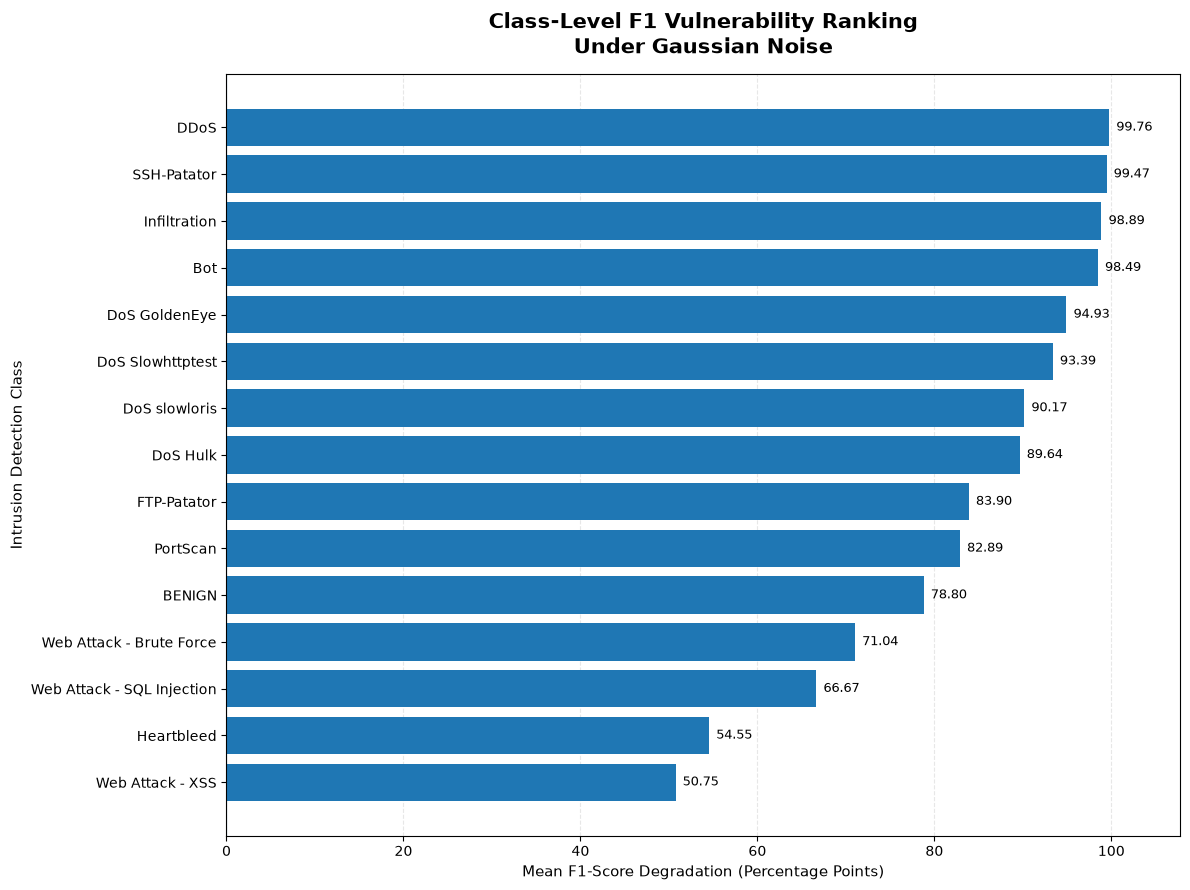

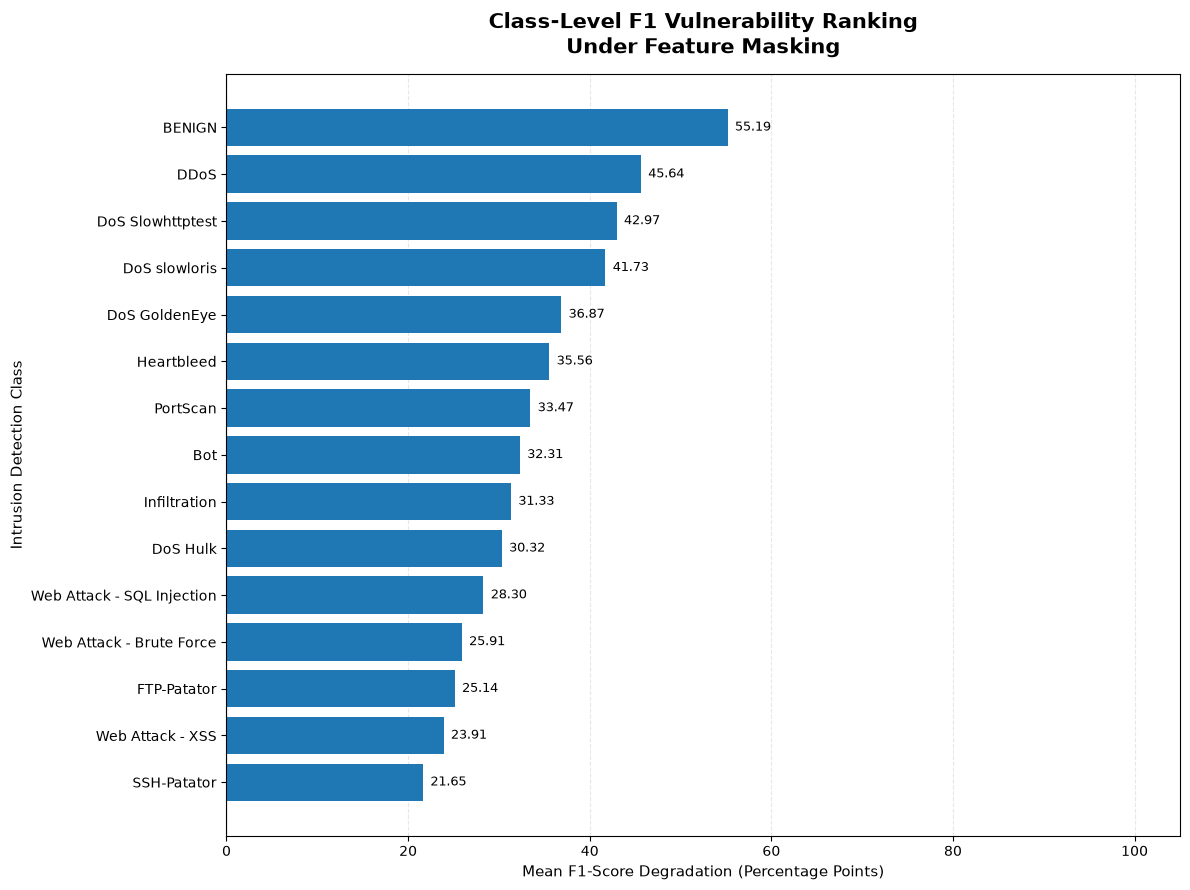

,Verification_Check,Status
0,Gaussian Noise: complete class coverage,PASS
1,Gaussian Noise: correct number of bars,PASS
2,Gaussian Noise: correct rank ordering,PASS
3,Gaussian Noise: plotted values match source,PASS
4,Gaussian Noise: figure saved,PASS
5,Gaussian Noise: 300 DPI resolution,PASS
6,Feature Masking: complete class coverage,PASS
7,Feature Masking: correct number of bars,PASS
8,Feature Masking: correct rank ordering,PASS
9,Feature Masking: plotted values match source,PASS



-----------------------------------------------------------------
F1 VULNERABILITY VISUALIZATION SUMMARY
-----------------------------------------------------------------
Model: LGBMClassifier
Perturbation types: 2
Classes per figure: 15
Total bars generated: 30
Figures generated: 2
Figure resolution: 300 DPI

Saved figures:
06_class_gaussian_f1_vulnerability_ranking.png
06_class_masking_f1_vulnerability_ranking.png

Total checks: 15
Passed checks: 15
Execution time: 7.03 seconds
-----------------------------------------------------------------
Individual F1 vulnerability visualizations: PASS
F1 vulnerability ranking visualization completed.


In [42]:
# Step 15A.3.2 — Individual F1 Vulnerability Rankings

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

start_time = time.time()

print("CLASS-LEVEL F1 VULNERABILITY VISUALIZATION")
print("-" * 65)

# Preserve original DataFrames
gaussian_rank_snapshot = gaussian_class_vulnerability.copy(deep=True)
masking_rank_snapshot = masking_class_vulnerability.copy(deep=True)
combined_rank_snapshot = class_vulnerability_results.copy(deep=True)

# Locate the existing figure directory
existing_heatmaps = list(
    Path.cwd().parent.rglob(
        "06_class_gaussian_recall_heatmap.png"
    )
)

assert len(existing_heatmaps) == 1, (
    "Expected exactly one existing Gaussian recall heatmap. "
    "Please verify the figure directory."
)

vulnerability_figure_dir = existing_heatmaps[0].parent

print(f"Figure directory: {vulnerability_figure_dir}")

# Visualization configurations
ranking_configs = [
    (
        gaussian_class_vulnerability,
        "Gaussian Noise",
        "06_class_gaussian_f1_vulnerability_ranking.png"
    ),
    (
        masking_class_vulnerability,
        "Feature Masking",
        "06_class_masking_f1_vulnerability_ranking.png"
    )
]

vulnerability_figure_records = []

for source_df, perturbation_name, filename in ranking_configs:

    plot_df = source_df.sort_values(
        "F1_Vulnerability_Rank"
    ).copy()

    values = plot_df["Mean_F1_Drop_PP"].to_numpy()
    labels = plot_df["Class_Name"].tolist()

    fig, ax = plt.subplots(figsize=(12, 9))

    bars = ax.barh(labels, values)

    ax.invert_yaxis()

    ax.set_title(
        f"Class-Level F1 Vulnerability Ranking\n"
        f"Under {perturbation_name}",
        fontsize=15,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel(
        "Mean F1-Score Degradation (Percentage Points)",
        fontsize=11
    )

    ax.set_ylabel(
        "Intrusion Detection Class",
        fontsize=11
    )

    ax.axvline(0, linewidth=0.8)

    ax.set_xlim(
        min(0, values.min() - 5),
        max(105, values.max() + 8)
    )

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.3
    )

    ax.set_axisbelow(True)

    # Annotate each bar
    for bar, value in zip(bars, values):

        ax.text(
            value + (0.8 if value >= 0 else -0.8),
            bar.get_y() + bar.get_height() / 2,
            f"{value:.2f}",
            va="center",
            ha="left" if value >= 0 else "right",
            fontsize=9
        )

    plt.tight_layout()

    save_path = vulnerability_figure_dir / filename

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    vulnerability_figure_records.append({
        "Perturbation": perturbation_name,
        "Classes_Visualized": len(labels),
        "Bars_Generated": len(bars),
        "Correct_Rank_Order": (
            plot_df["F1_Vulnerability_Rank"].tolist()
            == list(range(1, 16))
        ),
        "Values_Match": np.allclose(
            [bar.get_width() for bar in bars],
            values
        ),
        "File_Path": save_path
    })

    plt.show()
    plt.close(fig)

# Automated verification
verification_results = []

def record_ranking_check(name, condition):
    verification_results.append({
        "Verification_Check": name,
        "Status": "PASS" if condition else "FAIL"
    })

for record in vulnerability_figure_records:

    name = record["Perturbation"]
    path = record["File_Path"]

    record_ranking_check(
        f"{name}: complete class coverage",
        record["Classes_Visualized"] == 15
    )

    record_ranking_check(
        f"{name}: correct number of bars",
        record["Bars_Generated"] == 15
    )

    record_ranking_check(
        f"{name}: correct rank ordering",
        record["Correct_Rank_Order"]
    )

    record_ranking_check(
        f"{name}: plotted values match source",
        record["Values_Match"]
    )

    record_ranking_check(
        f"{name}: figure saved",
        path.exists() and path.stat().st_size > 0
    )

    valid_resolution = False

    if path.exists():
        with Image.open(path) as img:
            dpi = img.info.get("dpi", (0, 0))
            valid_resolution = all(
                abs(value - 300) < 1 for value in dpi
            )

    record_ranking_check(
        f"{name}: 300 DPI resolution",
        valid_resolution
    )

# Confirm original DataFrames remain unchanged
record_ranking_check(
    "Gaussian ranking unchanged",
    gaussian_class_vulnerability.equals(
        gaussian_rank_snapshot
    )
)

record_ranking_check(
    "Masking ranking unchanged",
    masking_class_vulnerability.equals(
        masking_rank_snapshot
    )
)

record_ranking_check(
    "Combined ranking unchanged",
    class_vulnerability_results.equals(
        combined_rank_snapshot
    )
)

ranking_visualization_verification = pd.DataFrame(
    verification_results
)

display(ranking_visualization_verification)

passed_checks = (
    ranking_visualization_verification["Status"] == "PASS"
).sum()

total_checks = len(ranking_visualization_verification)

ranking_visualization_passed = passed_checks == total_checks

print("\n" + "-" * 65)
print("F1 VULNERABILITY VISUALIZATION SUMMARY")
print("-" * 65)

print("Model: LGBMClassifier")
print("Perturbation types: 2")
print("Classes per figure: 15")
print("Total bars generated: 30")
print("Figures generated: 2")
print("Figure resolution: 300 DPI")

print("\nSaved figures:")

for record in vulnerability_figure_records:
    print(record["File_Path"].name)

print(f"\nTotal checks: {total_checks}")
print(f"Passed checks: {passed_checks}")
print(f"Execution time: {time.time() - start_time:.2f} seconds")

print("-" * 65)

assert ranking_visualization_passed, (
    "F1 vulnerability visualization verification failed."
)

print("Individual F1 vulnerability visualizations: PASS")
print("F1 vulnerability ranking visualization completed.")

SAVED F1 VULNERABILITY FIGURE REVIEW
-----------------------------------------------------------------

Reviewing: 06_class_gaussian_f1_vulnerability_ranking.png


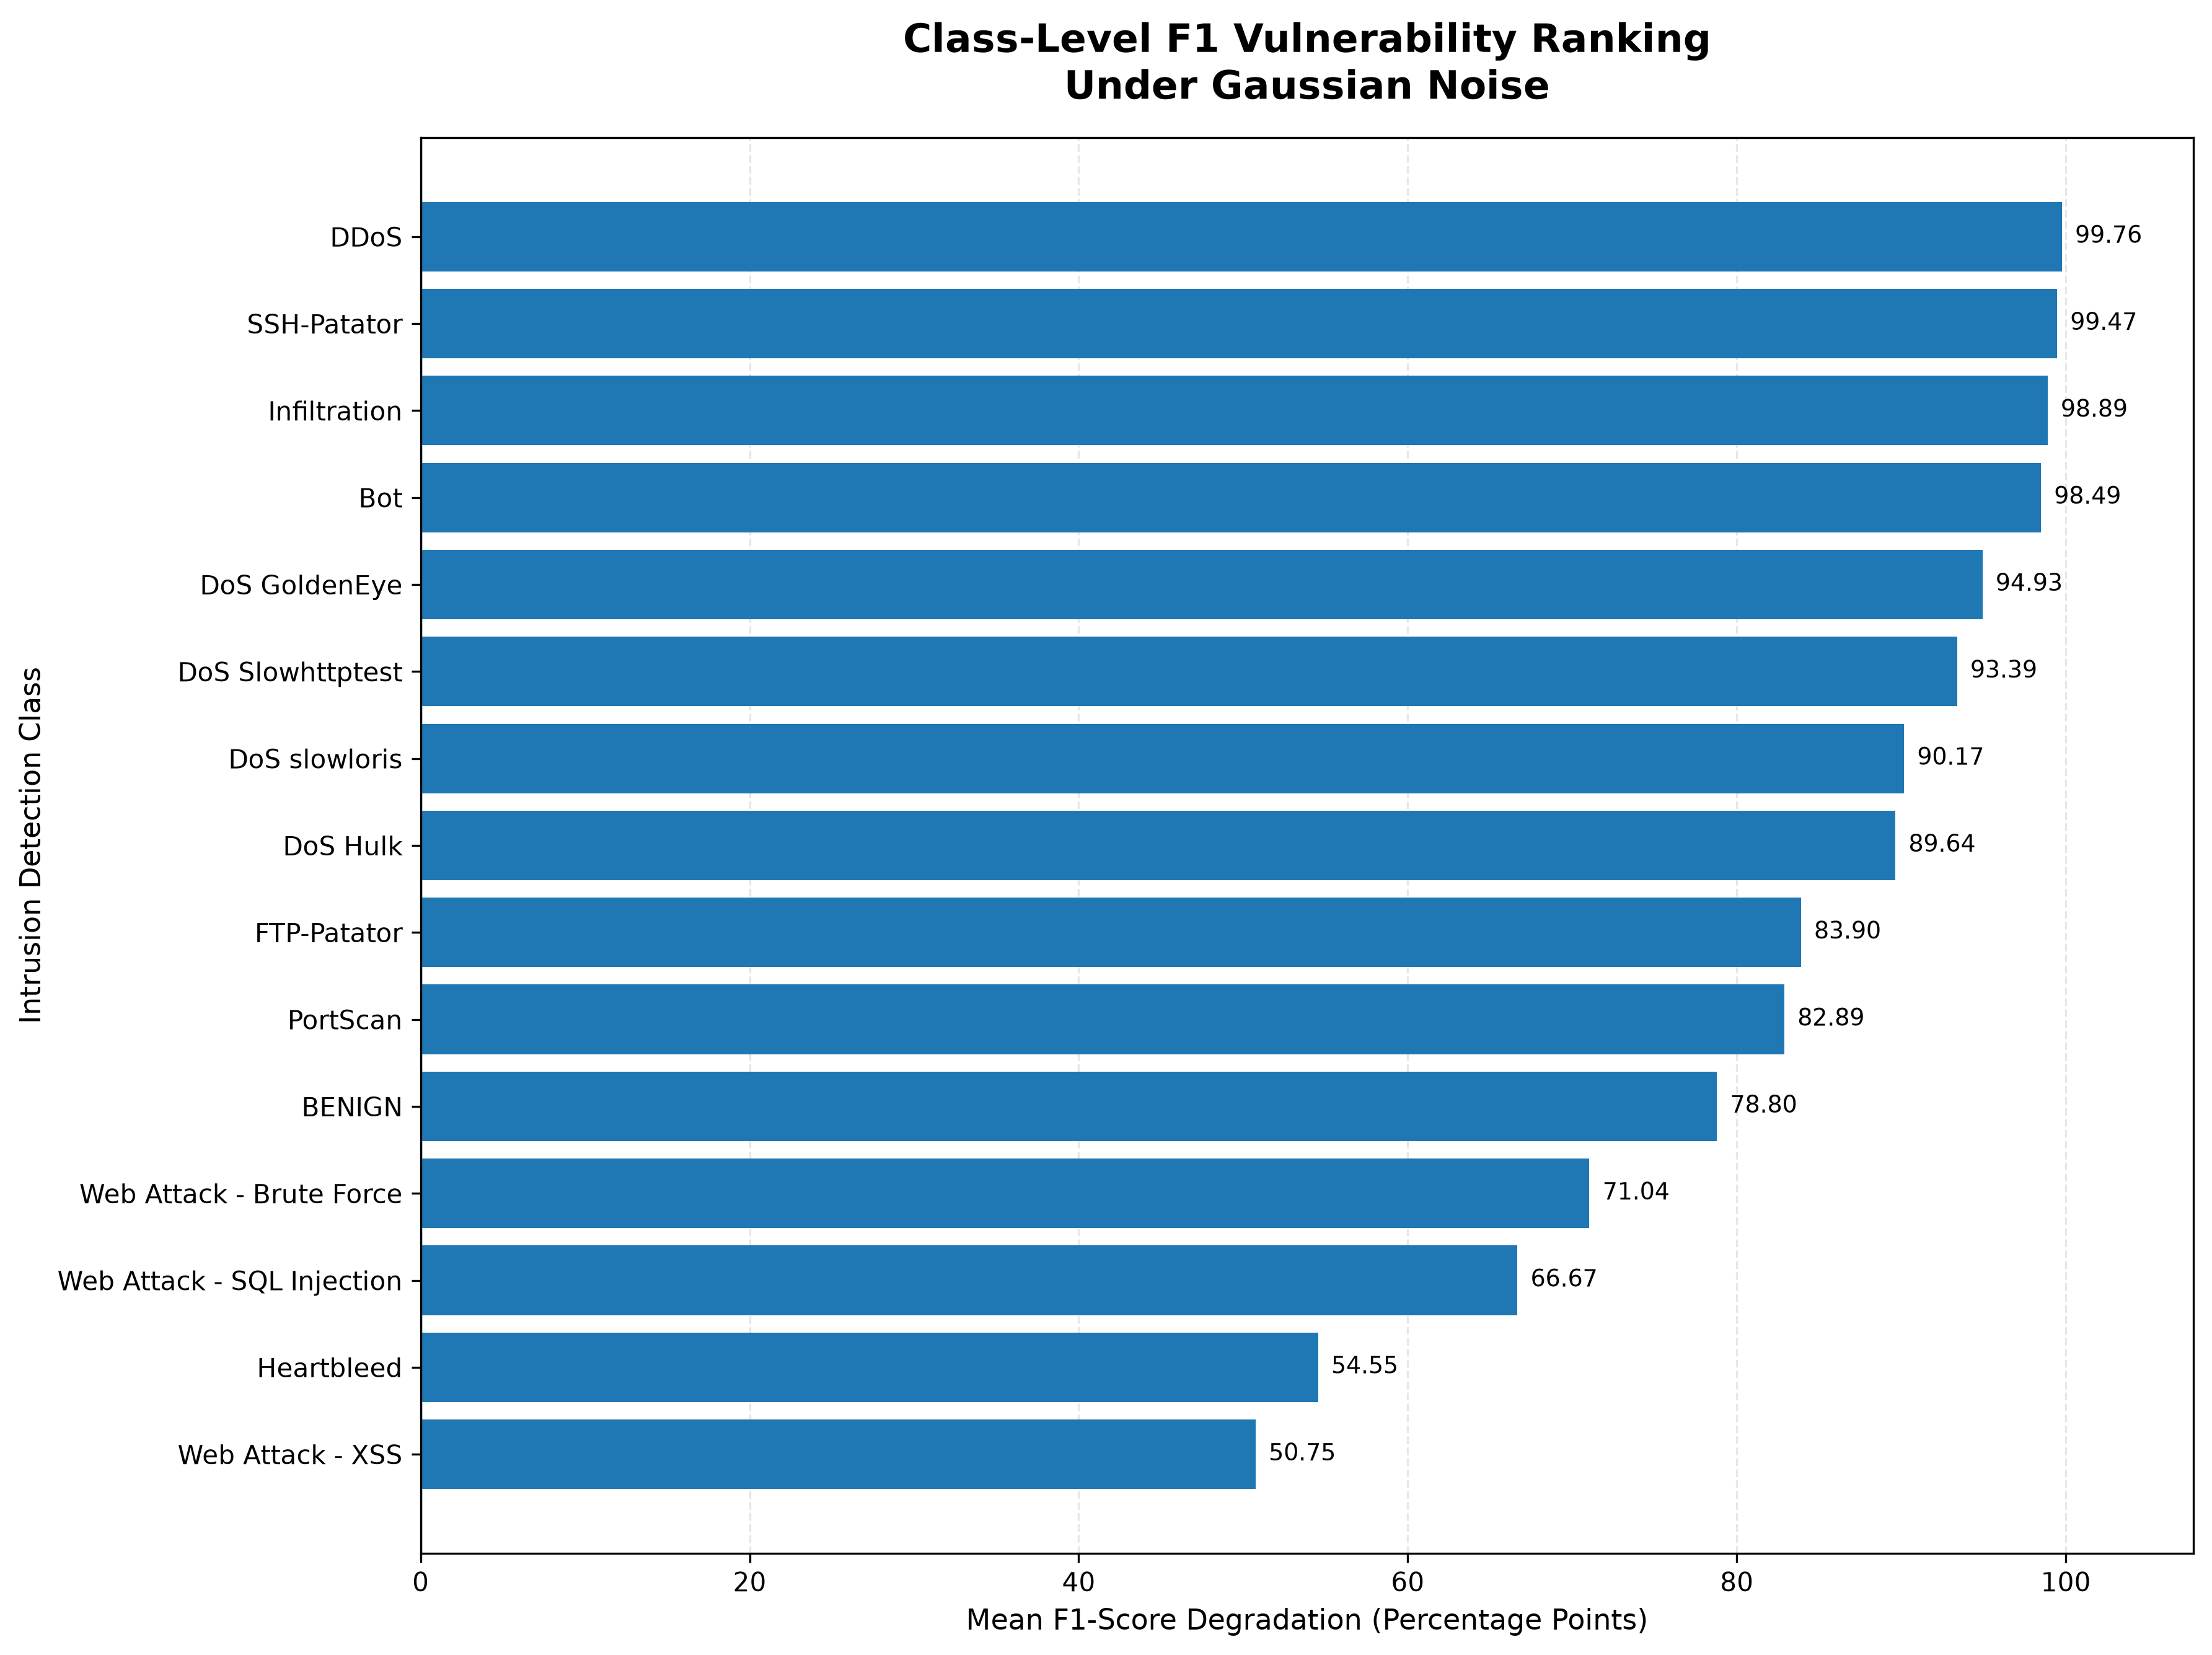


Reviewing: 06_class_masking_f1_vulnerability_ranking.png


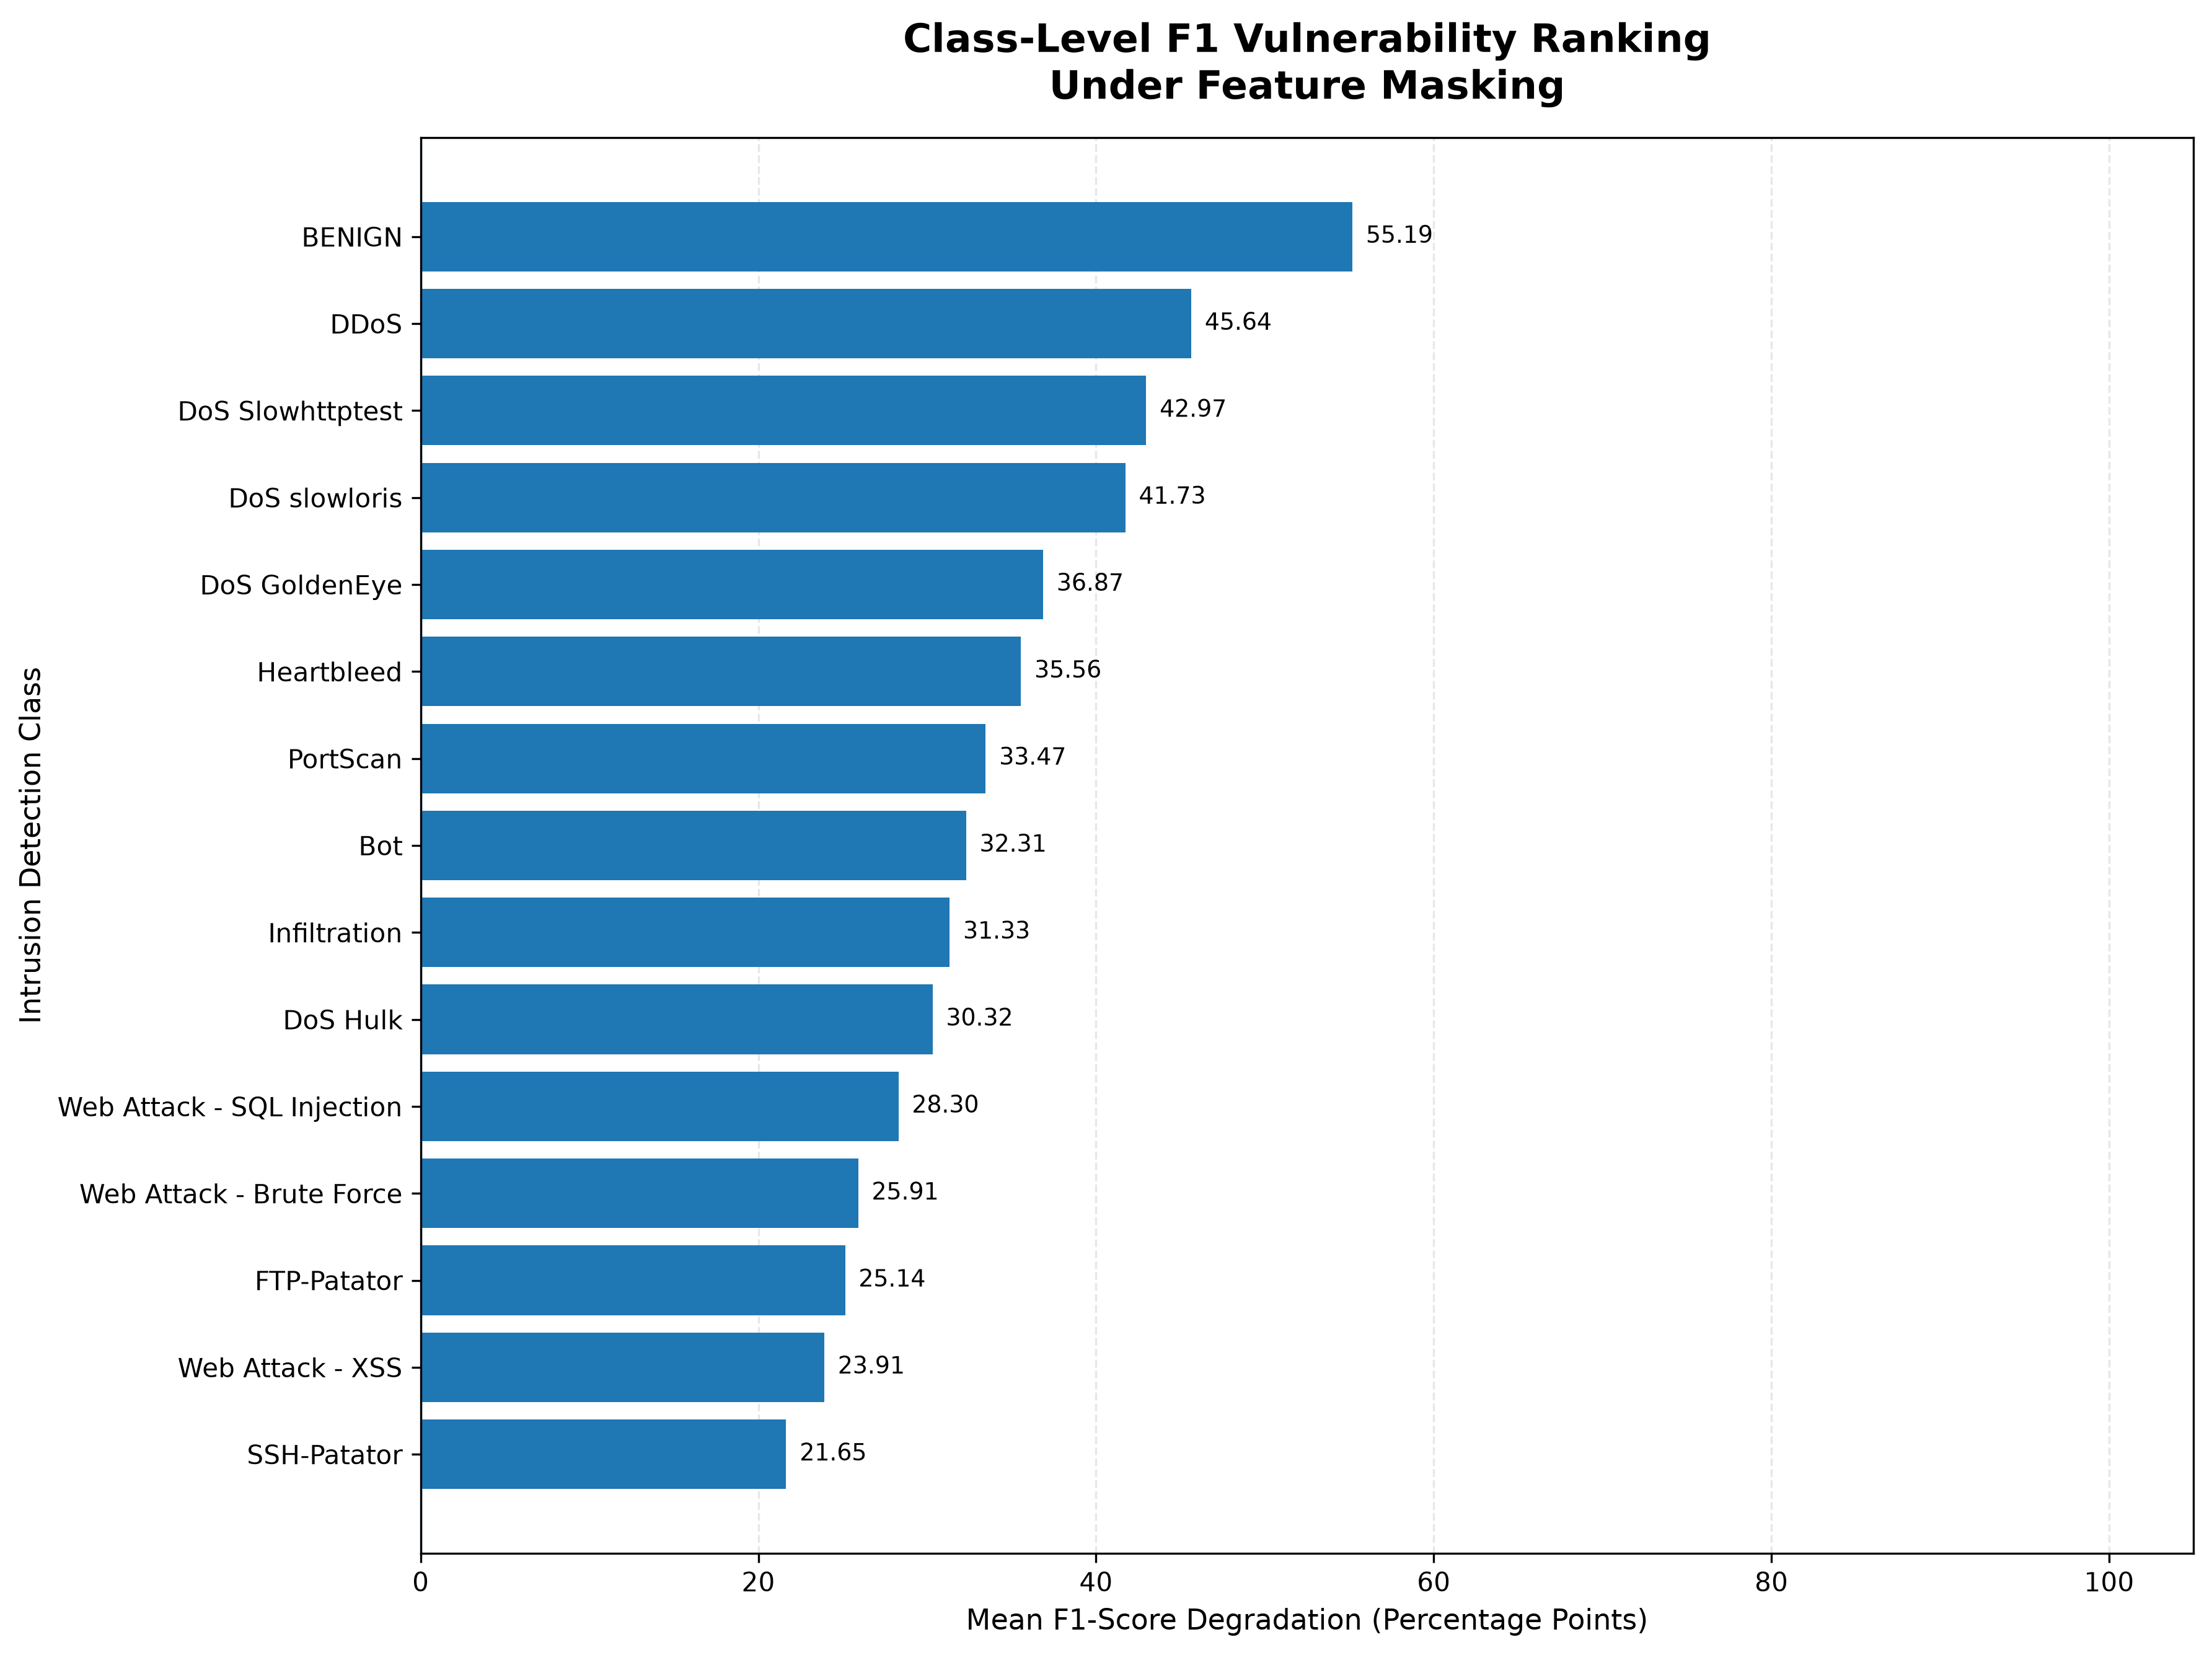


-----------------------------------------------------------------
Saved figures displayed: 2
Saved F1 vulnerability figure review completed.


In [43]:
# Visual inspection of saved F1 vulnerability figures

from IPython.display import display, Image as DisplayImage

f1_ranking_files = [
    "06_class_gaussian_f1_vulnerability_ranking.png",
    "06_class_masking_f1_vulnerability_ranking.png"
]

print("SAVED F1 VULNERABILITY FIGURE REVIEW")
print("-" * 65)

for filename in f1_ranking_files:

    figure_path = vulnerability_figure_dir / filename

    assert figure_path.is_file(), (
        f"Figure not found: {filename}"
    )

    print(f"\nReviewing: {filename}")

    display(
        DisplayImage(
            filename=str(figure_path),
            width=950
        )
    )

print("\n" + "-" * 65)
print("Saved figures displayed: 2")
print("Saved F1 vulnerability figure review completed.")

### Comparative Class-Level F1 Vulnerability Visualization

This analysis compares the mean F1-score degradation
under Gaussian noise and feature masking across all
15 classes to identify perturbation-specific
vulnerabilities in the LightGBM intrusion detection model.

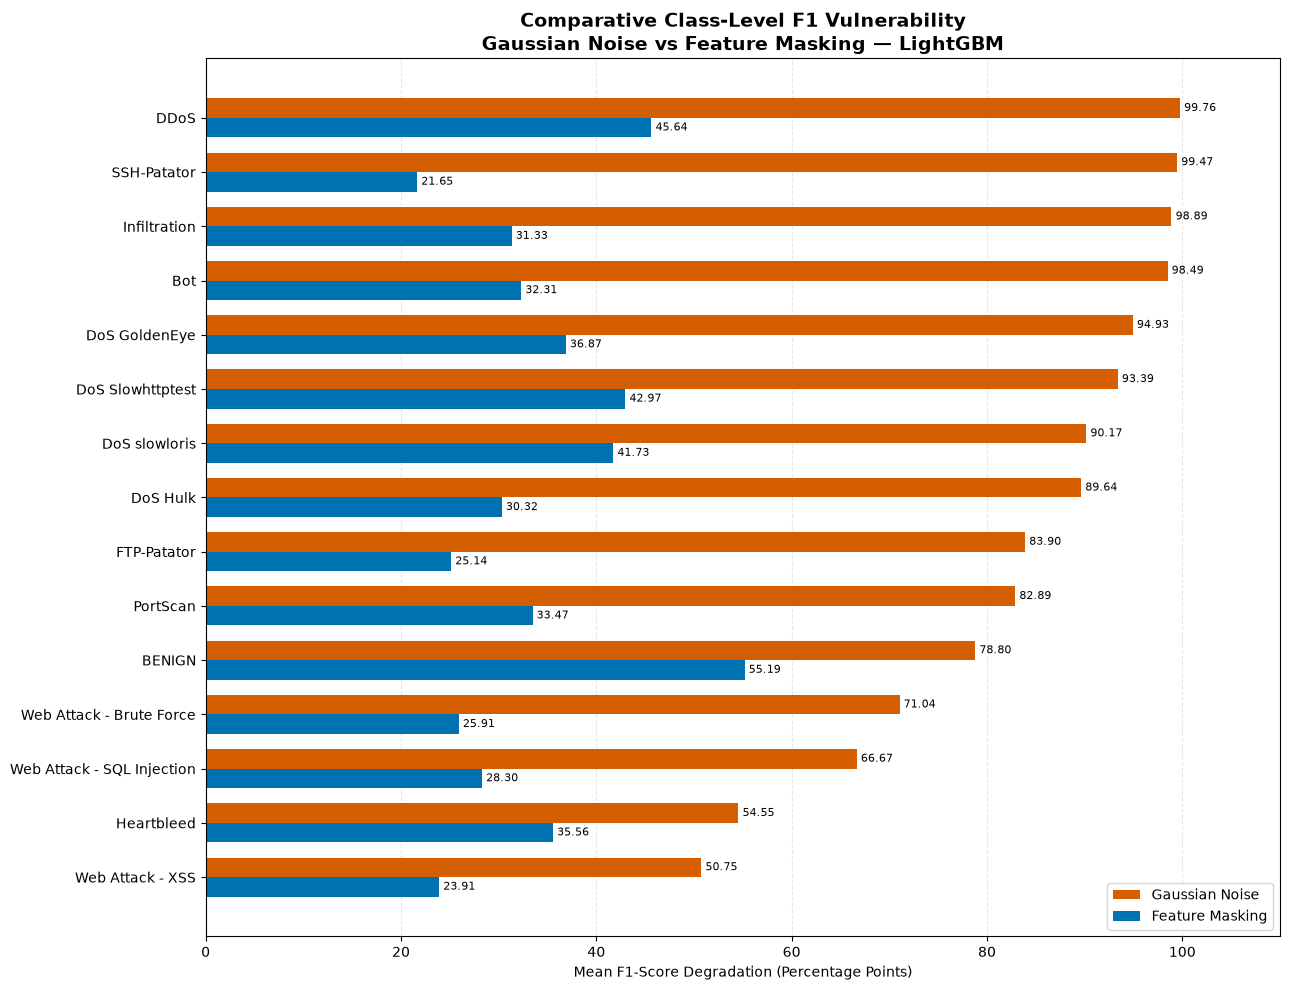

,Verification_Check,Status
0,Complete class coverage,PASS
1,Unique class names,PASS
2,No missing values,PASS
3,Correct Gaussian bar count,PASS
4,Correct masking bar count,PASS
5,Correct rank ordering,PASS
6,Gaussian plotted values match source,PASS
7,Masking plotted values match source,PASS
8,Figure saved,PASS
9,300 DPI resolution,PASS


-----------------------------------------------------------------
COMPARATIVE F1 VULNERABILITY SUMMARY
-----------------------------------------------------------------
Model: LGBMClassifier
Classes compared: 15
Perturbation types: 2
Total bars generated: 30
Figure resolution: 300 DPI
Saved figure: 06_class_comparative_f1_vulnerability.png
Total checks: 12
Passed checks: 12
Execution time: 3.64 seconds
-----------------------------------------------------------------
Comparative F1 vulnerability visualization: PASS
Comparative F1 analysis completed.


In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import time

start_time = time.time()

# Preserve original ranking DataFrames
gaussian_before = gaussian_class_vulnerability.copy(deep=True)
masking_before = masking_class_vulnerability.copy(deep=True)

# Prepare comparative data
comparison_f1 = pd.merge(
    gaussian_class_vulnerability[
        ["Class_Name", "Mean_F1_Drop_PP"]
    ].rename(columns={
        "Mean_F1_Drop_PP": "Gaussian_Noise"
    }),
    masking_class_vulnerability[
        ["Class_Name", "Mean_F1_Drop_PP"]
    ].rename(columns={
        "Mean_F1_Drop_PP": "Feature_Masking"
    }),
    on="Class_Name",
    how="inner",
    validate="one_to_one"
)

# Sort by Gaussian noise vulnerability
comparison_f1 = comparison_f1.sort_values(
    "Gaussian_Noise",
    ascending=False
).reset_index(drop=True)

# Create comparative visualization
y = np.arange(len(comparison_f1))
height = 0.36

fig, ax = plt.subplots(figsize=(13, 10))

bars_gaussian = ax.barh(
    y - height / 2,
    comparison_f1["Gaussian_Noise"],
    height,
    label="Gaussian Noise",
    color="#D55E00"
)

bars_masking = ax.barh(
    y + height / 2,
    comparison_f1["Feature_Masking"],
    height,
    label="Feature Masking",
    color="#0072B2"
)

ax.set_yticks(y)
ax.set_yticklabels(comparison_f1["Class_Name"])
ax.invert_yaxis()

ax.set_xlabel(
    "Mean F1-Score Degradation (Percentage Points)"
)

ax.set_title(
    "Comparative Class-Level F1 Vulnerability\n"
    "Gaussian Noise vs Feature Masking — LightGBM",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlim(
    min(0, comparison_f1[
        ["Gaussian_Noise", "Feature_Masking"]
    ].min().min() - 5),
    110
)

ax.bar_label(bars_gaussian, fmt="%.2f", padding=3, fontsize=8)
ax.bar_label(bars_masking, fmt="%.2f", padding=3, fontsize=8)

ax.legend(loc="lower right")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# Locate previously saved vulnerability figure directory
existing_figures = list(
    Path.cwd().rglob(
        "06_class_gaussian_f1_vulnerability_ranking.png"
    )
)

assert len(existing_figures) == 1, (
    "Expected exactly one existing Gaussian ranking figure."
)

figure_path = existing_figures[0].parent / (
    "06_class_comparative_f1_vulnerability.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Verification
with Image.open(figure_path) as saved_image:
    dpi = saved_image.info.get("dpi", (0, 0))

checks = {
    "Complete class coverage": len(comparison_f1) == 15,
    "Unique class names": comparison_f1["Class_Name"].is_unique,
    "No missing values": not comparison_f1.isna().any().any(),
    "Correct Gaussian bar count": len(bars_gaussian) == 15,
    "Correct masking bar count": len(bars_masking) == 15,
    "Correct rank ordering": comparison_f1[
        "Gaussian_Noise"
    ].is_monotonic_decreasing,
    "Gaussian plotted values match source": np.allclose(
        [bar.get_width() for bar in bars_gaussian],
        comparison_f1["Gaussian_Noise"]
    ),
    "Masking plotted values match source": np.allclose(
        [bar.get_width() for bar in bars_masking],
        comparison_f1["Feature_Masking"]
    ),
    "Figure saved": figure_path.is_file(),
    "300 DPI resolution": all(
        abs(value - 300) < 1 for value in dpi
    ),
    "Gaussian ranking unchanged": (
        gaussian_class_vulnerability.equals(gaussian_before)
    ),
    "Masking ranking unchanged": (
        masking_class_vulnerability.equals(masking_before)
    )
}

verification = pd.DataFrame({
    "Verification_Check": list(checks.keys()),
    "Status": [
        "PASS" if result else "FAIL"
        for result in checks.values()
    ]
})

display(verification)

print("-" * 65)
print("COMPARATIVE F1 VULNERABILITY SUMMARY")
print("-" * 65)
print("Model: LGBMClassifier")
print("Classes compared:", len(comparison_f1))
print("Perturbation types: 2")
print("Total bars generated:", len(bars_gaussian) + len(bars_masking))
print("Figure resolution: 300 DPI")
print("Saved figure:", figure_path.name)
print("Total checks:", len(checks))
print("Passed checks:", sum(checks.values()))
print(f"Execution time: {time.time() - start_time:.2f} seconds")

assert all(checks.values()), (
    "Comparative F1 visualization verification failed."
)

print("-" * 65)
print("Comparative F1 vulnerability visualization: PASS")
print("Comparative F1 analysis completed.")

### Comparative Class-Level Recall Vulnerability Visualization

This analysis compares mean recall degradation under
Gaussian noise and feature masking across all 15 classes
to evaluate the sensitivity of the LightGBM intrusion
detection model to input perturbations.

The analysis complements F1-score vulnerability assessment
by examining the model's ability to correctly identify
instances belonging to each traffic class.

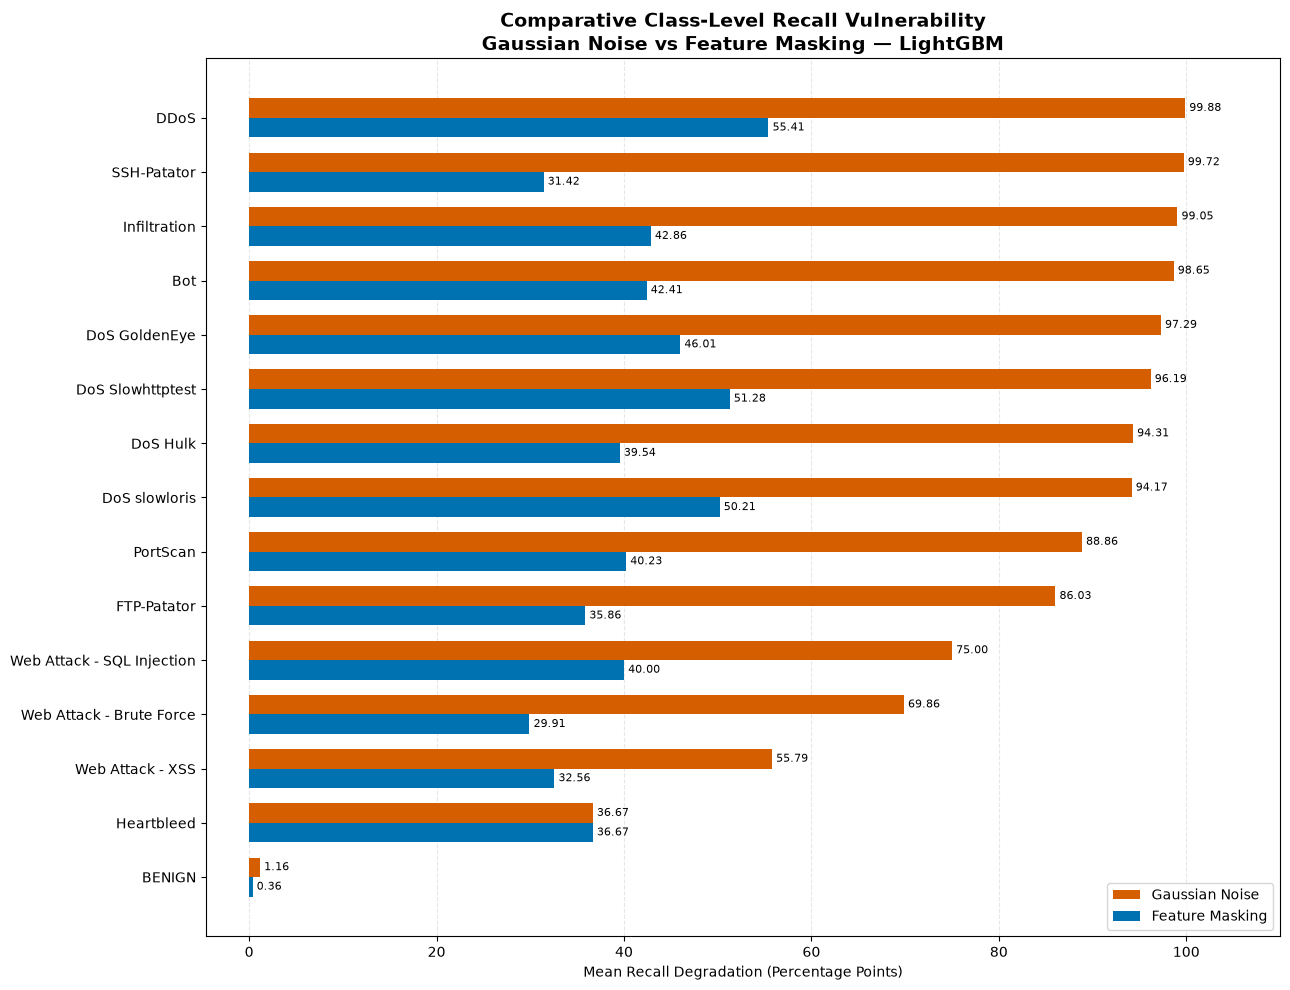

,Verification_Check,Status
0,Complete class coverage,PASS
1,Unique class names,PASS
2,No missing values,PASS
3,Correct Gaussian bar count,PASS
4,Correct masking bar count,PASS
5,Correct rank ordering,PASS
6,Gaussian plotted values match source,PASS
7,Masking plotted values match source,PASS
8,Figure saved,PASS
9,300 DPI resolution,PASS


-----------------------------------------------------------------
COMPARATIVE RECALL VULNERABILITY SUMMARY
-----------------------------------------------------------------
Model: LGBMClassifier
Classes compared: 15
Perturbation types: 2
Total bars generated: 30
Figure resolution: 300 DPI
Saved figure: 06_class_comparative_recall_vulnerability.png
Total checks: 12
Passed checks: 12
Execution time: 3.74 seconds
-----------------------------------------------------------------
Comparative recall vulnerability visualization: PASS
Comparative recall analysis completed.


In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import time

start_time = time.time()

# Preserve original ranking DataFrames
gaussian_recall_before = gaussian_class_vulnerability.copy(deep=True)
masking_recall_before = masking_class_vulnerability.copy(deep=True)

# Prepare comparative recall data
comparison_recall = pd.merge(
    gaussian_class_vulnerability[
        ["Class_Name", "Mean_Recall_Drop_PP"]
    ].rename(columns={
        "Mean_Recall_Drop_PP": "Gaussian_Noise"
    }),
    masking_class_vulnerability[
        ["Class_Name", "Mean_Recall_Drop_PP"]
    ].rename(columns={
        "Mean_Recall_Drop_PP": "Feature_Masking"
    }),
    on="Class_Name",
    how="inner",
    validate="one_to_one"
)

# Sort by Gaussian recall vulnerability
comparison_recall = comparison_recall.sort_values(
    "Gaussian_Noise",
    ascending=False
).reset_index(drop=True)

# Create comparative visualization
y = np.arange(len(comparison_recall))
height = 0.36

fig, ax = plt.subplots(figsize=(13, 10))

bars_gaussian = ax.barh(
    y - height / 2,
    comparison_recall["Gaussian_Noise"],
    height,
    label="Gaussian Noise",
    color="#D55E00"
)

bars_masking = ax.barh(
    y + height / 2,
    comparison_recall["Feature_Masking"],
    height,
    label="Feature Masking",
    color="#0072B2"
)

ax.set_yticks(y)
ax.set_yticklabels(comparison_recall["Class_Name"])
ax.invert_yaxis()

ax.set_xlabel(
    "Mean Recall Degradation (Percentage Points)"
)

ax.set_title(
    "Comparative Class-Level Recall Vulnerability\n"
    "Gaussian Noise vs Feature Masking — LightGBM",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlim(
    min(0, comparison_recall[
        ["Gaussian_Noise", "Feature_Masking"]
    ].min().min() - 5),
    110
)

ax.bar_label(
    bars_gaussian,
    fmt="%.2f",
    padding=3,
    fontsize=8
)

ax.bar_label(
    bars_masking,
    fmt="%.2f",
    padding=3,
    fontsize=8
)

ax.legend(loc="lower right")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# Locate existing comparative F1 figure
existing_figures = list(
    Path.cwd().rglob(
        "06_class_comparative_f1_vulnerability.png"
    )
)

assert len(existing_figures) == 1, (
    "Expected exactly one comparative F1 figure."
)

recall_figure_path = existing_figures[0].parent / (
    "06_class_comparative_recall_vulnerability.png"
)

fig.savefig(
    recall_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Verify saved resolution
with Image.open(recall_figure_path) as saved_image:
    dpi = saved_image.info.get("dpi", (0, 0))

# Verification checks
recall_checks = {
    "Complete class coverage": len(comparison_recall) == 15,

    "Unique class names":
        comparison_recall["Class_Name"].is_unique,

    "No missing values":
        not comparison_recall.isna().any().any(),

    "Correct Gaussian bar count":
        len(bars_gaussian) == 15,

    "Correct masking bar count":
        len(bars_masking) == 15,

    "Correct rank ordering":
        comparison_recall[
            "Gaussian_Noise"
        ].is_monotonic_decreasing,

    "Gaussian plotted values match source":
        np.allclose(
            [bar.get_width() for bar in bars_gaussian],
            comparison_recall["Gaussian_Noise"]
        ),

    "Masking plotted values match source":
        np.allclose(
            [bar.get_width() for bar in bars_masking],
            comparison_recall["Feature_Masking"]
        ),

    "Figure saved":
        recall_figure_path.is_file(),

    "300 DPI resolution":
        all(abs(value - 300) < 1 for value in dpi),

    "Gaussian ranking unchanged":
        gaussian_class_vulnerability.equals(
            gaussian_recall_before
        ),

    "Masking ranking unchanged":
        masking_class_vulnerability.equals(
            masking_recall_before
        )
}

recall_verification = pd.DataFrame({
    "Verification_Check": list(recall_checks.keys()),
    "Status": [
        "PASS" if result else "FAIL"
        for result in recall_checks.values()
    ]
})

display(recall_verification)

print("-" * 65)
print("COMPARATIVE RECALL VULNERABILITY SUMMARY")
print("-" * 65)

print("Model: LGBMClassifier")
print("Classes compared:", len(comparison_recall))
print("Perturbation types: 2")
print("Total bars generated:", len(bars_gaussian) + len(bars_masking))
print("Figure resolution: 300 DPI")
print("Saved figure:", recall_figure_path.name)
print("Total checks:", len(recall_checks))
print("Passed checks:", sum(recall_checks.values()))
print(f"Execution time: {time.time() - start_time:.2f} seconds")

assert all(recall_checks.values()), (
    "Comparative recall visualization verification failed."
)

print("-" * 65)
print("Comparative recall vulnerability visualization: PASS")
print("Comparative recall analysis completed.")

### Export Class-Level Vulnerability Results

The class-level vulnerability rankings and comparative
F1-score and recall degradation results are exported
as CSV files to support reproducibility, independent
analysis, and research documentation.

All exported files are verified against their original
DataFrames to ensure data integrity and completeness.

In [47]:
import pandas as pd
import numpy as np
from pathlib import Path
import time

start_time = time.time()

# Preserve source DataFrames
export_sources = {
    "06_class_gaussian_vulnerability.csv":
        gaussian_class_vulnerability,

    "06_class_masking_vulnerability.csv":
        masking_class_vulnerability,

    "06_class_combined_vulnerability.csv":
        class_vulnerability_results,

    "06_class_comparative_f1_vulnerability.csv":
        comparison_f1,

    "06_class_comparative_recall_vulnerability.csv":
        comparison_recall
}

source_snapshots = {
    name: df.copy(deep=True)
    for name, df in export_sources.items()
}

# Create export directory
export_dir = Path.cwd() / "results" / "robustness"

export_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Expected dimensions
expected_shapes = {
    "06_class_gaussian_vulnerability.csv": (15, 16),
    "06_class_masking_vulnerability.csv": (15, 16),
    "06_class_combined_vulnerability.csv": (30, 16),
    "06_class_comparative_f1_vulnerability.csv": (15, 3),
    "06_class_comparative_recall_vulnerability.csv": (15, 3)
}

export_records = []
export_checks = {}

# Export and verify each file
for filename, source_df in export_sources.items():

    file_path = export_dir / filename

    source_df.to_csv(
        file_path,
        index=False,
        encoding="utf-8"
    )

    loaded_df = pd.read_csv(file_path)

    # Verify numerical and categorical values
    try:
        pd.testing.assert_frame_equal(
            source_df.reset_index(drop=True),
            loaded_df,
            check_dtype=False,
            check_exact=False,
            rtol=1e-10,
            atol=1e-12
        )
        values_match = True

    except AssertionError:
        values_match = False

    checks = {
        "File exists": file_path.is_file(),

        "Expected dimensions":
            loaded_df.shape == expected_shapes[filename],

        "Column names preserved":
            list(loaded_df.columns) ==
            list(source_df.columns),

        "Exported values match source":
            values_match,

        "Original DataFrame unchanged":
            source_df.equals(source_snapshots[filename])
    }

    for check_name, result in checks.items():
        export_checks[
            f"{filename}: {check_name}"
        ] = result

    export_records.append({
        "File_Name": filename,
        "Rows": loaded_df.shape[0],
        "Columns": loaded_df.shape[1],
        "Size_Bytes": file_path.stat().st_size,
        "Status": "PASS" if all(checks.values()) else "FAIL"
    })

# Display export inventory
export_inventory = pd.DataFrame(export_records)

display(export_inventory)

# Display verification results
export_verification = pd.DataFrame({
    "Verification_Check": list(export_checks.keys()),
    "Status": [
        "PASS" if result else "FAIL"
        for result in export_checks.values()
    ]
})

display(export_verification)

print("-" * 65)
print("CLASS-LEVEL VULNERABILITY EXPORT SUMMARY")
print("-" * 65)

print("Model: LGBMClassifier")
print("Files exported:", len(export_records))
print("Total rows exported:", export_inventory["Rows"].sum())
print("Export format: CSV")
print("Export directory:", export_dir.resolve())
print("Total checks:", len(export_checks))
print("Passed checks:", sum(export_checks.values()))
print(f"Execution time: {time.time() - start_time:.2f} seconds")

assert all(export_checks.values()), (
    "Class-level vulnerability export verification failed."
)

print("-" * 65)
print("Class-level vulnerability export: PASS")
print("Vulnerability results export completed.")

,File_Name,Rows,Columns,Size_Bytes,Status
0,06_class_gaussian_vulnerability.csv,15,16,3552,PASS
1,06_class_masking_vulnerability.csv,15,16,3752,PASS
2,06_class_combined_vulnerability.csv,30,16,7006,PASS
3,06_class_comparative_f1_vulnerability.csv,15,3,804,PASS
4,06_class_comparative_recall_vulnerability.csv,15,3,728,PASS


,Verification_Check,Status
0,06_class_gaussian_vulnerability.csv: File exists,PASS
1,06_class_gaussian_vulnerability.csv: Expected ...,PASS
2,06_class_gaussian_vulnerability.csv: Column na...,PASS
3,06_class_gaussian_vulnerability.csv: Exported ...,PASS
4,06_class_gaussian_vulnerability.csv: Original ...,PASS
5,06_class_masking_vulnerability.csv: File exists,PASS
6,06_class_masking_vulnerability.csv: Expected d...,PASS
7,06_class_masking_vulnerability.csv: Column nam...,PASS
8,06_class_masking_vulnerability.csv: Exported v...,PASS
9,06_class_masking_vulnerability.csv: Original D...,PASS


-----------------------------------------------------------------
CLASS-LEVEL VULNERABILITY EXPORT SUMMARY
-----------------------------------------------------------------
Model: LGBMClassifier
Files exported: 5
Total rows exported: 90
Export format: CSV
Export directory: C:\Users\pc\XAI-Intrusion-Detection\results\robustness
Total checks: 25
Passed checks: 25
Execution time: 0.08 seconds
-----------------------------------------------------------------
Class-level vulnerability export: PASS
Vulnerability results export completed.


### Final Verification and Research Findings

This section consolidates the class-level robustness
and reliability findings for the LightGBM intrusion
detection model under Gaussian noise and feature masking.

The exported numerical results and vulnerability
visualizations are verified for completeness and
consistency.

The findings highlight class-specific performance
degradation, perturbation sensitivity, and limitations
of relying exclusively on clean-data performance
when evaluating intrusion detection systems.

In [48]:
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image
import time

start_time = time.time()

print("=" * 70)
print("FINAL ROBUSTNESS AND RELIABILITY VERIFICATION")
print("=" * 70)

final_checks = {}

# 1. Verify class-level matrices
matrices = {
    "Gaussian F1": gaussian_f1_snapshot,
    "Masking F1": masking_f1_snapshot,
    "Gaussian Recall": gaussian_recall_snapshot,
    "Masking Recall": masking_recall_snapshot
}

for name, matrix in matrices.items():

    final_checks[f"{name}: complete dimensions"] = (
        matrix.shape == (15, 6)
    )

    final_checks[f"{name}: finite values"] = (
        np.isfinite(matrix.to_numpy()).all()
    )

    final_checks[f"{name}: valid metric range"] = (
        ((matrix >= 0) & (matrix <= 1)).all().all()
    )

# 2. Verify vulnerability rankings
final_checks["Gaussian ranking complete"] = (
    gaussian_class_vulnerability.shape == (15, 16)
)

final_checks["Masking ranking complete"] = (
    masking_class_vulnerability.shape == (15, 16)
)

final_checks["Combined ranking complete"] = (
    class_vulnerability_results.shape == (30, 16)
)

final_checks["Comparative F1 complete"] = (
    comparison_f1.shape == (15, 3)
)

final_checks["Comparative recall complete"] = (
    comparison_recall.shape == (15, 3)
)

# 3. Verify exported CSV files
for filename, source_df in export_sources.items():

    file_path = export_dir / filename

    final_checks[f"{filename}: exists"] = (
        file_path.is_file()
    )

    if file_path.is_file():

        loaded_df = pd.read_csv(file_path)

        try:
            pd.testing.assert_frame_equal(
                source_df.reset_index(drop=True),
                loaded_df,
                check_dtype=False,
                check_exact=False,
                rtol=1e-10,
                atol=1e-12
            )

            values_match = True

        except AssertionError:
            values_match = False

        final_checks[f"{filename}: integrity"] = (
            values_match
        )

    else:
        final_checks[f"{filename}: integrity"] = False

# 4. Verify vulnerability figures
expected_figures = [
    "06_class_gaussian_f1_vulnerability_ranking.png",
    "06_class_masking_f1_vulnerability_ranking.png",
    "06_class_comparative_f1_vulnerability.png",
    "06_class_comparative_recall_vulnerability.png"
]

for filename in expected_figures:

    matches = list(Path.cwd().rglob(filename))

    final_checks[f"{filename}: exists uniquely"] = (
        len(matches) == 1
    )

    if len(matches) == 1:

        with Image.open(matches[0]) as image:

            dpi = image.info.get("dpi", (0, 0))

            final_checks[f"{filename}: 300 DPI"] = (
                all(abs(value - 300) < 1 for value in dpi)
            )

    else:
        final_checks[f"{filename}: 300 DPI"] = False

# 5. Display final verification
final_verification = pd.DataFrame({
    "Verification_Check": list(final_checks.keys()),
    "Status": [
        "PASS" if result else "FAIL"
        for result in final_checks.values()
    ]
})

display(final_verification)

assert all(final_checks.values()), (
    "Final robustness verification failed."
)

# 6. Extract research findings
findings = []

for perturbation, ranking in [
    ("Gaussian Noise", gaussian_class_vulnerability),
    ("Feature Masking", masking_class_vulnerability)
]:

    for metric in ["F1", "Recall"]:

        drop_column = f"Mean_{metric}_Drop_PP"

        ordered = ranking.sort_values(
            drop_column,
            ascending=False
        )

        most_vulnerable = ordered.iloc[0]
        least_vulnerable = ordered.iloc[-1]

        findings.append({
            "Perturbation": perturbation,
            "Metric": metric,
            "Most_Vulnerable_Class":
                most_vulnerable["Class_Name"],
            "Highest_Mean_Drop_PP":
                most_vulnerable[drop_column],
            "Least_Vulnerable_Class":
                least_vulnerable["Class_Name"],
            "Lowest_Mean_Drop_PP":
                least_vulnerable[drop_column],
            "Average_Class_Drop_PP":
                ranking[drop_column].mean()
        })

robustness_findings = pd.DataFrame(findings)

print("\nKEY RESEARCH FINDINGS")
print("-" * 70)

display(robustness_findings.round(4))

# 7. Export final verification and findings
verification_path = (
    export_dir / "06_final_robustness_verification.csv"
)

findings_path = (
    export_dir / "06_final_robustness_findings.csv"
)

final_verification.to_csv(
    verification_path,
    index=False
)

robustness_findings.to_csv(
    findings_path,
    index=False
)

# Verify final exports
for source, path in [
    (final_verification, verification_path),
    (robustness_findings, findings_path)
]:

    pd.testing.assert_frame_equal(
        source.reset_index(drop=True),
        pd.read_csv(path),
        check_dtype=False,
        check_exact=False,
        rtol=1e-10,
        atol=1e-12
    )

# 8. Final summary
print("=" * 70)
print("NOTEBOOK 06 — FINAL SUMMARY")
print("=" * 70)

print("Model: LGBMClassifier")
print("Classes analysed: 15")
print("Perturbation types: 2")
print("Class-level matrices verified: 4")
print("Vulnerability ranking datasets: 3")
print("Comparative datasets: 2")
print("Vulnerability figures verified: 4")
print("Vulnerability CSV files verified: 5")
print("Additional summary files exported: 2")
print("Total verification checks:", len(final_checks))
print("Passed checks:", sum(final_checks.values()))
print("Failed checks:", len(final_checks) - sum(final_checks.values()))

print(
    f"Execution time: {time.time() - start_time:.2f} seconds"
)

print("=" * 70)
print("FINAL ROBUSTNESS VERIFICATION: PASS")
print("NOTEBOOK 06 COMPUTATIONAL ANALYSIS COMPLETED")
print("=" * 70)

FINAL ROBUSTNESS AND RELIABILITY VERIFICATION


,Verification_Check,Status
0,Gaussian F1: complete dimensions,PASS
1,Gaussian F1: finite values,PASS
2,Gaussian F1: valid metric range,PASS
3,Masking F1: complete dimensions,PASS
4,Masking F1: finite values,PASS
5,Masking F1: valid metric range,PASS
6,Gaussian Recall: complete dimensions,PASS
7,Gaussian Recall: finite values,PASS
8,Gaussian Recall: valid metric range,PASS
9,Masking Recall: complete dimensions,PASS



KEY RESEARCH FINDINGS
----------------------------------------------------------------------


,Perturbation,Metric,Most_Vulnerable_Class,Highest_Mean_Drop_PP,Least_Vulnerable_Class,Lowest_Mean_Drop_PP,Average_Class_Drop_PP
0,Gaussian Noise,F1,DDoS,99.7618,Web Attack - XSS,50.7536,83.5553
1,Gaussian Noise,Recall,DDoS,99.8800,BENIGN,1.1600,79.5087
2,Feature Masking,F1,BENIGN,55.1850,SSH-Patator,21.6503,34.0186
3,Feature Masking,Recall,DDoS,55.4133,BENIGN,0.3600,38.3146


NOTEBOOK 06 — FINAL SUMMARY
Model: LGBMClassifier
Classes analysed: 15
Perturbation types: 2
Class-level matrices verified: 4
Vulnerability ranking datasets: 3
Comparative datasets: 2
Vulnerability figures verified: 4
Vulnerability CSV files verified: 5
Additional summary files exported: 2
Total verification checks: 35
Passed checks: 35
Failed checks: 0
Execution time: 4.95 seconds
FINAL ROBUSTNESS VERIFICATION: PASS
NOTEBOOK 06 COMPUTATIONAL ANALYSIS COMPLETED


## Final Research Conclusion

### Overview

This notebook investigated the robustness and reliability of the LightGBM-based intrusion detection model across 15 network traffic classes under two input perturbation conditions: Gaussian noise and feature masking. The analysis evaluated performance degradation using class-level F1-scores and recall, supported by heatmaps, vulnerability rankings, and comparative visualizations.

### Key Research Findings

#### 1. Sensitivity to Gaussian Noise

Gaussian noise produced substantial performance degradation across the evaluated classes. The average class-level F1-score and recall reductions were 83.56 and 79.51 percentage points, respectively.

DDoS was identified as the most vulnerable class for both metrics, with mean F1-score degradation of 99.76 percentage points and mean recall degradation of 99.88 percentage points.

These findings demonstrate that the model is highly sensitive to the Gaussian noise conditions evaluated in this experiment.

#### 2. Sensitivity to Feature Masking

Feature masking also negatively affected model performance, although the observed average degradation was lower than that recorded under Gaussian noise.

The average class-level F1-score reduction was 34.02 percentage points, while the average recall reduction was 38.31 percentage points.

BENIGN exhibited the highest mean F1-score degradation of 55.19 percentage points, whereas DDoS recorded the highest mean recall degradation of 55.41 percentage points.

The relatively stable recall of the BENIGN class, alongside its substantial F1-score degradation, suggests a deterioration in precision and warrants further investigation into false-positive classifications.

#### 3. Class-Level Vulnerability

The results demonstrate that robustness is not uniform across network traffic classes. Different classes exhibited varying degrees of sensitivity depending on the perturbation type and evaluation metric.

DDoS emerged as a particularly vulnerable class, ranking highest in three of the four vulnerability comparisons.

Furthermore, classes with relatively small absolute performance reductions should not automatically be considered robust, particularly when their baseline performance is already low.

#### 4. Comparative Robustness

Under the experimental conditions investigated, Gaussian noise resulted in greater average class-level performance degradation than feature masking.

However, the two perturbation mechanisms operate differently and their severity levels are not directly equivalent. Consequently, this comparison should be interpreted within the specific experimental settings rather than generalized to all possible noise and missing-feature scenarios.

### Practical Cybersecurity Implications

The findings highlight several important considerations for deploying machine learning-based intrusion detection systems:

- High baseline performance alone is insufficient to establish operational reliability.
- Input corruption and missing network features can substantially compromise threat detection.
- Class-level evaluation is necessary to identify vulnerabilities that aggregate performance metrics may conceal.
- Significant recall degradation may increase the risk of malicious network activity remaining undetected.
- Robust preprocessing, input validation, perturbation-aware training, and continuous performance monitoring should be investigated as potential mitigation strategies.

### Experimental Verification and Reproducibility

The final computational verification successfully passed all 35 checks, with zero failures.

Class-level performance matrices, vulnerability rankings, comparative datasets, saved visualizations, and exported CSV files were verified for consistency.

These verification results establish the internal consistency of the computational outputs but do not independently establish the operational robustness or external validity of the model.

### Research Limitations

The robustness findings are limited to the selected model, evaluation dataset, perturbation mechanisms, and tested severity levels.

Synthetic perturbations may not fully represent the complexity of real-world network conditions. Further evaluation using independent datasets, realistic network disturbances, and additional robustness techniques is necessary before drawing broader deployment conclusions.

### Conclusion

The robustness and reliability analysis demonstrates that strong baseline intrusion detection performance can deteriorate substantially when input features are corrupted or partially unavailable.

The observed class-specific vulnerabilities emphasize the importance of evaluating machine learning-based cybersecurity systems beyond conventional performance metrics.

Overall, the findings support the need for more robust, explainable, and reliable intrusion detection systems capable of maintaining dependable performance under changing and imperfect network conditions.

This notebook establishes an empirical foundation for further investigation into trustworthy machine learning for cybersecurity.